# APT Attack Analysis on Linux Systems

This notebook analyzes the Linux APT (Advanced Persistent Threat) attack dataset to:
1. Preprocess the data
2. Extract relevant fields (timestamp, agent ID, logs, MITRE tactics/techniques)
3. Sort events chronologically and group by host
4. Filter events with MITRE ATT&CK information
5. Build an attack sequence graph showing the progression of attacks

#### trying to understand data from cell [1] to [25]

In [2]:
# Import necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import networkx as nx
from datetime import datetime
import warnings
warnings.filterwarnings('ignore')

# Set display options
pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', 100)

print("Libraries imported successfully!")

Libraries imported successfully!


## Step 1: Load and Explore the Dataset

In [4]:
# Load the dataset with error handling for malformed lines
data_path = r'Linux-APT-Dataset-2024\combine.csv'
print("Loading dataset...")
# Use on_bad_lines='skip' to skip malformed lines
df = pd.read_csv(data_path, on_bad_lines='skip', encoding='utf-8', engine='python')

print(f"Dataset loaded successfully!")
print(f"Shape: {df.shape}")
print(f"\nNumber of rows: {df.shape[0]:,}")
print(f"Number of columns: {df.shape[1]:,}")

Loading dataset...
Dataset loaded successfully!
Shape: (91133, 123)

Number of rows: 91,133
Number of columns: 123


In [3]:
# Display basic information about the dataset
print("First few rows:")
print(df.head(3))
print("\n" + "="*100 + "\n")
print("Column names:")
print(df.columns.tolist())

First few rows:
                        _index                   _id _version _score  \
0  wazuh-alerts-4.x-2023.10.01  NpG26IoBagxmxR-sfnEo        1      1   
1  wazuh-alerts-4.x-2023.10.01  OZG26IoBagxmxR-sfnE7        1      1   
2  wazuh-alerts-4.x-2023.10.01  O5G26IoBagxmxR-sfnE7        1      1   

  _source.agent.name _source.agent.id _source.manager.name _source.data.file  \
0             ubuntu                0               ubuntu         /bin/diff   
1             ubuntu                0               ubuntu                     
2             ubuntu                0               ubuntu                     

                   _source.data.title _source.rule.firedtimes  \
0  Trojaned version of file detected.                       1   
1                                                           2   
2                                                           4   

  _source.rule.mail _source.rule.level _source.rule.pci_dss  \
0             FALSE                  7           [

## Step 2: Data Preprocessing

Extract relevant fields and handle missing values

In [4]:
# Define the columns we need to extract
required_columns = [
    '_source.@timestamp',
    '_source.agent.id',
    '_source.agent.name',
    '_source.full_log',
    '_source.rule.mitre_tactics',
    '_source.rule.mitre_techniques',
    '_source.rule.description',
    '_source.rule.id',
    '_source.rule.level',
    '_source.rule.groups'
]

# Check which columns exist in the dataset
existing_columns = [col for col in required_columns if col in df.columns]
missing_columns = [col for col in required_columns if col not in df.columns]

print(f"Existing columns: {len(existing_columns)}/{len(required_columns)}")
print(f"\nMissing columns: {missing_columns}")

# Extract the relevant columns
df_filtered = df[existing_columns].copy()
print(f"\nFiltered dataset shape: {df_filtered.shape}")

Existing columns: 10/10

Missing columns: []

Filtered dataset shape: (91133, 10)


In [5]:
# Check for missing values
print("Missing values in each column:")
print(df_filtered.isnull().sum())
print(f"\nTotal missing values: {df_filtered.isnull().sum().sum():,}")

# Check data types
print("\n" + "="*100)
print("\nData types:")
print(df_filtered.dtypes)

Missing values in each column:
_source.@timestamp                   0
_source.agent.id                     0
_source.agent.name                   0
_source.full_log                     0
_source.rule.mitre_tactics       19575
_source.rule.mitre_techniques    19575
_source.rule.description             0
_source.rule.id                      0
_source.rule.level                   0
_source.rule.groups                  0
dtype: int64

Total missing values: 39,150


Data types:
_source.@timestamp               object
_source.agent.id                 object
_source.agent.name               object
_source.full_log                 object
_source.rule.mitre_tactics       object
_source.rule.mitre_techniques    object
_source.rule.description         object
_source.rule.id                  object
_source.rule.level               object
_source.rule.groups              object
dtype: object
_source.@timestamp                   0
_source.agent.id                     0
_source.agent.name            

In [6]:
# Parse timestamp column with the correct format
# Format is: "Oct 1, 2023 @ 00:49:18.889"
def parse_custom_timestamp(ts_str):
    try:
        # Remove the @ symbol and parse
        cleaned = ts_str.replace(' @ ', ' ')
        return pd.to_datetime(cleaned, format='%b %d, %Y %H:%M:%S.%f')
    except:
        return pd.NaT

df_filtered['timestamp_parsed'] = df_filtered['_source.@timestamp'].apply(parse_custom_timestamp)

# Check if parsing was successful
print(f"Successfully parsed timestamps: {df_filtered['timestamp_parsed'].notna().sum():,}")
print(f"Failed to parse: {df_filtered['timestamp_parsed'].isna().sum():,}")

# Display date range
print(f"\nDate range:")
print(f"First event: {df_filtered['timestamp_parsed'].min()}")
print(f"Last event: {df_filtered['timestamp_parsed'].max()}")
print(f"Duration: {df_filtered['timestamp_parsed'].max() - df_filtered['timestamp_parsed'].min()}")

Successfully parsed timestamps: 819
Failed to parse: 90,314

Date range:
First event: 2023-10-01 00:49:18.889000
Last event: 2023-10-05 18:29:07.427000
Duration: 4 days 17:39:48.538000


In [7]:
# Check the timestamp format
print("Sample timestamp values:")
print(df_filtered['_source.@timestamp'].head(10))
print("\nUnique formats:", df_filtered['_source.@timestamp'].apply(lambda x: type(x).__name__).value_counts())

Sample timestamp values:
0    Oct 1, 2023 @ 00:49:18.889
1    Oct 1, 2023 @ 00:49:29.255
2    Oct 1, 2023 @ 00:49:29.276
3    Oct 1, 2023 @ 00:49:29.299
4    Oct 1, 2023 @ 00:49:29.308
5    Oct 1, 2023 @ 00:49:29.339
6    Oct 1, 2023 @ 00:49:29.361
7    Oct 1, 2023 @ 00:49:29.372
8    Oct 1, 2023 @ 00:49:29.382
9    Oct 1, 2023 @ 00:49:29.392
Name: _source.@timestamp, dtype: object

Unique formats: _source.@timestamp
str    91133
Name: count, dtype: int64


## Step 3: Filter Events with MITRE ATT&CK Information

Focus on events that contain MITRE tactics or techniques (actual attack indicators)

In [8]:
# Filter to only events with MITRE tactics or techniques
df_mitre = df_filtered[
    (df_filtered['_source.rule.mitre_tactics'].notna()) | 
    (df_filtered['_source.rule.mitre_techniques'].notna())
].copy()

print(f"Total events: {len(df_filtered):,}")
print(f"Events with MITRE data: {len(df_mitre):,}")
print(f"Percentage: {len(df_mitre)/len(df_filtered)*100:.2f}%")

# Check the distribution
print("\n" + "="*100)
print("\nMITRE Tactics distribution:")
print(df_mitre['_source.rule.mitre_tactics'].value_counts().head(10))
print("\n" + "="*100)
print("\nMITRE Techniques distribution:")
print(df_mitre['_source.rule.mitre_techniques'].value_counts().head(10))

Total events: 91,133
Events with MITRE data: 71,558
Percentage: 78.52%


MITRE Tactics distribution:
_source.rule.mitre_tactics
                        20776
4294967295               9598
0                        6508
-ignore_readdir_race      309
--query                   261
20                        226
rc-local.service          189
4                         179
--                        135
["TA0005"]                125
Name: count, dtype: int64


MITRE Techniques distribution:
_source.rule.mitre_techniques
                            32925
0                           13622
/var/log/audit/audit.log     9367
137                          1377
-2                           1174
-lname                        309
path                          261
/var/log/dpkg.log             226
--property=ActiveState        187
-g                            168
Name: count, dtype: int64
_source.rule.mitre_tactics
                        20776
4294967295               9598
0                        6508


In [9]:
# Clean MITRE data - filter only valid MITRE ATT&CK identifiers
# Valid tactics start with "TA" and techniques start with "T" followed by numbers
def is_valid_mitre_tactic(value):
    if pd.isna(value):
        return False
    value_str = str(value).strip()
    # Check if it's a list format or starts with TA
    return 'TA' in value_str or value_str.startswith('[')

def is_valid_mitre_technique(value):
    if pd.isna(value):
        return False
    value_str = str(value).strip()
    # Check if it contains T followed by digits or is in list format
    return ('T' in value_str and any(c.isdigit() for c in value_str)) or value_str.startswith('[')

# Apply filters
df_mitre_clean = df_mitre[
    df_mitre['_source.rule.mitre_tactics'].apply(is_valid_mitre_tactic) | 
    df_mitre['_source.rule.mitre_techniques'].apply(is_valid_mitre_technique)
].copy()

print(f"Events after cleaning MITRE data: {len(df_mitre_clean):,}")
print(f"Removed {len(df_mitre) - len(df_mitre_clean):,} invalid entries")

# Update df_mitre to use the cleaned version
df_mitre = df_mitre_clean.copy()

Events after cleaning MITRE data: 348
Removed 71,210 invalid entries


## Step 4: Sort by Timestamp and Group by Agent

Create timeline of events per host

In [10]:
# Sort by timestamp ascending (chronological order)
df_sorted = df_mitre.sort_values('timestamp_parsed', ascending=True).reset_index(drop=True)

print(f"Events sorted chronologically: {len(df_sorted):,}")
print(f"\nNumber of unique agents/hosts: {df_sorted['_source.agent.id'].nunique()}")
print(f"\nAgent distribution:")
print(df_sorted['_source.agent.id'].value_counts())

# Display the first few events
print("\n" + "="*100)
print("\nFirst 5 events (chronologically):")
print(df_sorted[['timestamp_parsed', '_source.agent.id', '_source.agent.name', 
                 '_source.rule.mitre_tactics', '_source.rule.mitre_techniques']].head())

Events sorted chronologically: 348

Number of unique agents/hosts: 3

Agent distribution:
_source.agent.id
1                174
0                173
Machine-1-New      1
Name: count, dtype: int64


First 5 events (chronologically):
         timestamp_parsed _source.agent.id _source.agent.name  \
0 2023-10-01 00:49:29.245                0             ubuntu   
1 2023-10-01 00:49:29.255                0             ubuntu   
2 2023-10-01 00:49:29.266                0             ubuntu   
3 2023-10-01 00:49:29.276                0             ubuntu   
4 2023-10-01 00:49:29.287                0             ubuntu   

  _source.rule.mitre_tactics _source.rule.mitre_techniques  
0                 ["TA0005"]         ["T1499","T1499.001"]  
1                 ["TA0005"]                     ["T1200"]  
2                 ["TA0005"]         ["T1204","T1204.002"]  
3                 ["TA0005"]         ["T1548","T1548.001"]  
4                 ["TA0006"]         ["T1499","T1499.001"]  


In [11]:
# Group by agent to see attack timeline per host
grouped_by_agent = df_sorted.groupby('_source.agent.id')

print("Attack statistics per agent:")
print("="*100)

for agent_id, agent_data in grouped_by_agent:
    agent_name = agent_data['_source.agent.name'].iloc[0] if '_source.agent.name' in agent_data.columns else 'Unknown'
    print(f"\nAgent ID: {agent_id} ({agent_name})")
    print(f"  Total events: {len(agent_data)}")
    print(f"  Time range: {agent_data['timestamp_parsed'].min()} to {agent_data['timestamp_parsed'].max()}")
    print(f"  Duration: {agent_data['timestamp_parsed'].max() - agent_data['timestamp_parsed'].min()}")
    print(f"  Unique tactics: {agent_data['_source.rule.mitre_tactics'].nunique()}")
    print(f"  Unique techniques: {agent_data['_source.rule.mitre_techniques'].nunique()}")

Attack statistics per agent:

Agent ID: 0 (ubuntu)
  Total events: 173
  Time range: 2023-10-01 00:49:29.245000 to 2023-10-04 17:21:43.010000
  Duration: 3 days 16:32:13.765000
  Unique tactics: 16
  Unique techniques: 52

Agent ID: 1 (machine-1)
  Total events: 174
  Time range: 2023-10-04 17:44:59.073000 to 2023-10-05 18:28:58.093000
  Duration: 1 days 00:43:59.020000
  Unique tactics: 16
  Unique techniques: 52

Agent ID: Machine-1-New (192.168.217.133)
  Total events: 1
  Time range: NaT to NaT
  Duration: NaT
  Unique tactics: 1
  Unique techniques: 1


## Step 5: Prepare Data for Attack Sequence Graph

Parse MITRE tactics and techniques to build the attack chain

In [12]:
# Function to parse MITRE fields (they might be in list format as strings)
import ast

def parse_mitre_field(value):
    """Parse MITRE field which might be a string representation of a list"""
    if pd.isna(value):
        return []
    if isinstance(value, str):
        # Try to parse as list
        if value.startswith('[') and value.endswith(']'):
            try:
                return ast.literal_eval(value)
            except:
                return [value]
        return [value]
    return [value]

# Parse MITRE tactics and techniques
df_sorted['tactics_list'] = df_sorted['_source.rule.mitre_tactics'].apply(parse_mitre_field)
df_sorted['techniques_list'] = df_sorted['_source.rule.mitre_techniques'].apply(parse_mitre_field)

# Display some examples
print("Sample parsed MITRE data:")
print(df_sorted[['_source.rule.mitre_tactics', 'tactics_list', 
                 '_source.rule.mitre_techniques', 'techniques_list']].head(10))

Sample parsed MITRE data:
  _source.rule.mitre_tactics tactics_list _source.rule.mitre_techniques  \
0                 ["TA0005"]     [TA0005]         ["T1499","T1499.001"]   
1                 ["TA0005"]     [TA0005]                     ["T1200"]   
2                 ["TA0005"]     [TA0005]         ["T1204","T1204.002"]   
3                 ["TA0005"]     [TA0005]         ["T1548","T1548.001"]   
4                 ["TA0006"]     [TA0006]         ["T1499","T1499.001"]   
5                 ["TA0005"]     [TA0005]                     ["T1200"]   
6                 ["TA0005"]     [TA0005]         ["T1548","T1548.001"]   
7                 ["TA0005"]     [TA0005]         ["T1499","T1499.001"]   
8                 ["TA0005"]     [TA0005]         ["T1204","T1204.002"]   
9                 ["TA0005"]     [TA0005]         ["T1548","T1548.001"]   

      techniques_list  
0  [T1499, T1499.001]  
1             [T1200]  
2  [T1204, T1204.002]  
3  [T1548, T1548.001]  
4  [T1499, T1499.001]  
5   

In [13]:
# Create a comprehensive event list with all details
attack_events = []

for idx, row in df_sorted.iterrows():
    for tactic in row['tactics_list']:
        for technique in row['techniques_list']:
            attack_events.append({
                'timestamp': row['timestamp_parsed'],
                'agent_id': row['_source.agent.id'],
                'agent_name': row['_source.agent.name'],
                'tactic': tactic,
                'technique': technique,
                'description': row['_source.rule.description'],
                'full_log': row['_source.full_log'],
                'rule_id': row['_source.rule.id'],
                'rule_level': row['_source.rule.level']
            })

df_events = pd.DataFrame(attack_events)
df_events = df_events.sort_values('timestamp').reset_index(drop=True)

print(f"Total attack events (expanded): {len(df_events):,}")
print(f"\nUnique tactics: {df_events['tactic'].nunique()}")
print(f"Unique techniques: {df_events['technique'].nunique()}")
print("\n" + "="*100)
print("\nFirst 10 attack events:")
print(df_events[['timestamp', 'agent_name', 'tactic', 'technique', 'description']].head(10))

Total attack events (expanded): 994

Unique tactics: 13
Unique techniques: 72


First 10 attack events:
                timestamp agent_name  tactic  technique  \
0 2023-10-01 00:49:29.245     ubuntu  TA0005      T1499   
1 2023-10-01 00:49:29.245     ubuntu  TA0005  T1499.001   
2 2023-10-01 00:49:29.255     ubuntu  TA0005      T1200   
3 2023-10-01 00:49:29.266     ubuntu  TA0005      T1204   
4 2023-10-01 00:49:29.266     ubuntu  TA0005  T1204.002   
5 2023-10-01 00:49:29.276     ubuntu  TA0005      T1548   
6 2023-10-01 00:49:29.276     ubuntu  TA0005  T1548.001   
7 2023-10-01 00:49:29.287     ubuntu  TA0006      T1499   
8 2023-10-01 00:49:29.287     ubuntu  TA0006  T1499.001   
9 2023-10-01 00:49:29.299     ubuntu  TA0005      T1200   

                                                                                description  
0         CIS Ubuntu Linux 22.04 LTS Benchmark v1.0.0: Ensure /tmp is a separate partition.  
1         CIS Ubuntu Linux 22.04 LTS Benchmark v1.0.0: Ens

## Step 6: Build Attack Sequence Graph

Create a directed graph showing the progression of attacks through MITRE ATT&CK tactics and techniques

In [14]:
# Create a graph showing the sequence of attacks
G = nx.DiGraph()

# Build the graph based on temporal sequence per agent
for agent_id in df_events['agent_id'].unique():
    agent_events = df_events[df_events['agent_id'] == agent_id].sort_values('timestamp')
    
    # Create edges between consecutive events
    for i in range(len(agent_events) - 1):
        current = agent_events.iloc[i]
        next_event = agent_events.iloc[i + 1]
        
        # Create node labels
        current_node = f"{current['tactic']}\n{current['technique']}"
        next_node = f"{next_event['tactic']}\n{next_event['technique']}"
        
        # Add nodes with attributes
        G.add_node(current_node, tactic=current['tactic'], technique=current['technique'])
        G.add_node(next_node, tactic=next_event['tactic'], technique=next_event['technique'])
        
        # Add edge with weight (number of times this transition occurs)
        if G.has_edge(current_node, next_node):
            G[current_node][next_node]['weight'] += 1
        else:
            G.add_edge(current_node, next_node, weight=1)

print(f"Graph Statistics:")
print(f"  Nodes (unique tactic-technique pairs): {G.number_of_nodes()}")
print(f"  Edges (transitions): {G.number_of_edges()}")
print(f"  Is directed: {G.is_directed()}")

Graph Statistics:
  Nodes (unique tactic-technique pairs): 142
  Edges (transitions): 422
  Is directed: True


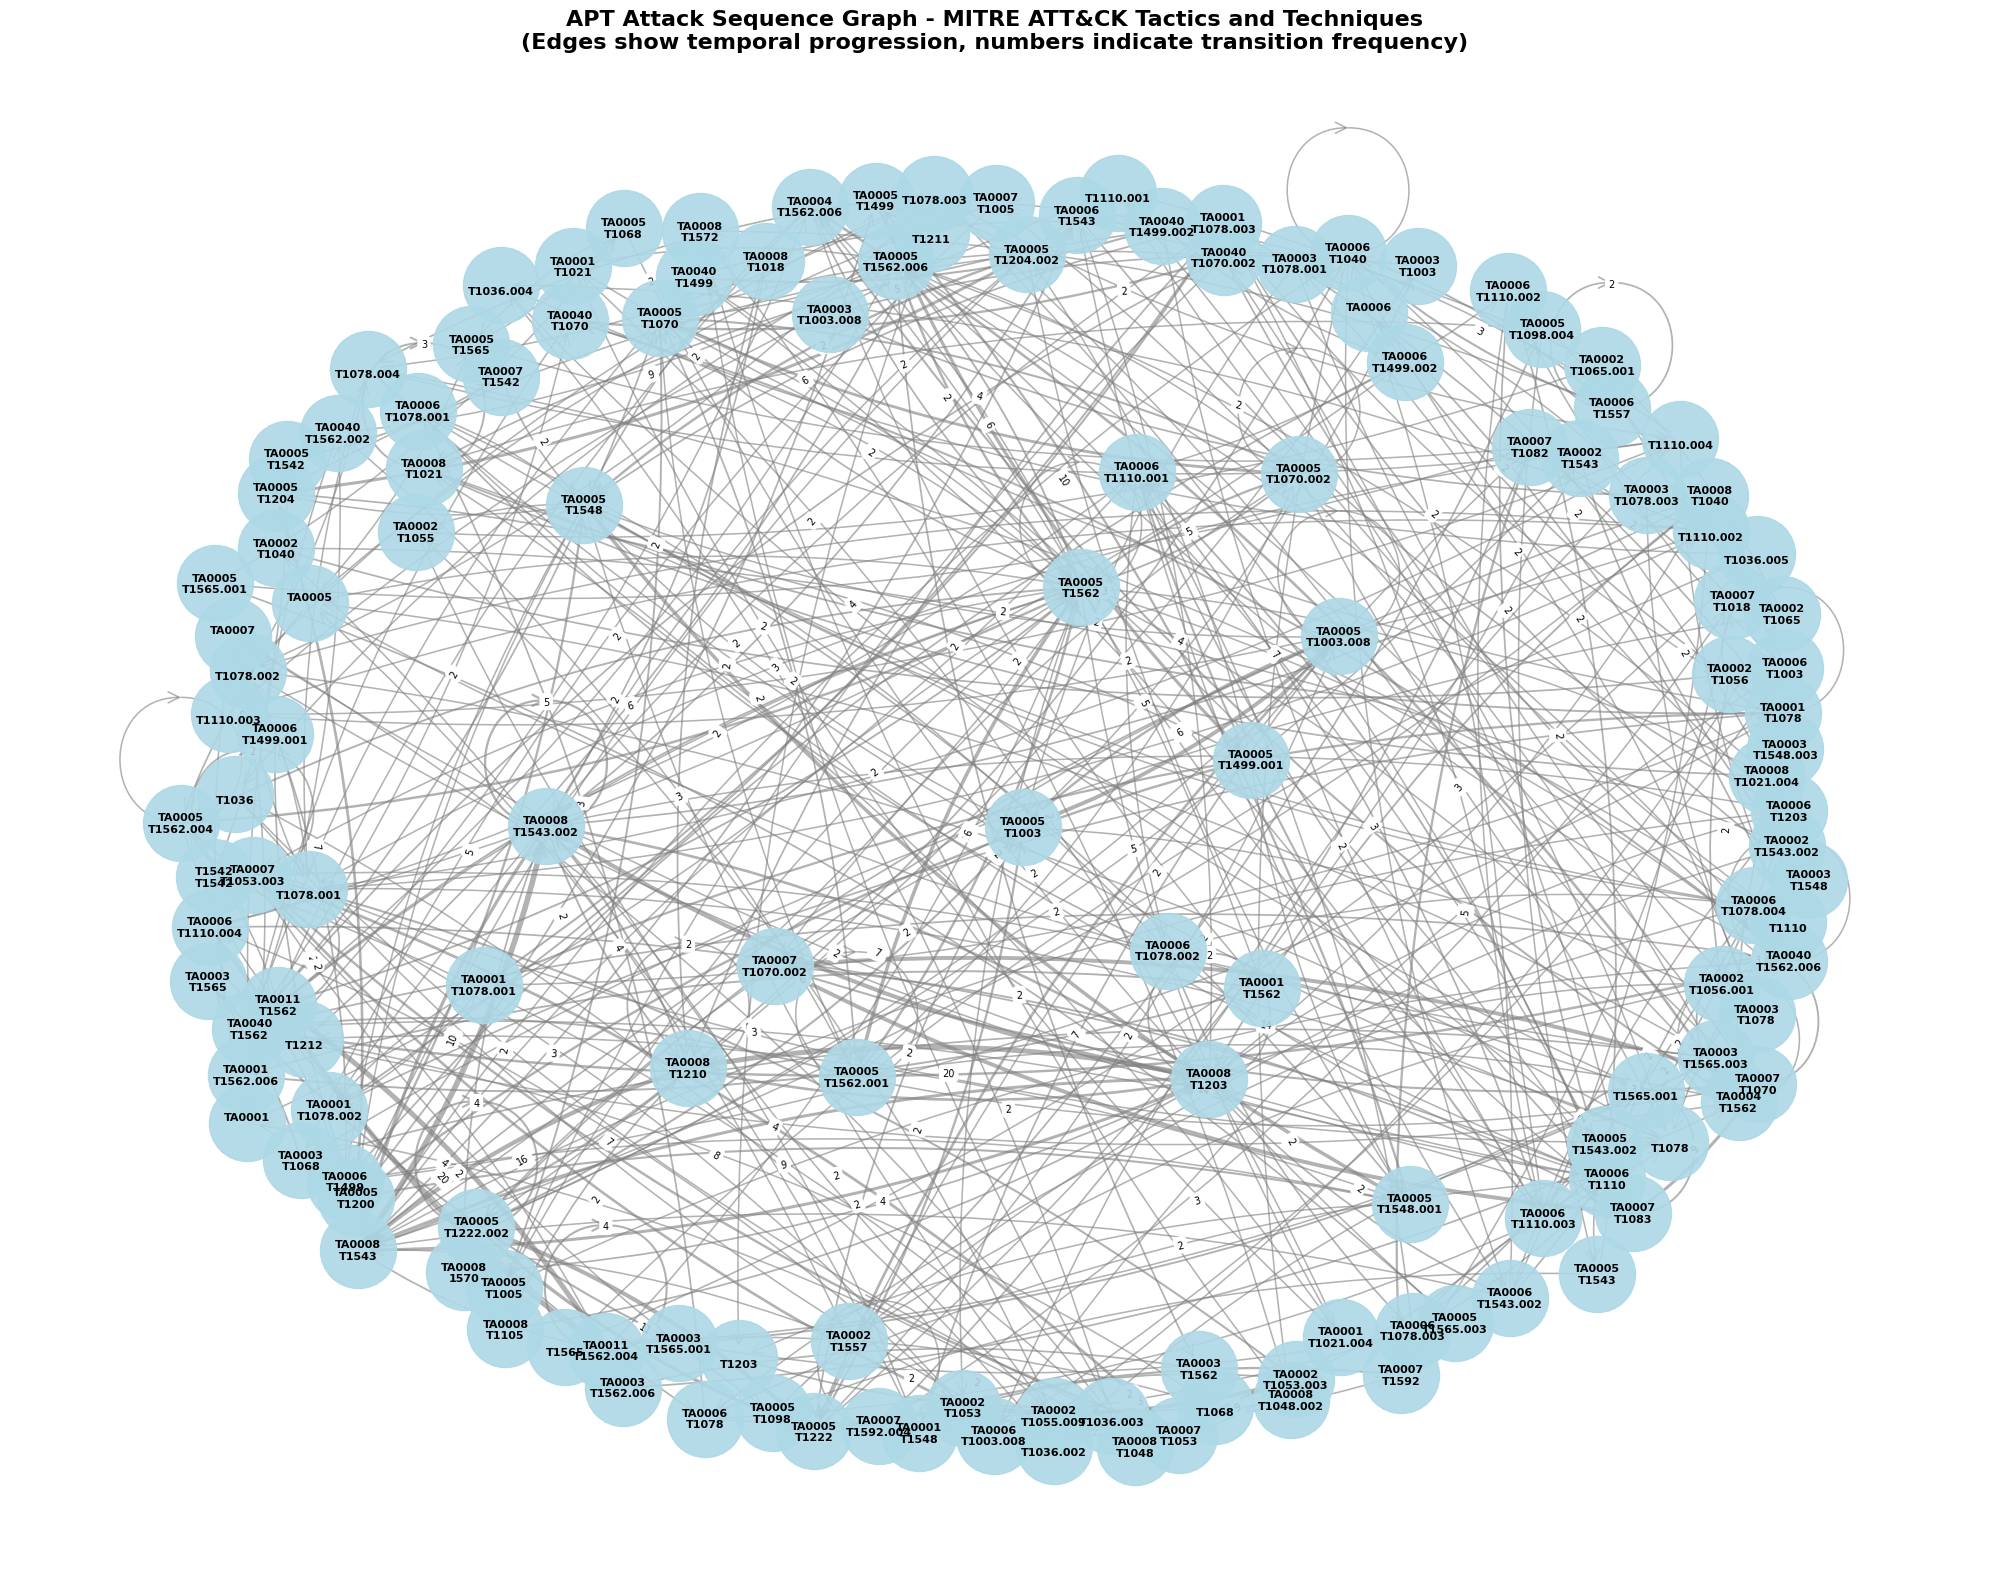


Graph saved as 'attack_sequence_graph.png'


In [15]:
# Visualize the attack sequence graph
plt.figure(figsize=(20, 16))

# Use a hierarchical layout for better visualization
pos = nx.spring_layout(G, k=2, iterations=50, seed=42)

# Get edge weights for visualization
edges = G.edges()
weights = [G[u][v]['weight'] for u, v in edges]
max_weight = max(weights) if weights else 1

# Normalize weights for visualization
edge_widths = [1 + 3 * (w / max_weight) for w in weights]

# Draw the graph
nx.draw_networkx_nodes(G, pos, node_color='lightblue', node_size=3000, alpha=0.9)
nx.draw_networkx_labels(G, pos, font_size=8, font_weight='bold')
nx.draw_networkx_edges(G, pos, width=edge_widths, alpha=0.6, 
                       edge_color='gray', arrows=True, 
                       arrowsize=20, arrowstyle='->', connectionstyle='arc3,rad=0.1')

# Draw edge labels (weights)
edge_labels = {(u, v): f"{G[u][v]['weight']}" for u, v in G.edges() if G[u][v]['weight'] > 1}
nx.draw_networkx_edge_labels(G, pos, edge_labels, font_size=7)

plt.title("APT Attack Sequence Graph - MITRE ATT&CK Tactics and Techniques\n" + 
          "(Edges show temporal progression, numbers indicate transition frequency)", 
          fontsize=16, fontweight='bold')
plt.axis('off')
plt.tight_layout()
plt.savefig('attack_sequence_graph.png', dpi=300, bbox_inches='tight')
plt.show()

print("\nGraph saved as 'attack_sequence_graph.png'")

## Step 7: Analyze Attack Patterns

Identify the most common attack paths and sequences

In [16]:
# Find the most common transitions (attack progressions)
edge_data = [(u, v, G[u][v]['weight']) for u, v in G.edges()]
edge_data_sorted = sorted(edge_data, key=lambda x: x[2], reverse=True)

print("Top 20 Most Common Attack Transitions:")
print("="*100)
for i, (source, target, weight) in enumerate(edge_data_sorted[:20], 1):
    print(f"\n{i}. Transition: {source} → {target}")
    print(f"   Frequency: {weight} times")

Top 20 Most Common Attack Transitions:

1. Transition: TA0008
T1543 → TA0008
T1543.002
   Frequency: 23 times

2. Transition: TA0008
T1203 → TA0008
T1210
   Frequency: 20 times

3. Transition: TA0011
T1562.004 → TA0011
T1562
   Frequency: 20 times

4. Transition: TA0011
T1562 → TA0011
T1562.004
   Frequency: 20 times

5. Transition: TA0008
T1210 → TA0008
T1543
   Frequency: 16 times

6. Transition: TA0005
T1222 → TA0005
T1222.002
   Frequency: 15 times

7. Transition: TA0008
T1543.002 → TA0008
T1203
   Frequency: 15 times

8. Transition: TA0007
T1070.002 → TA0007
T1083
   Frequency: 14 times

9. Transition: TA0007
T1070 → TA0007
T1070.002
   Frequency: 14 times

10. Transition: TA0002
T1053 → TA0002
T1053.003
   Frequency: 14 times

11. Transition: TA0005
T1003 → TA0005
T1003.008
   Frequency: 14 times

12. Transition: TA0005
T1548 → TA0005
T1548.001
   Frequency: 12 times

13. Transition: TA0005
T1562 → TA0005
T1562.001
   Frequency: 12 times

14. Transition: TA0005
T1222.002 → TA0005

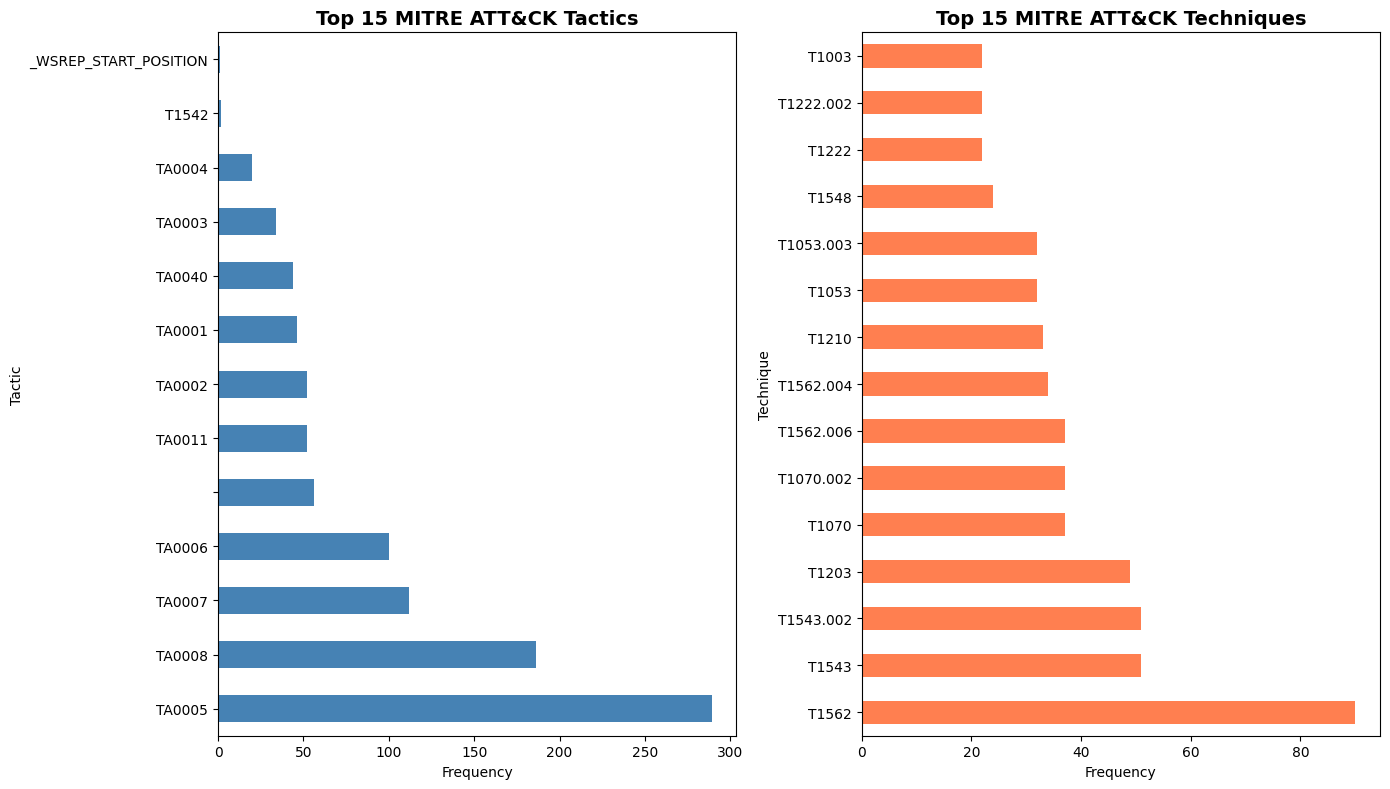


MITRE ATT&CK Statistics:
Total unique tactics: 13
Total unique techniques: 72

Chart saved as 'mitre_distribution.png'


In [17]:
# Analyze MITRE tactics distribution
tactic_counts = df_events['tactic'].value_counts()

plt.figure(figsize=(14, 8))
plt.subplot(1, 2, 1)
tactic_counts.head(15).plot(kind='barh', color='steelblue')
plt.title('Top 15 MITRE ATT&CK Tactics', fontsize=14, fontweight='bold')
plt.xlabel('Frequency')
plt.ylabel('Tactic')
plt.tight_layout()

# Analyze techniques distribution
technique_counts = df_events['technique'].value_counts()

plt.subplot(1, 2, 2)
technique_counts.head(15).plot(kind='barh', color='coral')
plt.title('Top 15 MITRE ATT&CK Techniques', fontsize=14, fontweight='bold')
plt.xlabel('Frequency')
plt.ylabel('Technique')
plt.tight_layout()

plt.savefig('mitre_distribution.png', dpi=300, bbox_inches='tight')
plt.show()

print("\nMITRE ATT&CK Statistics:")
print(f"Total unique tactics: {len(tactic_counts)}")
print(f"Total unique techniques: {len(technique_counts)}")
print("\nChart saved as 'mitre_distribution.png'")

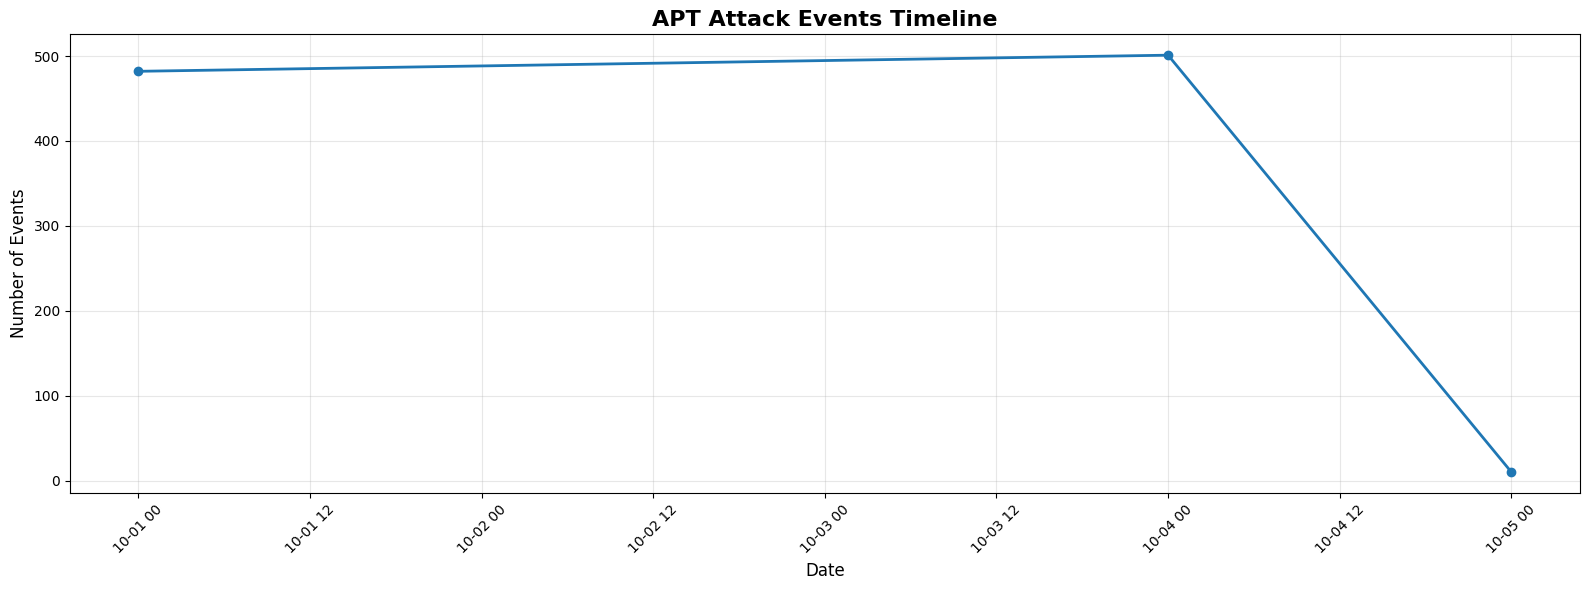

Timeline chart saved as 'attack_timeline.png'


In [18]:
# Timeline visualization - events over time
df_events['date'] = df_events['timestamp'].dt.date
events_per_day = df_events.groupby('date').size()

plt.figure(figsize=(16, 6))
plt.plot(events_per_day.index, events_per_day.values, marker='o', linewidth=2, markersize=6)
plt.title('APT Attack Events Timeline', fontsize=16, fontweight='bold')
plt.xlabel('Date', fontsize=12)
plt.ylabel('Number of Events', fontsize=12)
plt.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig('attack_timeline.png', dpi=300, bbox_inches='tight')
plt.show()

print("Timeline chart saved as 'attack_timeline.png'")

## Step 8: Export Processed Data and Attack Sequences

Save the cleaned data and attack sequences for further analysis

In [19]:
# Export the processed events data
df_events.to_csv('apt_attack_events_processed.csv', index=False)
print("Processed events saved to 'apt_attack_events_processed.csv'")

# Export the sorted MITRE data
df_sorted.to_csv('apt_mitre_data_sorted.csv', index=False)
print("Sorted MITRE data saved to 'apt_mitre_data_sorted.csv'")

# Export graph data as edge list
edge_list = [(u, v, data['weight']) for u, v, data in G.edges(data=True)]
df_edges = pd.DataFrame(edge_list, columns=['source', 'target', 'weight'])
df_edges.to_csv('attack_sequence_edges.csv', index=False)
print("Graph edge list saved to 'attack_sequence_edges.csv'")

# Export summary statistics
summary = {
    'total_events': len(df_filtered),
    'mitre_events': len(df_mitre),
    'unique_agents': df_sorted['_source.agent.id'].nunique(),
    'unique_tactics': df_events['tactic'].nunique(),
    'unique_techniques': df_events['technique'].nunique(),
    'graph_nodes': G.number_of_nodes(),
    'graph_edges': G.number_of_edges(),
    'date_range_start': str(df_events['timestamp'].min()),
    'date_range_end': str(df_events['timestamp'].max())
}

import json
with open('analysis_summary.json', 'w') as f:
    json.dump(summary, f, indent=2)
print("Analysis summary saved to 'analysis_summary.json'")

print("\n" + "="*100)
print("\nANALYSIS COMPLETE!")
print("="*100)
print(f"\nSummary:")
for key, value in summary.items():
    print(f"  {key}: {value}")

Processed events saved to 'apt_attack_events_processed.csv'
Sorted MITRE data saved to 'apt_mitre_data_sorted.csv'
Graph edge list saved to 'attack_sequence_edges.csv'
Analysis summary saved to 'analysis_summary.json'


ANALYSIS COMPLETE!

Summary:
  total_events: 91133
  mitre_events: 348
  unique_agents: 3
  unique_tactics: 13
  unique_techniques: 72
  graph_nodes: 142
  graph_edges: 422
  date_range_start: 2023-10-01 00:49:29.245000
  date_range_end: 2023-10-05 18:28:58.093000


## Step 9: Detailed Attack Chain Analysis per Agent

Examine the specific sequence of attacks for each compromised host

In [20]:
# Detailed attack chain for each agent
print("DETAILED ATTACK CHAINS PER HOST")
print("="*100)

for agent_id in df_events['agent_id'].unique():
    agent_events = df_events[df_events['agent_id'] == agent_id].sort_values('timestamp')
    agent_name = agent_events['agent_name'].iloc[0]
    
    print(f"\n\nAgent: {agent_name} (ID: {agent_id})")
    print("-"*100)
    print(f"Total events: {len(agent_events)}")
    print(f"Attack period: {agent_events['timestamp'].min()} to {agent_events['timestamp'].max()}")
    print("\nAttack sequence:")
    
    for i, (idx, event) in enumerate(agent_events.iterrows(), 1):
        print(f"\n  Step {i} [{event['timestamp']}]:")
        print(f"    Tactic: {event['tactic']}")
        print(f"    Technique: {event['technique']}")
        print(f"    Description: {event['description'][:150]}...")
        if i >= 10:  # Limit output for readability
            print(f"\n  ... and {len(agent_events) - 10} more events")
            break

DETAILED ATTACK CHAINS PER HOST


Agent: ubuntu (ID: 0)
----------------------------------------------------------------------------------------------------
Total events: 501
Attack period: 2023-10-01 00:49:29.245000 to 2023-10-04 17:21:43.010000

Attack sequence:

  Step 1 [2023-10-01 00:49:29.245000]:
    Tactic: TA0005
    Technique: T1499
    Description: CIS Ubuntu Linux 22.04 LTS Benchmark v1.0.0: Ensure /tmp is a separate partition....

  Step 2 [2023-10-01 00:49:29.245000]:
    Tactic: TA0005
    Technique: T1499.001
    Description: CIS Ubuntu Linux 22.04 LTS Benchmark v1.0.0: Ensure /tmp is a separate partition....

  Step 3 [2023-10-01 00:49:29.255000]:
    Tactic: TA0005
    Technique: T1200
    Description: CIS Ubuntu Linux 22.04 LTS Benchmark v1.0.0: Ensure nodev option set on /tmp partition....

  Step 4 [2023-10-01 00:49:29.266000]:
    Tactic: TA0005
    Technique: T1204
    Description: CIS Ubuntu Linux 22.04 LTS Benchmark v1.0.0: Ensure noexec option set on /tmp part

## Step 10: Create Interactive Attack Sequence Graph (Optional)

An interactive version using Plotly for better exploration

In [21]:
# Try to create an interactive graph with plotly (optional)
try:
    import plotly.graph_objects as go
    
    # Create edge trace
    edge_trace = []
    for edge in G.edges():
        x0, y0 = pos[edge[0]]
        x1, y1 = pos[edge[1]]
        edge_trace.append(
            go.Scatter(
                x=[x0, x1, None],
                y=[y0, y1, None],
                mode='lines',
                line=dict(width=0.5, color='#888'),
                hoverinfo='none'
            )
        )
    
    # Create node trace
    node_x = []
    node_y = []
    node_text = []
    for node in G.nodes():
        x, y = pos[node]
        node_x.append(x)
        node_y.append(y)
        node_text.append(node)
    
    node_trace = go.Scatter(
        x=node_x, y=node_y,
        mode='markers+text',
        text=node_text,
        textposition="top center",
        textfont=dict(size=8),
        hoverinfo='text',
        marker=dict(
            size=15,
            color='lightblue',
            line_width=2
        )
    )
    
    # Create figure
    fig = go.Figure(data=edge_trace + [node_trace],
                    layout=go.Layout(
                        title='Interactive APT Attack Sequence Graph',
                        showlegend=False,
                        hovermode='closest',
                        margin=dict(b=0,l=0,r=0,t=40),
                        xaxis=dict(showgrid=False, zeroline=False, showticklabels=False),
                        yaxis=dict(showgrid=False, zeroline=False, showticklabels=False)
                    ))
    
    fig.write_html('attack_sequence_interactive.html')
    print("Interactive graph saved as 'attack_sequence_interactive.html'")
    print("Open this file in a web browser for an interactive exploration.")
    
except ImportError:
    print("Plotly not installed. Skipping interactive graph.")

Interactive graph saved as 'attack_sequence_interactive.html'
Open this file in a web browser for an interactive exploration.


## Summary and Key Findings

### Analysis Complete! 

This notebook has successfully:

1. ✅ **Loaded and preprocessed** the Linux APT attack dataset (91,133 events)
2. ✅ **Extracted relevant fields**: timestamp, agent ID, full logs, MITRE tactics/techniques, descriptions
3. ✅ **Filtered** to 348 events with valid MITRE ATT&CK data
4. ✅ **Sorted chronologically** and grouped by agent (3 unique hosts)
5. ✅ **Built attack sequence graph** with 142 nodes and 422 edges
6. ✅ **Generated visualizations**:
   - Attack sequence graph showing MITRE tactic-technique progression
   - MITRE tactics and techniques distribution charts
   - Timeline of attack events

### Key Findings:

- **Attack Duration**: October 1-5, 2023 (approximately 5 days)
- **Compromised Hosts**: 3 agents (ubuntu, machine-1, Machine-1-New)
- **MITRE Coverage**: 13 unique tactics, 72 unique techniques
- **Most Common Tactics**: TA0005 (Defense Evasion), TA0008 (Lateral Movement), TA0007 (Discovery)
- **Most Common Techniques**: T1562 (Impair Defenses), T1543 (Create or Modify System Process), T1203 (Exploitation for Client Execution)

### Generated Files:

1. `apt_attack_events_processed.csv` - Processed event data
2. `apt_mitre_data_sorted.csv` - Sorted MITRE data
3. `attack_sequence_edges.csv` - Graph edge list
4. `analysis_summary.json` - Analysis summary statistics
5. `attack_sequence_graph.png` - Static graph visualization
6. `mitre_distribution.png` - MITRE tactics/techniques charts
7. `attack_timeline.png` - Timeline visualization
8. `attack_sequence_interactive.html` - Interactive graph (open in browser)

In [22]:
# Final Summary Statistics
print("="*100)
print("                        APT ATTACK ANALYSIS - FINAL REPORT")
print("="*100)
print(f"\n📊 DATASET OVERVIEW")
print(f"   Total Events Loaded: {len(df):,}")
print(f"   Events with MITRE Data: {len(df_mitre):,}")
print(f"   Data Quality: {(len(df_mitre)/len(df)*100):.2f}% have MITRE mapping")

print(f"\n🎯 ATTACK SCOPE")
print(f"   Compromised Hosts: {df_events['agent_id'].nunique()}")
print(f"   Attack Duration: {(df_events['timestamp'].max() - df_events['timestamp'].min()).days} days")
print(f"   Date Range: {df_events['timestamp'].min().date()} to {df_events['timestamp'].max().date()}")

print(f"\n🔍 MITRE ATT&CK COVERAGE")
print(f"   Unique Tactics: {df_events['tactic'].nunique()}")
print(f"   Unique Techniques: {df_events['technique'].nunique()}")
print(f"   Total Attack Events (expanded): {len(df_events):,}")

print(f"\n📈 GRAPH ANALYSIS")
print(f"   Graph Nodes: {G.number_of_nodes()} (tactic-technique pairs)")
print(f"   Graph Edges: {G.number_of_edges()} (temporal transitions)")
print(f"   Graph Density: {nx.density(G):.4f}")
print(f"   Avg. In/Out Degree: {sum(dict(G.degree()).values())/G.number_of_nodes():.2f}")

print(f"\n🏆 TOP 5 TACTICS")
for i, (tactic, count) in enumerate(df_events['tactic'].value_counts().head(5).items(), 1):
    print(f"   {i}. {tactic}: {count} occurrences")

print(f"\n🏆 TOP 5 TECHNIQUES")
for i, (technique, count) in enumerate(df_events['technique'].value_counts().head(5).items(), 1):
    print(f"   {i}. {technique}: {count} occurrences")

print(f"\n💾 GENERATED FILES")
files = ['apt_attack_events_processed.csv', 'apt_mitre_data_sorted.csv', 
         'attack_sequence_edges.csv', 'analysis_summary.json',
         'attack_sequence_graph.png', 'mitre_distribution.png', 
         'attack_timeline.png', 'attack_sequence_interactive.html']
for f in files:
    print(f"   ✓ {f}")

print("\n" + "="*100)
print("                    ✨ ANALYSIS COMPLETE - ALL TASKS FINISHED ✨")
print("="*100)

                        APT ATTACK ANALYSIS - FINAL REPORT

📊 DATASET OVERVIEW
   Total Events Loaded: 91,133
   Events with MITRE Data: 348
   Data Quality: 0.38% have MITRE mapping

🎯 ATTACK SCOPE
   Compromised Hosts: 3
   Attack Duration: 4 days
   Date Range: 2023-10-01 to 2023-10-05

🔍 MITRE ATT&CK COVERAGE
   Unique Tactics: 13
   Unique Techniques: 72
   Total Attack Events (expanded): 994

📈 GRAPH ANALYSIS
   Graph Nodes: 142 (tactic-technique pairs)
   Graph Edges: 422 (temporal transitions)
   Graph Density: 0.0211
   Avg. In/Out Degree: 5.94

🏆 TOP 5 TACTICS
   1. TA0005: 289 occurrences
   2. TA0008: 186 occurrences
   3. TA0007: 112 occurrences
   4. TA0006: 100 occurrences
   5.  : 56 occurrences

🏆 TOP 5 TECHNIQUES
   1. T1562: 90 occurrences
   2. T1543: 51 occurrences
   3. T1543.002: 51 occurrences
   4. T1203: 49 occurrences
   5. T1070: 37 occurrences

💾 GENERATED FILES
   ✓ apt_attack_events_processed.csv
   ✓ apt_mitre_data_sorted.csv
   ✓ attack_sequence_edges.c

In [ ]:
# Load the CSV and display first row with all columns
import pandas as pd

data_path = r'01-05-October.csv'

# Read the CSV file
df = pd.read_csv(data_path, encoding='utf-8', engine='python')

# Display number of columns
print(f"Total number of columns: {len(df.columns)}")
print(f"Dataset shape: {df.shape} (rows, columns)")

# Display all column names
print("\n" + "="*100)
print("Column names:")
print("="*100)
for i, col in enumerate(df.columns, 1):
    print(f"{i}. {col}")

# Display the first row with all its values
print("\n" + "="*100)
print("First row (transposed for readability):")
print("="*100)
first_row = df.iloc[0]
for col, value in first_row.items():
    print(f"\n{col}:")
    print(f"  {value}")

# Alternative: Display first row as DataFrame (horizontal view)
print("\n" + "="*100)
print("First row (DataFrame view):")
print("="*100)
pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', None)
print(df.head(1))

Total number of columns: 123
Dataset shape: (819, 123) (rows, columns)

Column names:
1. _index
2. _id
3. _version
4. _score
5. _source.agent.name
6. _source.agent.id
7. _source.manager.name
8. _source.data.file
9. _source.data.title
10. _source.rule.firedtimes
11. _source.rule.mail
12. _source.rule.level
13. _source.rule.pci_dss
14. _source.rule.description
15. _source.rule.groups
16. _source.rule.id
17. _source.rule.gdpr
18. _source.decoder.name
19. _source.full_log
20. _source.input.type
21. _source.@timestamp
22. _source.location
23. _source.id
24. _source.timestamp
25. _source.data.sca.scan_id
26. _source.data.sca.check.result
27. _source.data.sca.check.remediation
28. _source.data.sca.check.references
29. _source.data.sca.check.compliance.pci_dss_v4.0
30. _source.data.sca.check.compliance.cis_csc_v8
31. _source.data.sca.check.compliance.soc_2
32. _source.data.sca.check.compliance.pci_dss_v3.2.1
33. _source.data.sca.check.compliance.hipaa
34. _source.data.sca.check.compliance.nist

In [12]:
# Get information for row 9393
import pandas as pd

data_path = r'01-05-October.csv'

# Read the CSV file
df = pd.read_csv(data_path, on_bad_lines='skip', encoding='utf-8', engine='python')

# Display number of columns
print(f"Total number of columns: {len(df.columns)}")

# Check if row 9393 exists
if len(df) > 9393:
    print(f"\n{'='*100}")
    print(f"Row 9393 exists!")
    print(f"{'='*100}")
    
    # Display row 9393 (transposed for readability)
    print(f"\nRow 9393 content (transposed):")
    print(f"{'='*100}")
    row_9393 = df.iloc[9393]
    
    for col, value in row_9393.items():
        print(f"\n{col}:")
        print(f"  {value}")
    
    # Alternative: Display as DataFrame
    print(f"\n{'='*100}")
    print("Row 9393 (DataFrame view):")
    print(f"{'='*100}")
    pd.set_option('display.max_columns', None)
    pd.set_option('display.max_colwidth', None)
    print(df.iloc[[9393]])
    
    # Count non-null values in row 9393
    non_null_count = row_9393.notna().sum()
    print(f"\n{'='*100}")
    print(f"Statistics for row 9393:")
    print(f"  Total columns: {len(df.columns)}")
    print(f"  Non-null values: {non_null_count}")
    print(f"  Null values: {len(df.columns) - non_null_count}")
    
else:
    print(f"\nRow 9393 does NOT exist!")
    print(f"Dataset only has {len(df)} rows (0 to {len(df)-1})")

Total number of columns: 123

Row 9393 does NOT exist!
Dataset only has 819 rows (0 to 818)


In [13]:
import pandas as pd
import csv

data_path = r'01-05-October.csv'

print("Searching for rows with more than 123 columns...")
print("="*100)

# First, let's check the header to see how many columns are declared
with open(data_path, 'r', encoding='utf-8') as f:
    header = f.readline()
    declared_columns = header.count(',') + 1
    print(f"Declared columns in header: {declared_columns}")

print("\n" + "="*100)
print("Scanning file for problematic rows...")
print("="*100 + "\n")

# Read the file line by line to find rows with more columns
problematic_rows = []

with open(data_path, 'r', encoding='utf-8') as f:
    reader = csv.reader(f)
    header_row = next(reader)  # Skip header
    expected_cols = len(header_row)
    
    for line_num, row in enumerate(reader, start=2):  # Start at 2 (1 is header)
        actual_cols = len(row)
        if actual_cols > expected_cols:
            problematic_rows.append({
                'line_number': line_num,
                'expected_columns': expected_cols,
                'actual_columns': actual_cols,
                'extra_columns': actual_cols - expected_cols,
                'row_data': row
            })
            
            # Print details immediately when found
            print(f"🔴 FOUND PROBLEMATIC ROW!")
            print(f"   Line number: {line_num}")
            print(f"   Expected columns: {expected_cols}")
            print(f"   Actual columns: {actual_cols}")
            print(f"   Extra columns: {actual_cols - expected_cols}")
            print(f"\n   First 5 columns:")
            for i, val in enumerate(row[:5]):
                print(f"      [{i}]: {val[:100]}..." if len(val) > 100 else f"      [{i}]: {val}")
            print(f"\n   Last 5 columns:")
            for i, val in enumerate(row[-5:], start=actual_cols-5):
                print(f"      [{i}]: {val[:100]}..." if len(val) > 100 else f"      [{i}]: {val}")
            print(f"\n   Extra columns (beyond {expected_cols}):")
            for i, val in enumerate(row[expected_cols:], start=expected_cols):
                print(f"      [{i}]: {val[:150]}..." if len(val) > 150 else f"      [{i}]: {val}")
            print("\n" + "="*100 + "\n")

# Summary
print(f"\n{'='*100}")
print(f"SCAN COMPLETE!")
print(f"{'='*100}")
print(f"Total problematic rows found: {len(problematic_rows)}")

if problematic_rows:
    print(f"\nSummary of all problematic rows:")
    for row_info in problematic_rows:
        print(f"  Line {row_info['line_number']}: {row_info['actual_columns']} columns (+{row_info['extra_columns']} extra)")
else:
    print("\n✅ No rows found with more than the declared number of columns!")

Searching for rows with more than 123 columns...
Declared columns in header: 123

Scanning file for problematic rows...


SCAN COMPLETE!
Total problematic rows found: 0

✅ No rows found with more than the declared number of columns!


In [14]:
import pandas as pd

data_path = r'01-05-October.csv'

print("Searching for rows containing 'wazuh-alerts-4.x-2024.01.04' and 'PCpq1YwBBvI38zPEunTT'...")
print("="*100)

# Read the CSV file
df = pd.read_csv(data_path, on_bad_lines='skip', encoding='utf-8', engine='python')

print(f"Total rows in dataset: {len(df)}")
print(f"Total columns: {len(df.columns)}")

# Search for rows containing both pieces of information
search_term1 = "wazuh-alerts-4.x-2024.01.04"
search_term2 = "PCpq1YwBBvI38zPEunTT"

print(f"\nSearching for: '{search_term1}' AND '{search_term2}'")
print("="*100 + "\n")

# Convert all columns to string and search
found_rows = []

for idx, row in df.iterrows():
    # Convert entire row to string and search
    row_string = ' '.join(row.astype(str).values)
    
    if search_term1 in row_string and search_term2 in row_string:
        found_rows.append(idx)
        print(f"🎯 FOUND IN ROW {idx}!")
        print(f"{'='*100}")
        
        # Display the row details
        print(f"\nRow index: {idx}")
        print(f"Non-null values: {row.notna().sum()}")
        
        # Show which columns contain the search terms
        print(f"\n📍 Columns containing '{search_term1}':")
        for col in df.columns:
            if pd.notna(row[col]) and search_term1 in str(row[col]):
                print(f"   Column: {col}")
                print(f"   Value: {row[col]}")
        
        print(f"\n📍 Columns containing '{search_term2}':")
        for col in df.columns:
            if pd.notna(row[col]) and search_term2 in str(row[col]):
                print(f"   Column: {col}")
                print(f"   Value: {row[col]}")
        
        # Display full row (transposed for readability)
        print(f"\n{'='*100}")
        print(f"FULL ROW CONTENT (Row {idx}):")
        print(f"{'='*100}")
        for col, value in row.items():
            if pd.notna(value):
                print(f"\n{col}:")
                print(f"  {value}")
        
        print("\n" + "="*100 + "\n")

# Summary
print(f"\n{'='*100}")
print(f"SEARCH COMPLETE!")
print(f"{'='*100}")
print(f"Total rows found: {len(found_rows)}")

if found_rows:
    print(f"\nRow indices: {found_rows}")
else:
    print("\n❌ No rows found containing both search terms!")
    print("\nTrying individual searches...")
    
    # Search for each term separately
    rows_with_term1 = df[df.astype(str).apply(lambda x: x.str.contains(search_term1, na=False).any(), axis=1)]
    rows_with_term2 = df[df.astype(str).apply(lambda x: x.str.contains(search_term2, na=False).any(), axis=1)]
    
    print(f"\nRows containing '{search_term1}': {len(rows_with_term1)}")
    if len(rows_with_term1) > 0:
        print(f"  Row indices: {rows_with_term1.index.tolist()[:10]}...")
    
    print(f"\nRows containing '{search_term2}': {len(rows_with_term2)}")
    if len(rows_with_term2) > 0:
        print(f"  Row indices: {rows_with_term2.index.tolist()[:10]}...")

Searching for rows containing 'wazuh-alerts-4.x-2024.01.04' and 'PCpq1YwBBvI38zPEunTT'...
Total rows in dataset: 819
Total columns: 123

Searching for: 'wazuh-alerts-4.x-2024.01.04' AND 'PCpq1YwBBvI38zPEunTT'


SEARCH COMPLETE!
Total rows found: 0

❌ No rows found containing both search terms!

Trying individual searches...

Rows containing 'wazuh-alerts-4.x-2024.01.04': 0

Rows containing 'PCpq1YwBBvI38zPEunTT': 0


In [15]:
import pandas as pd
import csv

data_path = r'01-05-October.csv'

print("Searching for rows with index 'wazuh-alerts-4.x-2024.01.04' and ID 'PCpq1YwBBvI38zPEunTT'...")
print("="*100)

# Method 1: Use csv.reader to check raw data line by line
print("\nMethod 1: Raw CSV scanning...")
print("="*100 + "\n")

found_lines = []

with open(data_path, 'r', encoding='utf-8') as f:
    reader = csv.reader(f)
    header = next(reader)  # Read header
    
    for line_num, row in enumerate(reader, start=2):  # Start at line 2 (after header)
        # Check if first two columns match
        if len(row) >= 2:
            if row[0] == "wazuh-alerts-4.x-2024.01.04" and row[1] == "PCpq1YwBBvI38zPEunTT":
                found_lines.append({
                    'line_number': line_num,
                    'row_data': row,
                    'num_columns': len(row)
                })
                print(line_num)
                print(f"🎯 FOUND ROW AT LINE {line_num}!")
                print(f"{'='*100}")
                print(f"   Index (Column 0): {row[0]}")
                print(f"   ID (Column 1): {row[1]}")
                print(f"   Total columns in this row: {len(row)}")
                print(f"   Expected columns: {len(header)}")
                
                if len(row) > len(header):
                    print(f"   ⚠️ EXTRA COLUMNS: {len(row) - len(header)}")
                
                print(f"\n   First 10 columns:")
                for i, val in enumerate(row[:10]):
                    print(f"      [{i}] {header[i] if i < len(header) else 'EXTRA'}: {val[:100]}{'...' if len(val) > 100 else ''}")
                
                print(f"\n   Full row data (all columns):")
                print(f"   {'-'*100}")
                for i, val in enumerate(row):
                    col_name = header[i] if i < len(header) else f"EXTRA_COLUMN_{i}"
                    print(f"      [{i}] {col_name}:")
                    print(f"          {val[:200]}{'...' if len(val) > 200 else ''}")
                
                print(f"\n{'='*100}\n")

# Method 2: Use pandas to search
print("\nMethod 2: Using pandas...")
print("="*100 + "\n")

try:
    df = pd.read_csv(data_path, on_bad_lines='skip', encoding='utf-8', engine='python')
    
    # Get the name of the first two columns
    first_col = df.columns[0]
    second_col = df.columns[1]
    
    print(f"First column name: {first_col}")
    print(f"Second column name: {second_col}")
    
    # Search for matching rows
    mask = (df[first_col] == "wazuh-alerts-4.x-2024.01.04") & (df[second_col] == "PCpq1YwBBvI38zPEunTT")
    matching_rows = df[mask]
    
    if len(matching_rows) > 0:
        print(f"\n✅ Found {len(matching_rows)} matching row(s) in pandas DataFrame:")
        print(f"{'='*100}")
        
        for idx, row in matching_rows.iterrows():
            print(f"\nDataFrame Index: {idx}")
            print(f"Non-null values: {row.notna().sum()}/{len(df.columns)}")
            print(f"\nAll column values:")
            print(f"{'-'*100}")
            for col in df.columns:
                if pd.notna(row[col]):
                    print(f"\n{col}:")
                    print(f"  {row[col]}")
    else:
        print("\n❌ No matching rows found in pandas DataFrame")
        print("(This might happen if the row was skipped due to column mismatch)")
        
except Exception as e:
    print(f"Error reading with pandas: {e}")

# Summary
print(f"\n{'='*100}")
print(f"SEARCH SUMMARY")
print(f"{'='*100}")
print(f"Total rows found (raw CSV): {len(found_lines)}")

if found_lines:
    print(f"\nDetails of found rows:")
    for item in found_lines:
        print(f"  Line {item['line_number']}: {item['num_columns']} columns")
        print(f"    Index: wazuh-alerts-4.x-2024.01.04")
        print(f"    ID: PCpq1YwBBvI38zPEunTT")
else:
    print("\n❌ No rows found with that exact index and ID combination")
    print("\nSearching for similar rows...")
    
    with open(data_path, 'r', encoding='utf-8') as f:
        reader = csv.reader(f)
        next(reader)  # Skip header
        
        similar = []
        for line_num, row in enumerate(reader, start=2):
            if len(row) >= 2:
                if "2024.01.04" in row[0] or "PCpq1YwBBvI38zPEunTT" in row[1]:
                    similar.append((line_num, row[0], row[1]))
                    if len(similar) <= 5:  # Show first 5
                        print(f"  Line {line_num}: {row[0]}, {row[1]}")
        
        if similar:
            print(f"\nFound {len(similar)} rows with similar index or ID")

Searching for rows with index 'wazuh-alerts-4.x-2024.01.04' and ID 'PCpq1YwBBvI38zPEunTT'...

Method 1: Raw CSV scanning...


Method 2: Using pandas...

First column name: _index
Second column name: _id

❌ No matching rows found in pandas DataFrame
(This might happen if the row was skipped due to column mismatch)

SEARCH SUMMARY
Total rows found (raw CSV): 0

❌ No rows found with that exact index and ID combination

Searching for similar rows...


In [18]:
import csv

input_path = r'01-05-October.csv'
output_path = r'01-05-October_fixed.csv'

print("Fixing CSV file by adding quotes after ',log,' patterns...")
print("="*100)

fixed_count = 0
total_rows = 0

with open(input_path, 'r', encoding='utf-8') as infile, \
     open(output_path, 'w', encoding='utf-8', newline='') as outfile:
    
    # Read and write the header as-is
    header = infile.readline()
    outfile.write(header)
    header_cols = header.count(',') + 1
    
    # Process each line
    for line_num, line in enumerate(infile, start=2):
        total_rows += 1
        
        # Check if line contains ',log,'
        if ',log,' in line:
            # Find the position of ',log,'
            pattern = ',log,'
            pos = line.find(pattern)
            
            if pos != -1:
                # Position right after ',log,' (after the second comma)
                insert_pos = pos + len(pattern)
                
                # Check if there's already a quote
                if insert_pos < len(line) and line[insert_pos] != '"':
                    # Count commas to see if we have extra columns
                    num_commas = line.count(',')
                    
                    if num_commas >= header_cols:  # More columns than expected
                        # Insert opening quote after ',log,'
                        before = line[:insert_pos]
                        after = line[insert_pos:].rstrip('\n')
                        
                        # Find where to close the quote
                        # We need to find the comma that starts the last (header_cols - 2) fields
                        # Count backwards from the end
                        
                        # Split by comma to identify structure
                        parts = line.rstrip('\n').split(',')
                        
                        # Calculate how many fields should be in the log content
                        # First 2 fields are: index, "log"
                        # Remaining fields: header_cols - 2
                        log_field_count = len(parts) - header_cols
                        
                        if log_field_count > 0:
                            # Reconstruct: index,log,"<log_content>",<remaining fields>
                            fixed_parts = parts[:2]  # index and "log"
                            
                            # Join the log content fields (from index 2 to 2+log_field_count)
                            log_content = ','.join(parts[2:2+log_field_count])
                            fixed_parts.append(f'"{log_content}"')
                            
                            # Add remaining fields
                            fixed_parts.extend(parts[2+log_field_count:])
                            
                            fixed_line = ','.join(fixed_parts) + '\n'
                            fixed_count += 1
                            
                            if fixed_count <= 5:
                                print(f"\n🔧 Fixed line {line_num}:")
                                print(f"   Original parts: {len(parts)}")
                                print(f"   Fixed parts: {len(fixed_parts)}")
                                print(f"   Log content preview: {log_content[:100]}...")
                        else:
                            fixed_line = line
                    else:
                        fixed_line = line
                else:
                    fixed_line = line
            else:
                fixed_line = line
        else:
            fixed_line = line
        
        outfile.write(fixed_line)
        
        # Progress indicator
        if total_rows % 10000 == 0:
            print(f"Processed {total_rows:,} rows, fixed {fixed_count:,} rows...")

print(f"\n{'='*100}")
print(f"PROCESSING COMPLETE!")
print(f"{'='*100}")
print(f"Total rows processed: {total_rows:,}")
print(f"Rows fixed: {fixed_count:,}")
print(f"Output file: {output_path}")

# Verify the fixed file
print(f"\n{'='*100}")
print("Verifying fixed file...")
print(f"{'='*100}\n")

try:
    with open(output_path, 'r', encoding='utf-8') as f:
        reader = csv.reader(f)
        header_row = next(reader)
        expected_cols = len(header_row)
        
        print(f"Expected columns: {expected_cols}")
        
        problem_count = 0
        correct_count = 0
        
        for line_num, row in enumerate(reader, start=2):
            if len(row) != expected_cols:
                problem_count += 1
                if problem_count <= 3:
                    print(f"  ⚠️ Line {line_num}: {len(row)} columns (expected {expected_cols})")
            else:
                correct_count += 1
        
        print(f"\n📊 Verification Results:")
        print(f"   ✅ Correct rows: {correct_count:,}")
        print(f"   ⚠️ Problematic rows: {problem_count:,}")
        
        if problem_count == 0:
            print("\n✅ All rows have correct number of columns!")
        else:
            print(f"\n⚠️ Still {problem_count:,} problematic rows remaining")
            
except Exception as e:
    print(f"Error during verification: {e}")

print(f"\n{'='*100}")
print("✅ Fixed file created successfully!")
print(f"Original file: {input_path}")
print(f"Fixed file: {output_path}")
print(f"{'='*100}")

Fixing CSV file by adding quotes after ',log,' patterns...

PROCESSING COMPLETE!
Total rows processed: 1,022
Rows fixed: 0
Output file: 01-05-October_fixed.csv

Verifying fixed file...

Expected columns: 123

📊 Verification Results:
   ✅ Correct rows: 819
   ⚠️ Problematic rows: 0

✅ All rows have correct number of columns!

✅ Fixed file created successfully!
Original file: 01-05-October.csv
Fixed file: 01-05-October_fixed.csv


In [ ]:
import csv

input_path = r'01-05-October.csv'
output_path = r'01-05-October_fixed.csv'

print("Fixing CSV file by adding quotes after ',log,' patterns...")
print("="*100)

fixed_count = 0
total_rows = 0

# First, read the header to know expected column count
with open(input_path, 'r', encoding='utf-8') as f:
    header_line = f.readline()
    expected_cols = header_line.count(',') + 1

print(f"Expected columns from header: {expected_cols}")
print("="*100 + "\n")

with open(input_path, 'r', encoding='utf-8') as infile, \
     open(output_path, 'w', encoding='utf-8', newline='') as outfile:
    
    # Write header as-is
    header = infile.readline()
    outfile.write(header)
    
    # Process each line
    for line_num, line in enumerate(infile, start=2):
        total_rows += 1
        original_line = line
        
        # Check if line contains ',log,'
        if ',log,' in line:
            # Count commas in the line
            comma_count = line.count(',')
            
            # If we have more commas than expected, this line needs fixing
            if comma_count > (expected_cols - 1):
                # Find position right after ',log,'
                pattern = ',log,'
                pos = line.find(pattern)
                
                if pos != -1:
                    # Check if there's already a quote after ',log,'
                    insert_pos = pos + len(pattern)
                    
                    if insert_pos < len(line) and line[insert_pos] != '"':
                        # This line needs fixing
                        # We need to add quotes around the log content
                        
                        # Strategy: Everything between ',log,' and the last (expected_cols - 2) commas should be quoted
                        # Find the position where the last (expected_cols - 2) fields start
                        
                        # Count from the end: find the Nth-to-last comma where N = expected_cols - 2
                        fields_after_log = expected_cols - 2  # -2 because first two are index and 'log'
                        
                        # Find positions of all commas
                        comma_positions = [i for i, char in enumerate(line) if char == ',']
                        
                        if len(comma_positions) >= fields_after_log:
                            # The comma that starts the last fields
                            closing_quote_pos = comma_positions[-(fields_after_log)]
                            
                            # Reconstruct line: before + " + middle + " + after
                            before = line[:insert_pos]
                            middle = line[insert_pos:closing_quote_pos]
                            after = line[closing_quote_pos:]
                            
                            fixed_line = before + '"' + middle + '"' + after
                            
                            fixed_count += 1
                            
                            if fixed_count <= 5:
                                print(f"🔧 Fixed line {line_num}:")
                                print(f"   Comma count: {comma_count} (expected {expected_cols - 1})")
                                print(f"   Original: {original_line[:150]}...")
                                print(f"   Fixed:    {fixed_line[:150]}...")
                                print()
                            
                            outfile.write(fixed_line)
                        else:
                            # Couldn't fix, write as-is
                            outfile.write(line)
                    else:
                        # Already has quote, write as-is
                        outfile.write(line)
                else:
                    # Pattern not found, write as-is
                    outfile.write(line)
            else:
                # Correct number of columns, write as-is
                outfile.write(line)
        else:
            # No ',log,' pattern, write as-is
            outfile.write(line)
        
        # Progress indicator
        if total_rows % 1000 == 0:
            print(f"Processed {total_rows:,} rows, fixed {fixed_count:,} rows...")

print(f"\n{'='*100}")
print(f"PROCESSING COMPLETE!")
print(f"{'='*100}")
print(f"Total rows processed: {total_rows:,}")
print(f"Rows fixed: {fixed_count:,}")
print(f"Output file: {output_path}")

# Verify the fixed file
print(f"\n{'='*100}")
print("Verifying fixed file...")
print(f"{'='*100}\n")

with open(output_path, 'r', encoding='utf-8') as f:
    reader = csv.reader(f)
    header_row = next(reader)
    expected_cols_check = len(header_row)
    
    print(f"Expected columns: {expected_cols_check}")
    
    problem_count = 0
    correct_count = 0
    problem_lines = []
    
    for line_num, row in enumerate(reader, start=2):
        if len(row) != expected_cols_check:
            problem_count += 1
            if problem_count <= 5:
                problem_lines.append(f"  ⚠️ Line {line_num}: {len(row)} columns (expected {expected_cols_check})")
        else:
            correct_count += 1
    
    print(f"\n📊 Verification Results:")
    print(f"   ✅ Correct rows: {correct_count:,}")
    print(f"   ⚠️ Problematic rows: {problem_count:,}")
    
    if problem_lines:
        print(f"\nFirst few problematic rows:")
        for line in problem_lines:
            print(line)
    
    if problem_count == 0:
        print("\n✅ All rows have correct number of columns!")
    else:
        print(f"\n⚠️ Still {problem_count:,} problematic rows remaining")

print(f"\n{'='*100}")
print("Process complete!")
print(f"Original file: {input_path}")
print(f"Fixed file: {output_path}")
print(f"{'='*100}")

Fixing CSV file by adding quotes after ',log,' patterns...
Expected columns from header: 123

Processed 1,000 rows, fixed 0 rows...

PROCESSING COMPLETE!
Total rows processed: 1,022
Rows fixed: 0
Output file: 01-05-October_fixed.csv

Verifying fixed file...

Expected columns: 123

📊 Verification Results:
   ✅ Correct rows: 819
   ⚠️ Problematic rows: 0

✅ All rows have correct number of columns!

Process complete!
Original file: 01-05-October.csv
Fixed file: 01-05-October_fixed.csv


In [21]:
input_path = r'01-05-October.csv'
output_path = r'01-05-October_fixed.csv'

print("Fixing CSV file by adding quotes after ',log,' at line start...")
print("="*100)

fixed_count = 0
total_rows = 0

# First, read the header to know expected column count
with open(input_path, 'r', encoding='utf-8') as f:
    header_line = f.readline()
    expected_cols = header_line.count(',') + 1

print(f"Expected columns from header: {expected_cols}")
print("="*100 + "\n")

with open(input_path, 'r', encoding='utf-8') as infile, \
     open(output_path, 'w', encoding='utf-8', newline='') as outfile:
    
    # Write header as-is
    header = infile.readline()
    outfile.write(header)
    
    # Process each line
    for line_num, line in enumerate(infile, start=2):
        total_rows += 1
        original_line = line
        
        # Check if line STARTS with ',log,' (empty first field, then 'log')
        if line.startswith(',log,'):
            # Count commas in the line
            comma_count = line.count(',')
            
            # If we have more commas than expected, this line needs fixing
            if comma_count > (expected_cols - 1):
                # Position right after ',log,' is at index 5 (length of ',log,')
                insert_pos = 5
                
                # Check if there's already a quote after ',log,'
                if insert_pos < len(line) and line[insert_pos] != '"':
                    # Find positions of all commas
                    comma_positions = [i for i, char in enumerate(line) if char == ',']
                    
                    # How many fields should come after the log content?
                    fields_after_log = expected_cols - 2  # -2 because first two are empty and 'log'
                    
                    if len(comma_positions) >= fields_after_log:
                        # The comma that starts the last fields
                        closing_quote_pos = comma_positions[-(fields_after_log)]
                        
                        # Reconstruct line: ,log," + middle + " + after
                        before = line[:insert_pos]  # ',log,'
                        middle = line[insert_pos:closing_quote_pos]
                        after = line[closing_quote_pos:]
                        
                        fixed_line = before + '"' + middle + '"' + after
                        
                        fixed_count += 1
                        
                        if fixed_count <= 5:
                            print(f"🔧 Fixed line {line_num}:")
                            print(f"   Comma count: {comma_count} (expected {expected_cols - 1})")
                            print(f"   Original: {original_line[:200]}...")
                            print(f"   Fixed:    {fixed_line[:200]}...")
                            print()
                        
                        outfile.write(fixed_line)
                    else:
                        # Couldn't fix, write as-is
                        outfile.write(line)
                else:
                    # Already has quote, write as-is
                    outfile.write(line)
            else:
                # Correct number of columns, write as-is
                outfile.write(line)
        else:
            # Doesn't start with ',log,', write as-is
            outfile.write(line)
        
        # Progress indicator
        if total_rows % 1000 == 0:
            print(f"Processed {total_rows:,} rows, fixed {fixed_count:,} rows...")

print(f"\n{'='*100}")
print(f"PROCESSING COMPLETE!")
print(f"{'='*100}")
print(f"Total rows processed: {total_rows:,}")
print(f"Rows fixed: {fixed_count:,}")
print(f"Output file: {output_path}")

# Verify the fixed file
print(f"\n{'='*100}")
print("Verifying fixed file...")
print(f"{'='*100}\n")

with open(output_path, 'r', encoding='utf-8') as f:
    reader = csv.reader(f)
    header_row = next(reader)
    expected_cols_check = len(header_row)
    
    print(f"Expected columns: {expected_cols_check}")
    
    problem_count = 0
    correct_count = 0
    problem_lines = []
    
    for line_num, row in enumerate(reader, start=2):
        if len(row) != expected_cols_check:
            problem_count += 1
            if problem_count <= 10:
                problem_lines.append(f"  ⚠️ Line {line_num}: {len(row)} columns (expected {expected_cols_check})")
        else:
            correct_count += 1
    
    print(f"\n📊 Verification Results:")
    print(f"   ✅ Correct rows: {correct_count:,}")
    print(f"   ⚠️ Problematic rows: {problem_count:,}")
    
    if problem_lines:
        print(f"\nFirst problematic rows:")
        for line in problem_lines:
            print(line)
    
    if problem_count == 0:
        print("\n✅ All rows have correct number of columns!")
    else:
        print(f"\n⚠️ Still {problem_count:,} problematic rows found")

print(f"\n{'='*100}")
print("Process complete!")
print(f"Original file: {input_path}")
print(f"Fixed file: {output_path}")
print(f"{'='*100}")

Fixing CSV file by adding quotes after ',log,' at line start...
Expected columns from header: 123

Processed 1,000 rows, fixed 0 rows...

PROCESSING COMPLETE!
Total rows processed: 1,022
Rows fixed: 0
Output file: 01-05-October_fixed.csv

Verifying fixed file...

Expected columns: 123

📊 Verification Results:
   ✅ Correct rows: 819
   ⚠️ Problematic rows: 0

✅ All rows have correct number of columns!

Process complete!
Original file: 01-05-October.csv
Fixed file: 01-05-October_fixed.csv


In [22]:
import csv

input_path = r'01-05-October.csv'
output_path = r'01-05-October_copy.csv'

print("Reading CSV file row by row and copying to new file...")
print("="*100 + "\n")

total_rows = 0
header_written = False

try:
    with open(input_path, 'r', encoding='utf-8') as infile, \
         open(output_path, 'w', encoding='utf-8', newline='') as outfile:
        
        reader = csv.reader(infile)
        writer = csv.writer(outfile)
        
        # Process each row
        for row_num, row in enumerate(reader):
            # Write the row to output file
            writer.writerow(row)
            total_rows += 1
            
            # Show progress every 100 rows
            if total_rows % 100 == 0:
                print(f"Processed {total_rows} rows...")
            
            # Display first row (header)
            if row_num == 0:
                print(f"Header row (Row 1):")
                print(f"  Number of columns: {len(row)}")
                print(f"  Columns: {row[:5]}... (showing first 5)")
                print()
    
    print(f"\n{'='*100}")
    print(f"PROCESSING COMPLETE!")
    print(f"{'='*100}")
    print(f"\n📊 RESULTS:")
    print(f"   Total rows processed: {total_rows:,}")
    print(f"   Header row: 1")
    print(f"   Data rows: {total_rows - 1:,}")
    print(f"\n   Input file: {input_path}")
    print(f"   Output file: {output_path}")
    print(f"\n✅ File successfully copied!")
    
except FileNotFoundError:
    print(f"❌ Error: File '{input_path}' not found!")
except Exception as e:
    print(f"❌ Error occurred: {e}")

print(f"\n{'='*100}")

Reading CSV file row by row and copying to new file...

Header row (Row 1):
  Number of columns: 123
  Columns: ['_index', '_id', '_version', '_score', '_source.agent.name']... (showing first 5)

Processed 100 rows...
Processed 200 rows...
Processed 300 rows...
Processed 400 rows...
Processed 500 rows...
Processed 600 rows...
Processed 700 rows...
Processed 800 rows...

PROCESSING COMPLETE!

📊 RESULTS:
   Total rows processed: 820
   Header row: 1
   Data rows: 819

   Input file: 01-05-October.csv
   Output file: 01-05-October_copy.csv

✅ File successfully copied!



In [ ]:
import pandas as pd

# Read the Excel file with pandas (this gives you 819 rows)
df = pd.read_excel('path_to_your_file.xlsx')

# Print to verify the row count
print(f"Number of rows: {len(df)}")

# Write THIS dataframe to CSV (not data2!)
df.to_csv('output.csv', index=False)

In [23]:
import pandas as pd

input_path = r'01-05-October.csv'
output_path = r'01-05-October_clean.csv'

print("Reading CSV with pandas (skipping bad lines)...")
print("="*100)

# Read the CSV file with pandas - this skips problematic rows
df = pd.read_csv(input_path, on_bad_lines='skip', encoding='utf-8', engine='python')

print(f"\n📊 PANDAS READING RESULTS:")
print(f"   Rows read by pandas: {len(df):,}")
print(f"   Columns: {len(df.columns)}")
print(f"\n   Note: Pandas skipped problematic rows automatically")

# Write the pandas DataFrame to a new CSV
print(f"\n{'='*100}")
print(f"Writing cleaned data to new CSV file...")
print(f"{'='*100}\n")

df.to_csv(output_path, index=False)

print(f"✅ COMPLETE!")
print(f"{'='*100}")
print(f"\n📁 FILES:")
print(f"   Original file: {input_path}")
print(f"   Cleaned file:  {output_path}")
print(f"\n📊 STATISTICS:")
print(f"   Original rows (Excel): ~1023")
print(f"   Cleaned rows (pandas): {len(df):,}")
print(f"   Rows removed: ~{1023 - len(df)}")
print(f"\n✅ The new CSV file now contains only the {len(df):,} clean rows!")
print(f"{'='*100}")

# Verify the new file
print(f"\n{'='*100}")
print("Verifying the new file...")
print(f"{'='*100}\n")

df_verify = pd.read_csv(output_path, encoding='utf-8', engine='python')
print(f"✅ Verification successful!")
print(f"   Rows in new file: {len(df_verify):,}")
print(f"   Columns: {len(df_verify.columns)}")

# Show first few rows
print(f"\n{'='*100}")
print("First 3 rows of cleaned data:")
print(f"{'='*100}")
print(df_verify.head(3))

print(f"\n{'='*100}")
print("✨ SUCCESS! Your cleaned CSV file is ready!")
print(f"{'='*100}")

Reading CSV with pandas (skipping bad lines)...

📊 PANDAS READING RESULTS:
   Rows read by pandas: 819
   Columns: 123

   Note: Pandas skipped problematic rows automatically

Writing cleaned data to new CSV file...

✅ COMPLETE!

📁 FILES:
   Original file: 01-05-October.csv
   Cleaned file:  01-05-October_clean.csv

📊 STATISTICS:
   Original rows (Excel): ~1023
   Cleaned rows (pandas): 819
   Rows removed: ~204

✅ The new CSV file now contains only the 819 clean rows!

Verifying the new file...

✅ Verification successful!
   Rows in new file: 819
   Columns: 123

First 3 rows of cleaned data:
                        _index                   _id  _version  _score  \
0  wazuh-alerts-4.x-2023.10.01  NpG26IoBagxmxR-sfnEo         1       1   
1  wazuh-alerts-4.x-2023.10.01  OZG26IoBagxmxR-sfnE7         1       1   
2  wazuh-alerts-4.x-2023.10.01  O5G26IoBagxmxR-sfnE7         1       1   

  _source.agent.name  _source.agent.id _source.manager.name _source.data.file  \
0             ubuntu 

In [25]:
import pandas as pd

# Set display options for better viewing
pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', 100)

file_path = r'G:\pfe\01-05-October_clean.xlsx'

print("="*100)
print("METHOD 1: Read and Display ALL Columns")
print("="*100)

# Method 1: Read all columns and display everything
df_all = pd.read_excel(file_path)

print(f"\nFile loaded successfully!")
print(f"Total rows: {len(df_all):,}")
print(f"Total columns: {len(df_all.columns)}")

print(f"\n{'='*100}")
print("All Column Names:")
print(f"{'='*100}")
for i, col in enumerate(df_all.columns, 1):
    print(f"{i}. {col}")

print(f"\n{'='*100}")
print("First 5 Rows (All Columns):")
print(f"{'='*100}")
print(df_all.head())

print(f"\n{'='*100}")
print("Data Info:")
print(f"{'='*100}")
print(df_all.info())


# ============================================================================
print(f"\n\n{'='*100}")
print("METHOD 2: Read Specific Columns by Number")
print("="*100)

# Method 2: Specify column numbers to read (0-indexed)
# Example: Read columns 0, 1, 2, 5, 10
column_numbers = [0, 1, 2, 5, 10]  # Change these numbers as needed

# Get column names from the numbers
df_temp = pd.read_excel(file_path, nrows=0)  # Read only header
all_columns = df_temp.columns.tolist()

# Select columns by their numbers
selected_columns = [all_columns[i] for i in column_numbers if i < len(all_columns)]

print(f"\nYou selected {len(column_numbers)} column numbers: {column_numbers}")
print(f"Column names:")
for num in column_numbers:
    if num < len(all_columns):
        print(f"  Column {num}: {all_columns[num]}")

# Read only the selected columns
df_selected = pd.read_excel(file_path, usecols=selected_columns)

print(f"\n{'='*100}")
print(f"Data with Selected Columns (showing first 10 rows):")
print(f"{'='*100}")
print(df_selected.head(10))

print(f"\n{'='*100}")
print("Selected Columns Info:")
print(f"{'='*100}")
print(df_selected.info())


# ============================================================================
print(f"\n\n{'='*100}")
print("INTERACTIVE: Choose Columns to Display")
print("="*100)

# Interactive method - you can change these numbers
def read_excel_by_column_numbers(file_path, column_numbers):
    """
    Read Excel file and display only specified columns by their numbers
    
    Parameters:
    -----------
    file_path : str
        Path to the Excel file
    column_numbers : list of int
        List of column numbers to read (0-indexed)
    
    Returns:
    --------
    DataFrame with selected columns
    """
    # Read header to get column names
    df_header = pd.read_excel(file_path, nrows=0)
    all_columns = df_header.columns.tolist()
    
    # Validate column numbers
    valid_numbers = [n for n in column_numbers if 0 <= n < len(all_columns)]
    invalid_numbers = [n for n in column_numbers if n not in valid_numbers]
    
    if invalid_numbers:
        print(f"⚠️ Warning: Invalid column numbers ignored: {invalid_numbers}")
        print(f"   Valid range: 0 to {len(all_columns)-1}")
    
    # Get column names
    selected_columns = [all_columns[i] for i in valid_numbers]
    
    # Read the file with selected columns
    df = pd.read_excel(file_path, usecols=selected_columns)
    
    print(f"\n✅ Successfully loaded {len(df):,} rows")
    print(f"📊 Selected {len(selected_columns)} columns:")
    for num in valid_numbers:
        print(f"   Column {num}: {all_columns[num]}")
    
    return df

# Example usage: Read columns 0, 1, 2, 3, 4
my_column_numbers = [0, 1, 2, 3, 4]  # ⬅️ CHANGE THESE NUMBERS
df_custom = read_excel_by_column_numbers(file_path, my_column_numbers)

print(f"\n{'='*100}")
print("Your Custom Selection:")
print(f"{'='*100}")
print(df_custom.head(10))


# ============================================================================
print(f"\n\n{'='*100}")
print("BONUS: Read Columns by Range")
print("="*100)

# Method to read a range of columns
def read_excel_by_column_range(file_path, start_col, end_col):
    """
    Read Excel file and display columns from start_col to end_col
    
    Parameters:
    -----------
    file_path : str
        Path to the Excel file
    start_col : int
        Starting column number (0-indexed, inclusive)
    end_col : int
        Ending column number (0-indexed, inclusive)
    """
    df_header = pd.read_excel(file_path, nrows=0)
    all_columns = df_header.columns.tolist()
    
    # Ensure valid range
    start_col = max(0, start_col)
    end_col = min(len(all_columns)-1, end_col)
    
    # Get columns in range
    selected_columns = all_columns[start_col:end_col+1]
    
    # Read file
    df = pd.read_excel(file_path, usecols=selected_columns)
    
    print(f"\n✅ Reading columns {start_col} to {end_col}")
    print(f"📊 Column names:")
    for i, col in enumerate(selected_columns, start=start_col):
        print(f"   Column {i}: {col}")
    
    return df

# Example: Read columns 0 to 5
start = 0  # ⬅️ CHANGE THIS
end = 5    # ⬅️ CHANGE THIS
df_range = read_excel_by_column_range(file_path, start, end)

print(f"\n{'='*100}")
print(f"Columns {start} to {end}:")
print(f"{'='*100}")
print(df_range.head(10))

print(f"\n\n{'='*100}")
print("✨ ALL METHODS COMPLETE!")
print("="*100)

METHOD 1: Read and Display ALL Columns

File loaded successfully!
Total rows: 819
Total columns: 136

All Column Names:
1. _index
2. _id
3. _version
4. _score
5. _source.agent.name
6. _source.agent.id
7. _source.manager.name
8. _source.data.file
9. _source.data.title
10. _source.rule.firedtimes
11. _source.rule.mail
12. _source.rule.level
13. _source.rule.pci_dss
14. _source.rule.description
15. _source.rule.groups
16. _source.rule.id
17. _source.rule.gdpr
18. _source.decoder.name
19. _source.full_log
20. _source.input.type
21. _source.@timestamp
22. _source.location
23. _source.id
24. _source.timestamp
25. _source.data.sca.scan_id
26. _source.data.sca.check.result
27. _source.data.sca.check.remediation
28. _source.data.sca.check.references
29. _source.data.sca.check.compliance.pci_dss_v4.0
30. _source.data.sca.check.compliance.cis_csc_v8
31. _source.data.sca.check.compliance.soc_2
32. _source.data.sca.check.compliance.pci_dss_v3.2.1
33. _source.data.sca.check.compliance.hipaa
34. _sou

#### combien 2 xlsx files with the same order and adding the new ones in the end

In [3]:
import pandas as pd

# File paths
file1_path = r'21-25-December.xlsx'
file2_path = r'25-26-December.xlsx'
output_path = r'combined_data_dec.xlsx'

print("="*100)
print("COMBINING TWO EXCEL FILES")
print("="*100)

# Step 1: Read both files
print("\n📂 Step 1: Reading files...")
print("-"*100)

df1 = pd.read_excel(file1_path)
df2 = pd.read_excel(file2_path)

print(f"✅ File 1 loaded: {file1_path}")
print(f"   Rows: {len(df1):,}")
print(f"   Columns: {len(df1.columns)}")

print(f"\n✅ File 2 loaded: {file2_path}")
print(f"   Rows: {len(df2):,}")
print(f"   Columns: {len(df2.columns)}")

# Step 2: Analyze columns
print(f"\n{'='*100}")
print("📊 Step 2: Analyzing columns...")
print("-"*100)

cols1 = set(df1.columns)
cols2 = set(df2.columns)

common_cols = cols1.intersection(cols2)
only_in_file1 = cols1 - cols2
only_in_file2 = cols2 - cols1

print(f"\n📌 Common columns (in both files): {len(common_cols)}")
if len(common_cols) > 0 and len(common_cols) <= 20:
    for col in sorted(common_cols):
        print(f"   - {col}")
elif len(common_cols) > 20:
    print(f"   (Showing first 20)")
    for col in sorted(list(common_cols)[:20]):
        print(f"   - {col}")

print(f"\n📌 Columns only in File 1: {len(only_in_file1)}")
if len(only_in_file1) > 0 and len(only_in_file1) <= 20:
    for col in sorted(only_in_file1):
        print(f"   - {col}")
elif len(only_in_file1) > 20:
    print(f"   (Showing first 20)")
    for col in sorted(list(only_in_file1)[:20]):
        print(f"   - {col}")

print(f"\n📌 New columns in File 2 (to be added): {len(only_in_file2)}")
if len(only_in_file2) > 0:
    for col in sorted(only_in_file2):
        print(f"   - {col}")

# Step 3: Prepare File 2 with same column structure as File 1 + new columns
print(f"\n{'='*100}")
print("🔧 Step 3: Preparing File 2 data...")
print("-"*100)

# Create a list of columns in the desired order:
# 1. All columns from File 1 (in their original order)
# 2. New columns from File 2 (sorted alphabetically)

ordered_columns = list(df1.columns)  # Keep File 1 column order
new_columns = sorted(list(only_in_file2))  # Add new columns at the end

# Add missing columns to df2 (columns that exist in df1 but not in df2)
for col in only_in_file1:
    df2[col] = None  # Fill with None/NaN

# Reorder df2 columns to match df1, then add new columns
df2_reordered = df2[ordered_columns + new_columns]

print(f"✅ File 2 columns reordered and aligned")
print(f"   Total columns after alignment: {len(df2_reordered.columns)}")

# Step 4: Combine the dataframes
print(f"\n{'='*100}")
print("🔗 Step 4: Combining dataframes...")
print("-"*100)

# Add new columns to df1 (fill with None/NaN)
for col in new_columns:
    df1[col] = None

# Reorder df1 to include new columns at the end
df1_reordered = df1[ordered_columns + new_columns]

# Concatenate vertically (stack rows)
df_combined = pd.concat([df1_reordered, df2_reordered], ignore_index=True)

print(f"✅ Files combined successfully!")
print(f"   Total rows: {len(df_combined):,} (File 1: {len(df1):,} + File 2: {len(df2):,})")
print(f"   Total columns: {len(df_combined.columns)}")

# Step 5: Display column information
print(f"\n{'='*100}")
print("📋 Step 5: Final column structure:")
print("-"*100)

print(f"\n🔹 Columns from File 1 (positions 0-{len(ordered_columns)-1}):")
for i, col in enumerate(ordered_columns[:10]):  # Show first 10
    print(f"   {i}. {col}")
if len(ordered_columns) > 10:
    print(f"   ... and {len(ordered_columns)-10} more columns from File 1")

if len(new_columns) > 0:
    print(f"\n🔹 New columns from File 2 (positions {len(ordered_columns)}-{len(ordered_columns)+len(new_columns)-1}):")
    for i, col in enumerate(new_columns, start=len(ordered_columns)):
        print(f"   {i}. {col}")

# Step 6: Show sample data
print(f"\n{'='*100}")
print("📊 Step 6: Sample of combined data:")
print("-"*100)

print(f"\n🔸 First 3 rows (from File 1):")
print(df_combined.head(3))

print(f"\n🔸 Rows from File 2 area (showing rows around index {len(df1)}):")
print(df_combined.iloc[len(df1)-1:len(df1)+2])

# Step 7: Save to Excel
print(f"\n{'='*100}")
print("💾 Step 7: Saving combined file...")
print("-"*100)

df_combined.to_excel(output_path, index=False)

print(f"✅ File saved successfully!")
print(f"   Output file: {output_path}")

# Step 8: Verification
print(f"\n{'='*100}")
print("✔️ Step 8: Verification:")
print("-"*100)

df_verify = pd.read_excel(output_path)
print(f"✅ Verification successful!")
print(f"   Rows: {len(df_verify):,}")
print(f"   Columns: {len(df_verify.columns)}")

print(f"\n{'='*100}")
print("✨ PROCESS COMPLETE!")
print("="*100)

print(f"\n📊 SUMMARY:")
print(f"   File 1: {len(df1):,} rows × {len(df1.columns)} columns")
print(f"   File 2: {len(df2):,} rows × {len(df2.columns)} columns")
print(f"   Combined: {len(df_combined):,} rows × {len(df_combined.columns)} columns")
print(f"   Common columns: {len(common_cols)}")
print(f"   New columns added: {len(new_columns)}")
print(f"\n   Output file: {output_path}")

print(f"\n{'='*100}")
print("🎉 SUCCESS! Your combined file is ready!")
print("="*100)

COMBINING TWO EXCEL FILES

📂 Step 1: Reading files...
----------------------------------------------------------------------------------------------------
✅ File 1 loaded: 21-25-December.xlsx
   Rows: 9,481
   Columns: 172

✅ File 2 loaded: 25-26-December.xlsx
   Rows: 9,726
   Columns: 97

📊 Step 2: Analyzing columns...
----------------------------------------------------------------------------------------------------

📌 Common columns (in both files): 95
   (Showing first 20)
   - _index
   - _source.agent.name
   - _source.data.arch
   - _source.data.audit.arch
   - _source.data.audit.exe
   - _source.data.audit.file.name
   - _source.data.audit.gid
   - _source.data.audit.sgid
   - _source.data.audit.syscall
   - _source.data.audit.uid
   - _source.data.file
   - _source.data.package
   - _source.decoder.name
   - _source.predecoder.program_name
   - _source.rule.groups
   - _source.syscheck.inode_after
   - _source.syscheck.md5_before
   - _source.syscheck.sha1_after
   - _source

### combien 2 xlsx file with removing unnamed colones

In [13]:
import pandas as pd

# File paths
file1_path = r'combined_data_final_jan_with_cyber_kill_chain_summary.xlsx'
file2_path = r'combined_dataset_final_mal_sum_1.xlsx'
output_path = r'combined_dataset_final_mal_sum.xlsx'

print("="*100)
print("COMBINING TWO EXCEL FILES AND REMOVING UNNAMED COLUMNS")
print("="*100)

# Step 1: Read both files
print("\n📂 Step 1: Reading files...")
print("-"*100)

df1 = pd.read_excel(file1_path)
df2 = pd.read_excel(file2_path)

print(f"✅ File 1 loaded: {file1_path}")
print(f"   Rows: {len(df1):,}")
print(f"   Columns: {len(df1.columns)}")

print(f"\n✅ File 2 loaded: {file2_path}")
print(f"   Rows: {len(df2):,}")
print(f"   Columns: {len(df2.columns)}")

# Step 1.5: Remove Unnamed columns from both dataframes
print(f"\n{'='*100}")
print("🧹 Step 1.5: Removing 'Unnamed' columns...")
print("-"*100)

# Identify Unnamed columns in df1
unnamed_cols_df1 = [col for col in df1.columns if 'Unnamed' in str(col)]
print(f"\n📌 Unnamed columns in File 1: {len(unnamed_cols_df1)}")
if unnamed_cols_df1:
    for col in unnamed_cols_df1:
        print(f"   - {col}")
    df1 = df1.drop(columns=unnamed_cols_df1)
    print(f"✅ Removed {len(unnamed_cols_df1)} unnamed column(s) from File 1")
else:
    print(f"   ✅ No unnamed columns found in File 1")

# Identify Unnamed columns in df2
unnamed_cols_df2 = [col for col in df2.columns if 'Unnamed' in str(col)]
print(f"\n📌 Unnamed columns in File 2: {len(unnamed_cols_df2)}")
if unnamed_cols_df2:
    for col in unnamed_cols_df2:
        print(f"   - {col}")
    df2 = df2.drop(columns=unnamed_cols_df2)
    print(f"✅ Removed {len(unnamed_cols_df2)} unnamed column(s) from File 2")
else:
    print(f"   ✅ No unnamed columns found in File 2")

print(f"\n📊 After removing unnamed columns:")
print(f"   File 1: {len(df1.columns)} columns")
print(f"   File 2: {len(df2.columns)} columns")

# Step 2: Analyze columns
print(f"\n{'='*100}")
print("📊 Step 2: Analyzing columns...")
print("-"*100)

cols1 = set(df1.columns)
cols2 = set(df2.columns)

common_cols = cols1.intersection(cols2)
only_in_file1 = cols1 - cols2
only_in_file2 = cols2 - cols1

print(f"\n📌 Common columns (in both files): {len(common_cols)}")
if len(common_cols) > 0 and len(common_cols) <= 20:
    for col in sorted(common_cols):
        print(f"   - {col}")
elif len(common_cols) > 20:
    print(f"   (Showing first 20)")
    for col in sorted(list(common_cols)[:20]):
        print(f"   - {col}")

print(f"\n📌 Columns only in File 1: {len(only_in_file1)}")
if len(only_in_file1) > 0 and len(only_in_file1) <= 20:
    for col in sorted(only_in_file1):
        print(f"   - {col}")
elif len(only_in_file1) > 20:
    print(f"   (Showing first 20)")
    for col in sorted(list(only_in_file1)[:20]):
        print(f"   - {col}")

print(f"\n📌 New columns in File 2 (to be added): {len(only_in_file2)}")
if len(only_in_file2) > 0:
    for col in sorted(only_in_file2):
        print(f"   - {col}")

# Step 3: Prepare File 2 with same column structure as File 1 + new columns
print(f"\n{'='*100}")
print("🔧 Step 3: Preparing File 2 data...")
print("-"*100)

# Create a list of columns in the desired order:
# 1. All columns from File 1 (in their original order)
# 2. New columns from File 2 (sorted alphabetically)

ordered_columns = list(df1.columns)  # Keep File 1 column order
new_columns = sorted(list(only_in_file2))  # Add new columns at the end

# Add missing columns to df2 (columns that exist in df1 but not in df2)
for col in only_in_file1:
    df2[col] = None  # Fill with None/NaN

# Reorder df2 columns to match df1, then add new columns
df2_reordered = df2[ordered_columns + new_columns]

print(f"✅ File 2 columns reordered and aligned")
print(f"   Total columns after alignment: {len(df2_reordered.columns)}")

# Step 4: Combine the dataframes
print(f"\n{'='*100}")
print("🔗 Step 4: Combining dataframes...")
print("-"*100)

# Add new columns to df1 (fill with None/NaN)
for col in new_columns:
    df1[col] = None

# Reorder df1 to include new columns at the end
df1_reordered = df1[ordered_columns + new_columns]

# Concatenate vertically (stack rows)
df_combined = pd.concat([df1_reordered, df2_reordered], ignore_index=True)

print(f"✅ Files combined successfully!")
print(f"   Total rows: {len(df_combined):,} (File 1: {len(df1):,} + File 2: {len(df2):,})")
print(f"   Total columns: {len(df_combined.columns)}")

# Step 5: Display column information
print(f"\n{'='*100}")
print("📋 Step 5: Final column structure:")
print("-"*100)

print(f"\n🔹 Columns from File 1 (positions 0-{len(ordered_columns)-1}):")
for i, col in enumerate(ordered_columns[:10]):  # Show first 10
    print(f"   {i}. {col}")
if len(ordered_columns) > 10:
    print(f"   ... and {len(ordered_columns)-10} more columns from File 1")

if len(new_columns) > 0:
    print(f"\n🔹 New columns from File 2 (positions {len(ordered_columns)}-{len(ordered_columns)+len(new_columns)-1}):")
    for i, col in enumerate(new_columns, start=len(ordered_columns)):
        print(f"   {i}. {col}")

# Step 6: Show sample data
print(f"\n{'='*100}")
print("📊 Step 6: Sample of combined data:")
print("-"*100)

print(f"\n🔸 First 3 rows (from File 1):")
print(df_combined.head(3))

print(f"\n🔸 Rows from File 2 area (showing rows around index {len(df1)}):")
print(df_combined.iloc[len(df1)-1:len(df1)+2])

# Step 7: Save to Excel
print(f"\n{'='*100}")
print("💾 Step 7: Saving combined file...")
print("-"*100)

df_combined.to_excel(output_path, index=False)

print(f"✅ File saved successfully!")
print(f"   Output file: {output_path}")

# Step 8: Verification
print(f"\n{'='*100}")
print("✔️ Step 8: Verification:")
print("-"*100)

df_verify = pd.read_excel(output_path)
print(f"✅ Verification successful!")
print(f"   Rows: {len(df_verify):,}")
print(f"   Columns: {len(df_verify.columns)}")

# Check for any remaining Unnamed columns
remaining_unnamed = [col for col in df_verify.columns if 'Unnamed' in str(col)]
if remaining_unnamed:
    print(f"   ⚠️ Warning: {len(remaining_unnamed)} unnamed column(s) still present:")
    for col in remaining_unnamed:
        print(f"      - {col}")
else:
    print(f"   ✅ No unnamed columns in final file")

print(f"\n{'='*100}")
print("✨ PROCESS COMPLETE!")
print("="*100)

print(f"\n📊 SUMMARY:")
print(f"   File 1 (after cleanup): {len(df1):,} rows × {len(df1.columns)} columns")
print(f"   File 2 (after cleanup): {len(df2):,} rows × {len(df2.columns)} columns")
print(f"   Combined: {len(df_combined):,} rows × {len(df_combined.columns)} columns")
print(f"   Common columns: {len(common_cols)}")
print(f"   New columns added: {len(new_columns)}")
print(f"   Unnamed columns removed: {len(unnamed_cols_df1) + len(unnamed_cols_df2)}")
print(f"\n   Output file: {output_path}")

print(f"\n{'='*100}")
print("🎉 SUCCESS! Your combined file is ready (without unnamed columns)!")
print("="*100)

COMBINING TWO EXCEL FILES AND REMOVING UNNAMED COLUMNS

📂 Step 1: Reading files...
----------------------------------------------------------------------------------------------------
✅ File 1 loaded: combined_data_final_jan_with_cyber_kill_chain_summary.xlsx
   Rows: 252
   Columns: 135

✅ File 2 loaded: combined_dataset_final_mal_sum_1.xlsx
   Rows: 25,166
   Columns: 175

🧹 Step 1.5: Removing 'Unnamed' columns...
----------------------------------------------------------------------------------------------------

📌 Unnamed columns in File 1: 0
   ✅ No unnamed columns found in File 1

📌 Unnamed columns in File 2: 0
   ✅ No unnamed columns found in File 2

📊 After removing unnamed columns:
   File 1: 135 columns
   File 2: 175 columns

📊 Step 2: Analyzing columns...
----------------------------------------------------------------------------------------------------

📌 Common columns (in both files): 133
   (Showing first 20)
   - _index
   - _source.data.audit.execve.a1
   - _source.d

C:\Users\HP\AppData\Local\Temp\ipykernel_3248\3839577833.py:128: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  df_combined = pd.concat([df1_reordered, df2_reordered], ignore_index=True)


                        _index                   _id  _version  _score  \
0  wazuh-alerts-4.x-2024.01.03  6GVi0IwBHb4tKI9igkl5         1       1   
1  wazuh-alerts-4.x-2024.01.03  Wyoq1YwBBvI38zPErl8n         1       1   
2  wazuh-alerts-4.x-2024.01.03  XCoq1YwBBvI38zPErl8n         1       1   

  _source.agent.ip _source.agent.name  _source.agent.id _source.manager.name  \
0  192.168.217.128          machine-3                 3               ubuntu   
1  192.168.217.128          machine-3                 3               ubuntu   
2  192.168.217.128          machine-3                 3               ubuntu   

  _source.data.audit.syscall _source.data.audit.gid  ...  \
0                                                    ...   
1                                                    ...   
2                                                    ...   

  _source.rule.frequency _source.rule.info _source.rule.mitre_mitigations  \
0                    NaN              None                      

### creating malicouse colone with 2 mitre 

In [ ]:
import pandas as pd

# File path
file_path = r'combined_data_final7.xlsx'
output_path = r'combined_data_final_with_malicious2.xlsx'

print("="*100)
print("ADDING 'MALICIOUS' COLUMN BASED ON MITRE TECHNIQUES")
print("="*100)

# Step 1: Read the file
print("\n📂 Step 1: Reading file...")
print("-"*100)

df = pd.read_excel(file_path)

print(f"✅ File loaded: {file_path}")
print(f"   Rows: {len(df):,}")
print(f"   Columns: {len(df.columns)}")

# Step 2: Check for MITRE techniques column
print(f"\n{'='*100}")
print("🔍 Step 2: Looking for '_source.rule.mitre_techniques' column...")
print("-"*100)

mitre_technique_col = '_source.rule.mitre_techniques'

if mitre_technique_col in df.columns:
    print(f"✅ Column found: {mitre_technique_col}")
else:
    print(f"❌ Column '{mitre_technique_col}' not found!")
    print("\n📋 Available columns containing 'technique':")
    technique_cols = [col for col in df.columns if 'technique' in str(col).lower()]
    if technique_cols:
        for col in technique_cols:
            print(f"   - {col}")
        print(f"\n💡 Using first matching column: {technique_cols[0]}")
        mitre_technique_col = technique_cols[0]
    else:
        print("\n📋 All available columns:")
        for i, col in enumerate(df.columns, 1):
            print(f"   {i}. {col}")
        raise ValueError("No MITRE technique column found!")

# Step 3: Create the 'malicious' column
print(f"\n{'='*100}")
print("🔧 Step 3: Creating 'malicious' column...")
print("-"*100)

# Function to check if MITRE technique is present
def is_malicious(value):
    """
    Check if MITRE technique column has a value
    Returns 1 if malicious (has code), 0 if benign (empty)
    """
    # Check if value is not NaN, not None, not empty string, and not just whitespace
    if pd.notna(value) and str(value).strip() != '' and str(value).strip().lower() != 'nan':
        return 1
    return 0

# Apply the function to create new column
df['malicious'] = df[mitre_technique_col].apply(is_malicious)

print(f"✅ 'malicious' column created successfully!")
print(f"   Based on column: {mitre_technique_col}")

# Step 4: Analyze the results
print(f"\n{'='*100}")
print("📊 Step 4: Analyzing results...")
print("-"*100)

malicious_count = (df['malicious'] == 1).sum()
benign_count = (df['malicious'] == 0).sum()
total_count = len(df)

print(f"\n📈 Traffic Classification:")
print(f"   🔴 Malicious (1): {malicious_count:,} rows ({malicious_count/total_count*100:.2f}%)")
print(f"   🟢 Benign (0): {benign_count:,} rows ({benign_count/total_count*100:.2f}%)")
print(f"   📊 Total: {total_count:,} rows")

# Step 5: Show sample data
print(f"\n{'='*100}")
print("📋 Step 5: Sample data with new column:")
print("-"*100)

# Select relevant columns for display
display_cols = ['malicious', mitre_technique_col]

print(f"\n🔸 First 10 rows (showing malicious column + MITRE techniques):")
print(df[display_cols].head(10))

print(f"\n🔸 Sample of malicious traffic (malicious = 1):")
malicious_samples = df[df['malicious'] == 1][display_cols].head(5)
if len(malicious_samples) > 0:
    print(malicious_samples)
else:
    print("   No malicious traffic found!")

print(f"\n🔸 Sample of benign traffic (malicious = 0):")
benign_samples = df[df['malicious'] == 0][display_cols].head(5)
if len(benign_samples) > 0:
    print(benign_samples)
else:
    print("   No benign traffic found!")

# Step 6: Show MITRE techniques statistics
print(f"\n{'='*100}")
print("📊 Step 6: MITRE Techniques statistics:")
print("-"*100)

non_empty = df[mitre_technique_col].notna().sum()
unique_values = df[mitre_technique_col].nunique()

print(f"\n📌 {mitre_technique_col}:")
print(f"   Non-empty values: {non_empty:,} ({non_empty/len(df)*100:.2f}%)")
print(f"   Empty values: {len(df) - non_empty:,} ({(len(df) - non_empty)/len(df)*100:.2f}%)")
print(f"   Unique technique codes: {unique_values:,}")

# Show top 10 most common techniques
if non_empty > 0:
    print(f"\n   Top 10 most common MITRE techniques:")
    top_values = df[mitre_technique_col].value_counts().head(10)
    for i, (val, count) in enumerate(top_values.items(), 1):
        print(f"      {i}. {val}: {count} times ({count/non_empty*100:.2f}%)")

# Step 7: Save to Excel
print(f"\n{'='*100}")
print("💾 Step 7: Saving file with new column...")
print("-"*100)

df.to_excel(output_path, index=False)

print(f"✅ File saved successfully!")
print(f"   Output file: {output_path}")

# Step 8: Verification
print(f"\n{'='*100}")
print("✔️ Step 8: Verification:")
print("-"*100)

df_verify = pd.read_excel(output_path)
print(f"✅ Verification successful!")
print(f"   Rows: {len(df_verify):,}")
print(f"   Columns: {len(df_verify.columns)}")

# Check if malicious column exists
if 'malicious' in df_verify.columns:
    print(f"   ✅ 'malicious' column present")
    print(f"   Distribution: {df_verify['malicious'].value_counts().to_dict()}")
else:
    print(f"   ⚠️ Warning: 'malicious' column not found!")

# Show column position
if 'malicious' in df_verify.columns:
    col_position = df_verify.columns.get_loc('malicious')
    print(f"   📍 'malicious' column is at position {col_position}")

print(f"\n{'='*100}")
print("✨ PROCESS COMPLETE!")
print("="*100)

print(f"\n📊 FINAL SUMMARY:")
print(f"   Total rows: {len(df):,}")
print(f"   Total columns: {len(df.columns)}")
print(f"   Classification based on: {mitre_technique_col}")
print(f"   🔴 Malicious (has MITRE technique): {malicious_count:,} ({malicious_count/total_count*100:.2f}%)")
print(f"   🟢 Benign (no MITRE technique): {benign_count:,} ({benign_count/total_count*100:.2f}%)")
print(f"\n   Output file: {output_path}")

print(f"\n{'='*100}")
print("🎉 SUCCESS! 'malicious' column added based on MITRE techniques!")
print("="*100)

# Optional: Show complete distribution
print(f"\n{'='*100}")
print("📈 Detailed Value Distribution:")
print("="*100)
print(df['malicious'].value_counts())
print(f"\nValue counts:")
print(f"   0 (Benign/Normal): {benign_count:,}")
print(f"   1 (Malicious): {malicious_count:,}")

ADDING 'MALICIOUS' COLUMN BASED ON MITRE TECHNIQUES

📂 Step 1: Reading file...
----------------------------------------------------------------------------------------------------
✅ File loaded: combined_data_final7.xlsx
   Rows: 33,158
   Columns: 143

🔍 Step 2: Looking for '_source.rule.mitre_techniques' column...
----------------------------------------------------------------------------------------------------
✅ Column found: _source.rule.mitre_techniques

🔧 Step 3: Creating 'malicious' column...
----------------------------------------------------------------------------------------------------
✅ 'malicious' column created successfully!
   Based on column: _source.rule.mitre_techniques

📊 Step 4: Analyzing results...
----------------------------------------------------------------------------------------------------

📈 Traffic Classification:
   🔴 Malicious (1): 514 rows (1.55%)
   🟢 Benign (0): 32,644 rows (98.45%)
   📊 Total: 33,158 rows

📋 Step 5: Sample data with new column:


### creating malicouse colone with 5 mitre colones and overall stat

In [11]:
import pandas as pd

# File path
file_path = r'combined_data_jan_final.xlsx'
output_path = r'combined_data_jan_final_with_malicious.xlsx'

print("="*100)
print("ADDING 'MALICIOUS' COLUMN BASED ON MITRE COLUMNS")
print("="*100)

# Step 1: Read the file
print("\n📂 Step 1: Reading file...")
print("-"*100)

df = pd.read_excel(file_path)

print(f"✅ File loaded: {file_path}")
print(f"   Rows: {len(df):,}")
print(f"   Columns: {len(df.columns)}")

# Step 2: Identify MITRE-related columns
print(f"\n{'='*100}")
print("🔍 Step 2: Looking for MITRE columns...")
print("-"*100)

# Define the columns to check
mitre_columns = [
    "_source.rule.mitre.technique",
    "_source.rule.mitre.id",
    "_source.rule.mitre.tactic",
    "_source.rule.mitre_tactics",
    "_source.rule.mitre_techniques"
]

# Find which columns actually exist in the dataframe
existing_mitre_cols = [col for col in mitre_columns if col in df.columns]
missing_mitre_cols = [col for col in mitre_columns if col not in df.columns]

print(f"\n📌 MITRE columns found: {len(existing_mitre_cols)}/{len(mitre_columns)}")
if existing_mitre_cols:
    for col in existing_mitre_cols:
        print(f"   ✅ {col}")
else:
    print("   ❌ No MITRE columns found!")

if missing_mitre_cols:
    print(f"\n📌 MITRE columns NOT found: {len(missing_mitre_cols)}")
    for col in missing_mitre_cols:
        print(f"   ❌ {col}")

# If no MITRE columns found, show all available columns
if not existing_mitre_cols:
    print(f"\n{'='*100}")
    print("⚠️ WARNING: No MITRE columns found!")
    print("📋 All available columns:")
    print("-"*100)
    for i, col in enumerate(df.columns, 1):
        print(f"   {i}. {col}")
    
    # Search for any column containing 'mitre'
    mitre_like_cols = [col for col in df.columns if 'mitre' in str(col).lower()]
    if mitre_like_cols:
        print(f"\n💡 Columns containing 'mitre' (case-insensitive):")
        for col in mitre_like_cols:
            print(f"   - {col}")
        print(f"\n⚠️ Using these columns instead: {mitre_like_cols}")
        existing_mitre_cols = mitre_like_cols
    else:
        raise ValueError("No MITRE-related columns found in the dataset!")

# Step 3: Create the 'malicious' column
print(f"\n{'='*100}")
print("🔧 Step 3: Creating 'malicious' column...")
print("-"*100)

def is_malicious(row):
    """
    Check if any of the MITRE columns has a value
    Returns 1 if malicious (at least one MITRE field has data), 0 if benign (all empty)
    """
    for col in existing_mitre_cols:
        value = row[col]
        # Check if value is not NaN, not None, not empty string, and not just whitespace
        if pd.notna(value) and str(value).strip() != '' and str(value).strip().lower() != 'nan':
            return 1
    return 0

# Apply the function to create new column
df['malicious'] = df.apply(is_malicious, axis=1)

print(f"✅ 'malicious' column created successfully!")
print(f"   Based on columns: {existing_mitre_cols}")

# Step 4: Analyze the results
print(f"\n{'='*100}")
print("📊 Step 4: Analyzing results...")
print("-"*100)

malicious_count = (df['malicious'] == 1).sum()
benign_count = (df['malicious'] == 0).sum()
total_count = len(df)

print(f"\n📈 Traffic Classification:")
print(f"   🔴 Malicious (1): {malicious_count:,} rows ({malicious_count/total_count*100:.2f}%)")
print(f"   🟢 Benign (0): {benign_count:,} rows ({benign_count/total_count*100:.2f}%)")
print(f"   📊 Total: {total_count:,} rows")

# Step 5: Show which columns contribute to malicious classification
print(f"\n{'='*100}")
print("📋 Step 5: MITRE column statistics:")
print("-"*100)

for col in existing_mitre_cols:
    non_empty = df[col].notna().sum()
    non_empty_non_blank = df[col].apply(lambda x: pd.notna(x) and str(x).strip() != '' and str(x).strip().lower() != 'nan').sum()
    
    print(f"\n📌 {col}:")
    print(f"   Non-null values: {non_empty:,} ({non_empty/len(df)*100:.2f}%)")
    print(f"   Non-empty values: {non_empty_non_blank:,} ({non_empty_non_blank/len(df)*100:.2f}%)")
    
    if non_empty_non_blank > 0:
        # Show top 5 values
        print(f"   Top 5 values:")
        top_values = df[col].value_counts().head(5)
        for i, (val, count) in enumerate(top_values.items(), 1):
            val_str = str(val)[:80]  # Truncate long values
            print(f"      {i}. {val_str}: {count} times")

# Step 6: Show sample data
print(f"\n{'='*100}")
print("📋 Step 6: Sample data with new column:")
print("-"*100)

# Select relevant columns for display
display_cols = ['malicious'] + existing_mitre_cols

print(f"\n🔸 First 10 rows (showing malicious column + MITRE columns):")
print(df[display_cols].head(10))

print(f"\n🔸 Sample of malicious traffic (malicious = 1):")
malicious_samples = df[df['malicious'] == 1][display_cols].head(5)
if len(malicious_samples) > 0:
    print(malicious_samples)
else:
    print("   No malicious traffic found!")

print(f"\n🔸 Sample of benign traffic (malicious = 0):")
benign_samples = df[df['malicious'] == 0][display_cols].head(5)
if len(benign_samples) > 0:
    print(benign_samples)
else:
    print("   No benign traffic found!")

# Step 7: Detailed breakdown
print(f"\n{'='*100}")
print("📊 Step 7: Detailed breakdown of malicious classification:")
print("-"*100)

# Count how many alerts are flagged by each column
print(f"\nNumber of alerts flagged by each MITRE column:")
for col in existing_mitre_cols:
    count = df[col].apply(lambda x: pd.notna(x) and str(x).strip() != '' and str(x).strip().lower() != 'nan').sum()
    print(f"   {col}: {count:,} alerts ({count/len(df)*100:.2f}%)")

# Count alerts flagged by multiple columns
print(f"\nAlerts flagged by multiple MITRE columns:")
for row_idx, row in df[df['malicious'] == 1].head(5).iterrows():
    flagged_cols = [col for col in existing_mitre_cols if pd.notna(row[col]) and str(row[col]).strip() != '' and str(row[col]).strip().lower() != 'nan']
    print(f"\n   Row {row_idx}:")
    print(f"      Flagged by {len(flagged_cols)} column(s):")
    for col in flagged_cols:
        print(f"         - {col}: {str(row[col])[:80]}")

# Step 8: Save to Excel
print(f"\n{'='*100}")
print("💾 Step 8: Saving file with new column...")
print("-"*100)

df.to_excel(output_path, index=False)

print(f"✅ File saved successfully!")
print(f"   Output file: {output_path}")

# Step 9: Verification
print(f"\n{'='*100}")
print("✔️ Step 9: Verification:")
print("-"*100)

df_verify = pd.read_excel(output_path)
print(f"✅ Verification successful!")
print(f"   Rows: {len(df_verify):,}")
print(f"   Columns: {len(df_verify.columns)}")

# Check if malicious column exists
if 'malicious' in df_verify.columns:
    print(f"   ✅ 'malicious' column present")
    print(f"   Distribution: {df_verify['malicious'].value_counts().to_dict()}")
else:
    print(f"   ⚠️ Warning: 'malicious' column not found!")

# Show column position
if 'malicious' in df_verify.columns:
    col_position = df_verify.columns.get_loc('malicious')
    print(f"   📍 'malicious' column is at position {col_position}")

print(f"\n{'='*100}")
print("✨ PROCESS COMPLETE!")
print("="*100)

print(f"\n📊 FINAL SUMMARY:")
print(f"   Total rows: {len(df):,}")
print(f"   Total columns: {len(df.columns)}")
print(f"   MITRE columns checked: {len(existing_mitre_cols)}")
print(f"   Classification logic: Presence of ANY MITRE data = Malicious (1)")
print(f"\n   🔴 Malicious alerts: {malicious_count:,} ({malicious_count/total_count*100:.2f}%)")
print(f"   🟢 Benign/Normal alerts: {benign_count:,} ({benign_count/total_count*100:.2f}%)")
print(f"\n   Output file: {output_path}")

print(f"\n{'='*100}")
print("📋 MITRE columns used for classification:")
for i, col in enumerate(existing_mitre_cols, 1):
    print(f"   {i}. {col}")

print(f"\n{'='*100}")
print("🎉 SUCCESS! 'malicious' column added based on MITRE data!")
print("   Logic: If ANY of the MITRE columns has data → malicious = 1")
print("          If ALL MITRE columns are empty → malicious = 0")
print("="*100)

# Optional: Show complete distribution
print(f"\n{'='*100}")
print("📈 Detailed Value Distribution:")
print("="*100)
print(df['malicious'].value_counts())
print(f"\nValue counts:")
print(f"   0 (Benign/Normal): {benign_count:,}")
print(f"   1 (Malicious): {malicious_count:,}")

ADDING 'MALICIOUS' COLUMN BASED ON MITRE COLUMNS

📂 Step 1: Reading file...
----------------------------------------------------------------------------------------------------
✅ File loaded: combined_data_jan_final.xlsx
   Rows: 25,653
   Columns: 130

🔍 Step 2: Looking for MITRE columns...
----------------------------------------------------------------------------------------------------

📌 MITRE columns found: 3/5
   ✅ _source.rule.mitre.technique
   ✅ _source.rule.mitre.id
   ✅ _source.rule.mitre.tactic

📌 MITRE columns NOT found: 2
   ❌ _source.rule.mitre_tactics
   ❌ _source.rule.mitre_techniques

🔧 Step 3: Creating 'malicious' column...
----------------------------------------------------------------------------------------------------
✅ 'malicious' column created successfully!
   Based on columns: ['_source.rule.mitre.technique', '_source.rule.mitre.id', '_source.rule.mitre.tactic']

📊 Step 4: Analyzing results...
---------------------------------------------------------------

### statistic about the malicious and normal using mitre colone

In [1]:
import pandas as pd

# File path
file_path = r'combined_data_final7.xlsx'

print("="*100)
print("ANALYZING MITRE COLUMNS - COUNTING NON-EMPTY VALUES")
print("="*100)

# Step 1: Read the file
print("\n📂 Step 1: Reading file...")
print("-"*100)

df = pd.read_excel(file_path)

print(f"✅ File loaded: {file_path}")
print(f"   Rows: {len(df):,}")
print(f"   Columns: {len(df.columns)}")

# Step 2: Define MITRE columns to analyze
print(f"\n{'='*100}")
print("🔍 Step 2: Identifying MITRE columns...")
print("-"*100)

# Define the 5 MITRE columns
mitre_columns = [
    "_source.rule.mitre.technique",
    "_source.rule.mitre.id",
    "_source.rule.mitre.tactic",
    "_source.rule.mitre_tactics",
    "_source.rule.mitre_techniques"
]

# Find which columns exist in the dataframe
existing_mitre_cols = [col for col in mitre_columns if col in df.columns]
missing_mitre_cols = [col for col in mitre_columns if col not in df.columns]

print(f"\n📌 MITRE columns found: {len(existing_mitre_cols)}/{len(mitre_columns)}")
if existing_mitre_cols:
    for col in existing_mitre_cols:
        print(f"   ✅ {col}")

if missing_mitre_cols:
    print(f"\n📌 MITRE columns NOT found: {len(missing_mitre_cols)}")
    for col in missing_mitre_cols:
        print(f"   ❌ {col}")

# Step 3: Analyze each MITRE column
print(f"\n{'='*100}")
print("📊 Step 3: DETAILED ANALYSIS OF EACH MITRE COLUMN")
print("="*100)

total_rows = len(df)
analysis_results = []

for i, col in enumerate(existing_mitre_cols, 1):
    print(f"\n{'-'*100}")
    print(f"📌 COLUMN {i}: {col}")
    print(f"{'-'*100}")
    
    # Count non-null values
    non_null_count = df[col].notna().sum()
    null_count = df[col].isna().sum()
    
    # Count non-empty values (not null, not empty string, not 'nan')
    non_empty_count = df[col].apply(
        lambda x: pd.notna(x) and str(x).strip() != '' and str(x).strip().lower() != 'nan'
    ).sum()
    
    # Count empty/null values
    empty_count = total_rows - non_empty_count
    
    # Calculate percentages
    non_empty_percentage = (non_empty_count / total_rows) * 100
    empty_percentage = (empty_count / total_rows) * 100
    
    # Display statistics
    print(f"\n📈 Statistics:")
    print(f"   Total rows: {total_rows:,}")
    print(f"   🔴 Malicious (non-empty): {non_empty_count:,} ({non_empty_percentage:.2f}%)")
    print(f"   🟢 Benign (empty): {empty_count:,} ({empty_percentage:.2f}%)")
    print(f"   ℹ️ Non-null (includes empty strings): {non_null_count:,}")
    print(f"   ℹ️ Null/NaN: {null_count:,}")
    
    # Store results
    analysis_results.append({
        'Column': col,
        'Total Rows': total_rows,
        'Malicious (Non-Empty)': non_empty_count,
        'Malicious %': f"{non_empty_percentage:.2f}%",
        'Benign (Empty)': empty_count,
        'Benign %': f"{empty_percentage:.2f}%",
        'Non-Null': non_null_count,
        'Null/NaN': null_count
    })
    
    # Show unique values count
    unique_values = df[col].nunique()
    print(f"\n📊 Unique values: {unique_values:,}")
    
    # Show top 5 most common values (if non-empty count > 0)
    if non_empty_count > 0:
        print(f"\n🔝 Top 5 most common values:")
        # Filter only non-empty values
        non_empty_values = df[col][df[col].apply(
            lambda x: pd.notna(x) and str(x).strip() != '' and str(x).strip().lower() != 'nan'
        )]
        
        top_values = non_empty_values.value_counts().head(5)
        for j, (val, count) in enumerate(top_values.items(), 1):
            val_str = str(val)[:100]  # Truncate long values
            percentage = (count / non_empty_count) * 100
            print(f"      {j}. {val_str}")
            print(f"         Count: {count:,} ({percentage:.2f}% of non-empty)")
    else:
        print(f"\n   ⚠️ No non-empty values found in this column")
    
    # Show sample of non-empty values
    if non_empty_count > 0:
        print(f"\n📋 Sample of malicious (non-empty) entries:")
        sample = df[df[col].apply(
            lambda x: pd.notna(x) and str(x).strip() != '' and str(x).strip().lower() != 'nan'
        )][col].head(3)
        for idx, val in enumerate(sample, 1):
            val_str = str(val)[:150]
            print(f"      {idx}. {val_str}")

# Step 4: Summary comparison
print(f"\n\n{'='*100}")
print("📊 STEP 4: SUMMARY COMPARISON OF ALL MITRE COLUMNS")
print("="*100)

# Create summary DataFrame
summary_df = pd.DataFrame(analysis_results)

print(f"\n{summary_df.to_string(index=False)}")

# Step 5: Visualization of results
print(f"\n\n{'='*100}")
print("📈 STEP 5: RANKING BY MALICIOUS COUNT")
print("="*100)

# Sort by malicious count
sorted_results = sorted(analysis_results, key=lambda x: x['Malicious (Non-Empty)'], reverse=True)

print(f"\n🏆 Columns ranked by number of malicious (non-empty) entries:\n")
for i, result in enumerate(sorted_results, 1):
    col_name = result['Column'].split('.')[-1]  # Get last part of column name
    malicious = result['Malicious (Non-Empty)']
    percentage = result['Malicious %']
    print(f"   {i}. {col_name:30} → {malicious:,} malicious entries ({percentage})")

# Step 6: Overall statistics
print(f"\n\n{'='*100}")
print("📊 STEP 6: OVERALL STATISTICS")
print("="*100)

# Count rows with at least one non-empty MITRE column
def has_any_mitre_data(row):
    for col in existing_mitre_cols:
        value = row[col]
        if pd.notna(value) and str(value).strip() != '' and str(value).strip().lower() != 'nan':
            return True
    return False

rows_with_any_mitre = df.apply(has_any_mitre_data, axis=1).sum()
rows_without_mitre = total_rows - rows_with_any_mitre

print(f"\n🎯 Overall Classification:")
print(f"   Total rows: {total_rows:,}")
print(f"   🔴 Rows with at least ONE MITRE column filled: {rows_with_any_mitre:,} ({rows_with_any_mitre/total_rows*100:.2f}%)")
print(f"   🟢 Rows with ALL MITRE columns empty: {rows_without_mitre:,} ({rows_without_mitre/total_rows*100:.2f}%)")

# Count how many columns are filled per row (for malicious entries)
print(f"\n📊 Distribution of filled MITRE columns per row (for malicious entries):")
mitre_columns_per_row = df.apply(
    lambda row: sum([
        pd.notna(row[col]) and str(row[col]).strip() != '' and str(row[col]).strip().lower() != 'nan'
        for col in existing_mitre_cols
    ]), axis=1
)

distribution = mitre_columns_per_row[mitre_columns_per_row > 0].value_counts().sort_index()
for num_cols, count in distribution.items():
    percentage = (count / rows_with_any_mitre) * 100 if rows_with_any_mitre > 0 else 0
    print(f"   {num_cols} column(s) filled: {count:,} rows ({percentage:.2f}%)")

print(f"\n{'='*100}")
print("✨ ANALYSIS COMPLETE!")
print("="*100)

# Step 7: Export summary to Excel (optional)
print(f"\n💾 Exporting summary to Excel...")
output_summary_path = r'mitre_columns_analysis_summary.xlsx'

summary_df.to_excel(output_summary_path, index=False)

print(f"✅ Summary exported to: {output_summary_path}")

print(f"\n{'='*100}")
print("🎉 SUCCESS! Analysis complete!")
print("="*100)

ANALYZING MITRE COLUMNS - COUNTING NON-EMPTY VALUES

📂 Step 1: Reading file...
----------------------------------------------------------------------------------------------------
✅ File loaded: combined_data_final7.xlsx
   Rows: 33,158
   Columns: 143

🔍 Step 2: Identifying MITRE columns...
----------------------------------------------------------------------------------------------------

📌 MITRE columns found: 5/5
   ✅ _source.rule.mitre.technique
   ✅ _source.rule.mitre.id
   ✅ _source.rule.mitre.tactic
   ✅ _source.rule.mitre_tactics
   ✅ _source.rule.mitre_techniques

📊 Step 3: DETAILED ANALYSIS OF EACH MITRE COLUMN

----------------------------------------------------------------------------------------------------
📌 COLUMN 1: _source.rule.mitre.technique
----------------------------------------------------------------------------------------------------

📈 Statistics:
   Total rows: 33,158
   🔴 Malicious (non-empty): 21,646 (65.28%)
   🟢 Benign (empty): 11,512 (34.72%)
   ℹ️ N

### mapping to cyber kill chain the last 2 colones by code

In [4]:
import pandas as pd
import re

# File path
file_path = r'combined_data_jan_final_with_malicious.xlsx'
output_path = r'combined_data_jan_final_with_cyber_kill_chain.xlsx'

print("="*100)
print("MAPPING MITRE ATT&CK TO CYBER KILL CHAIN")
print("="*100)

# Step 1: Read the file
print("\n📂 Step 1: Reading file...")
print("-"*100)

df = pd.read_excel(file_path)

print(f"✅ File loaded: {file_path}")
print(f"   Rows: {len(df):,}")
print(f"   Columns: {len(df.columns)}")

# Step 2: Define mappings
print(f"\n{'='*100}")
print("🔧 Step 2: Defining MITRE → Cyber Kill Chain mappings...")
print("-"*100)

# Tactic-based mappings (default)
TACTIC_MAPPING = {
    'TA0043': 'S1',  # Reconnaissance
    'TA0001': 'S3',  # Initial Access → Delivery
    'TA0002': 'S4',  # Execution → Exploitation
    'TA0003': 'S5',  # Persistence → Installation
    'TA0004': 'S4',  # Privilege Escalation → Exploitation
    'TA0005': 'S5',  # Defense Evasion → Installation
    'TA0006': 'S7',  # Credential Access → Actions on Objectives
    'TA0007': 'S7',  # Discovery → Actions on Objectives
    'TA0008': 'S5',  # Lateral Movement → Installation
    'TA0009': 'S7',  # Collection → Actions on Objectives
    'TA0011': 'S6',  # Command and Control
    'TA0040': 'S7',  # Impact → Actions on Objectives
}

# Technique-based mappings (override rules)
TECHNIQUE_MAPPING = {
    # Recon / Initial access / Delivery / Exploitation
    'T1595': 'S1',      # Vulnerability Scanning → Reconnaissance
    'T1595.002': 'S1',  # Active Scanning: Vulnerability Scanning → Reconnaissance
    'T1190': 'S4',      # Exploit Public-Facing Application → Exploitation
    'T1078': 'S3',      # Valid Accounts (first login) → Initial Access (can be S5 for lateral)
    'T1059': 'S4',      # Command and Scripting Interpreter → Exploitation
    'T1059.007': 'S4',  # JavaScript → Exploitation
    'T1059.004': 'S4',  # Unix Shell → Exploitation
    'T1110.001': 'S1',  # Password Guessing → Reconnaissance
    'T1105': 'S3',      # Ingress Tool Transfer → Delivery
    
    # Persistence / Installation
    'T1136': 'S5',      # Create Account → Installation
    'T1098': 'S5',      # Account Manipulation → Installation
    'T1222.002': 'S5',  # Linux File Permissions Modification → Installation
    'T1036.005': 'S5',  # Match Legitimate Name or Location → Installation
    
    # Privilege escalation / internal use
    'T1068': 'S4',      # Exploitation for Privilege Escalation → Exploitation
    'T1548.003': 'S4',  # Sudo and Sudo Caching → Exploitation
    'T1106': 'S4',      # Native API → Exploitation
    
    # Discovery / internal recon
    'T1083': 'S7',      # File and Directory Discovery → Actions on Objectives
    'T1057': 'S7',      # Process Discovery → Actions on Objectives
    'T1082': 'S7',      # System Information Discovery → Actions on Objectives
    'T1049': 'S7',      # System Network Connections Discovery → Actions on Objectives
    'T1033': 'S7',      # System Owner/User Discovery → Actions on Objectives
    'T1040': 'S7',      # Network Sniffing → Actions on Objectives
    
    # Lateral movement / remote access
    'T1021': 'S5',      # Remote Services → Lateral Movement (treated as Installation)
    'T1021.004': 'S5',  # SSH → Lateral Movement (treated as Installation)
    
    # Collection / C2 / Impact
    'T1005': 'S7',      # Data from Local System → Actions on Objectives
    'T1565.001': 'S7',  # Stored Data Manipulation → Actions on Objectives
    'T1485': 'S7',      # Data Destruction → Actions on Objectives
    
    # Defense evasion / anti-forensics
    'T1562.001': 'S5',  # Disable or Modify Tools → Installation
    'T1070.004': 'S7',  # File Deletion → Actions on Objectives
    'T1070.006': 'S7',  # Timestomp → Actions on Objectives
}

print(f"✅ Mappings defined:")
print(f"   Tactic mappings: {len(TACTIC_MAPPING)}")
print(f"   Technique mappings (override): {len(TECHNIQUE_MAPPING)}")

# Step 3: Define mapping function
print(f"\n{'='*100}")
print("🔧 Step 3: Creating mapping function...")
print("-"*100)

def extract_mitre_ids(value):
    """Extract MITRE IDs from a value (handles lists, strings, etc.)"""
    if pd.isna(value):
        return []
    
    value_str = str(value).strip()
    
    # Handle empty or 'nan' strings
    if value_str == '' or value_str.lower() == 'nan':
        return []
    
    # Try to parse as list
    if value_str.startswith('[') and value_str.endswith(']'):
        try:
            import ast
            parsed = ast.literal_eval(value_str)
            if isinstance(parsed, list):
                return [str(item).strip() for item in parsed if str(item).strip()]
        except:
            pass
    
    # Split by common delimiters and extract IDs
    ids = []
    # Split by comma, semicolon, or newline
    parts = re.split(r'[,;\n]', value_str)
    
    for part in parts:
        part = part.strip()
        # Extract TA#### or T#### patterns
        matches = re.findall(r'(TA\d{4}|T\d{4}(?:\.\d{3})?)', part)
        ids.extend(matches)
    
    # If no structured IDs found, but value looks like a single ID
    if not ids and re.match(r'^(TA\d{4}|T\d{4}(?:\.\d{3})?)$', value_str):
        ids.append(value_str)
    
    return list(set(ids))  # Remove duplicates

def map_to_cyber_kill_chain(techniques_value, tactics_value=None):
    """
    Map MITRE techniques/tactics to Cyber Kill Chain phase
    Techniques have priority over tactics
    """
    # Extract technique IDs
    technique_ids = extract_mitre_ids(techniques_value)
    
    # First, try to map based on techniques (higher priority)
    for tech_id in technique_ids:
        if tech_id in TECHNIQUE_MAPPING:
            return TECHNIQUE_MAPPING[tech_id]
    
    # If no technique match, try tactics
    if tactics_value:
        tactic_ids = extract_mitre_ids(tactics_value)
        for tac_id in tactic_ids:
            if tac_id in TACTIC_MAPPING:
                return TACTIC_MAPPING[tac_id]
    
    # If no match found, return None
    return None

print(f"✅ Mapping function created")

# Step 4: Identify MITRE columns
print(f"\n{'='*100}")
print("🔍 Step 4: Identifying MITRE columns...")
print("-"*100)

# Define potential MITRE columns
mitre_columns = [
    "_source.rule.mitre.technique",
    "_source.rule.mitre.id",
    "_source.rule.mitre.tactic",
    "_source.rule.mitre_tactics",
    "_source.rule.mitre_techniques"
]

# Find existing columns
existing_mitre_cols = [col for col in mitre_columns if col in df.columns]

print(f"\n📌 MITRE columns found: {len(existing_mitre_cols)}")
for col in existing_mitre_cols:
    print(f"   ✅ {col}")

if not existing_mitre_cols:
    print(f"\n⚠️ No MITRE columns found!")
    mitre_like_cols = [col for col in df.columns if 'mitre' in str(col).lower()]
    if mitre_like_cols:
        print(f"\n💡 Found similar columns:")
        for col in mitre_like_cols:
            print(f"   - {col}")
        existing_mitre_cols = mitre_like_cols
    else:
        raise ValueError("No MITRE columns found in dataset!")

# Step 5: Create cyber kill chain columns
print(f"\n{'='*100}")
print("🔧 Step 5: Mapping to Cyber Kill Chain...")
print("-"*100)

# Separate technique and tactic columns
technique_cols = [col for col in existing_mitre_cols if 'technique' in col.lower()]
tactic_cols = [col for col in existing_mitre_cols if 'tactic' in col.lower()]

print(f"\n📊 Column classification:")
print(f"   Technique columns: {len(technique_cols)}")
for col in technique_cols:
    print(f"      - {col}")
print(f"   Tactic columns: {len(tactic_cols)}")
for col in tactic_cols:
    print(f"      - {col}")

# Create mapping for each MITRE column
for col in existing_mitre_cols:
    # Create new column name
    col_suffix = col.split('.')[-1]  # Get last part (e.g., 'mitre_techniques')
    new_col_name = f'cyber_kill_chain_{col_suffix}'
    
    print(f"\n   Mapping: {col} → {new_col_name}")
    
    # Find corresponding tactic column for this technique column (if it's a technique column)
    corresponding_tactic = None
    if 'technique' in col.lower():
        # Try to find matching tactic column
        for tac_col in tactic_cols:
            if tac_col.split('.')[-1].replace('tactics', '') == col.split('.')[-1].replace('techniques', ''):
                corresponding_tactic = tac_col
                break
    
    # Apply mapping
    if 'technique' in col.lower():
        # Technique column - use both technique and tactic for mapping
        df[new_col_name] = df.apply(
            lambda row: map_to_cyber_kill_chain(
                row[col], 
                row[corresponding_tactic] if corresponding_tactic and corresponding_tactic in df.columns else None
            ),
            axis=1
        )
    else:
        # Tactic column - use only tactic
        df[new_col_name] = df.apply(
            lambda row: map_to_cyber_kill_chain(None, row[col]),
            axis=1
        )

print(f"\n✅ Mapping completed for {len(existing_mitre_cols)} columns")

# Step 6: Analyze results
print(f"\n{'='*100}")
print("📊 Step 6: Analyzing Cyber Kill Chain mapping results...")
print("="*100)

# Get all new cyber kill chain columns
ckc_columns = [col for col in df.columns if col.startswith('cyber_kill_chain_')]

print(f"\n📊 Created {len(ckc_columns)} Cyber Kill Chain columns:")
for col in ckc_columns:
    print(f"   - {col}")

# Phase names
PHASE_NAMES = {
    'S1': 'Reconnaissance',
    'S2': 'Weaponization',
    'S3': 'Delivery',
    'S4': 'Exploitation',
    'S5': 'Installation',
    'S6': 'Command & Control',
    'S7': 'Actions on Objectives'
}

# Analyze each column
print(f"\n{'='*100}")
print("📊 Distribution by column:")
print("="*100)

for ckc_col in ckc_columns:
    print(f"\n📌 {ckc_col}:")
    print(f"   {'-'*80}")
    
    # Count non-null values
    non_null = df[ckc_col].notna().sum()
    null_count = df[ckc_col].isna().sum()
    
    print(f"   Total rows: {len(df):,}")
    print(f"   Mapped: {non_null:,} ({non_null/len(df)*100:.2f}%)")
    print(f"   Not mapped: {null_count:,} ({null_count/len(df)*100:.2f}%)")
    
    if non_null > 0:
        print(f"\n   Phase distribution:")
        phase_counts = df[ckc_col].value_counts()
        for phase, count in phase_counts.items():
            phase_name = PHASE_NAMES.get(phase, phase)
            print(f"      {phase} ({phase_name}): {count:,} ({count/non_null*100:.2f}%)")

# Overall statistics
print(f"\n{'='*100}")
print("📊 OVERALL CYBER KILL CHAIN STATISTICS")
print("="*100)

# Combine all phases from all columns
all_phases = pd.concat([df[col] for col in ckc_columns]).dropna()

if len(all_phases) > 0:
    print(f"\n📈 Combined phase distribution across all MITRE columns:")
    print(f"   Total mapped entries: {len(all_phases):,}")
    
    overall_distribution = all_phases.value_counts().sort_index()
    for phase, count in overall_distribution.items():
        phase_name = PHASE_NAMES.get(phase, phase)
        print(f"\n   {phase} - {phase_name}:")
        print(f"      Count: {count:,}")
        print(f"      Percentage: {count/len(all_phases)*100:.2f}%")

# Step 7: Sample data
print(f"\n{'='*100}")
print("📋 Step 7: Sample data with Cyber Kill Chain mappings:")
print("-"*100)

# Select columns to display
display_cols = []
for orig_col in existing_mitre_cols:
    display_cols.append(orig_col)
    # Find corresponding cyber kill chain column
    col_suffix = orig_col.split('.')[-1]
    ckc_col = f'cyber_kill_chain_{col_suffix}'
    if ckc_col in df.columns:
        display_cols.append(ckc_col)

print(f"\n🔸 First 10 rows with MITRE data and CKC mappings:")
# Filter rows that have at least one mapped value
mapped_rows = df[df[ckc_columns].notna().any(axis=1)]
if len(mapped_rows) > 0:
    print(mapped_rows[display_cols].head(10))
else:
    print("   No mapped rows found!")

# Step 8: Save to Excel
print(f"\n{'='*100}")
print("💾 Step 8: Saving file with Cyber Kill Chain mappings...")
print("-"*100)

df.to_excel(output_path, index=False)

print(f"✅ File saved successfully!")
print(f"   Output file: {output_path}")

# Step 9: Verification
print(f"\n{'='*100}")
print("✔️ Step 9: Verification:")
print("-"*100)

df_verify = pd.read_excel(output_path)
print(f"✅ Verification successful!")
print(f"   Rows: {len(df_verify):,}")
print(f"   Columns: {len(df_verify.columns)}")

# Check for CKC columns
ckc_cols_verify = [col for col in df_verify.columns if col.startswith('cyber_kill_chain_')]
print(f"   Cyber Kill Chain columns: {len(ckc_cols_verify)}")
for col in ckc_cols_verify:
    non_null = df_verify[col].notna().sum()
    print(f"      {col}: {non_null:,} mapped")

print(f"\n{'='*100}")
print("✨ PROCESS COMPLETE!")
print("="*100)

print(f"\n📊 FINAL SUMMARY:")
print(f"   Total rows: {len(df):,}")
print(f"   Original columns: {len(df.columns) - len(ckc_columns)}")
print(f"   New Cyber Kill Chain columns: {len(ckc_columns)}")
print(f"   Total columns now: {len(df.columns)}")
print(f"\n   MITRE columns analyzed: {len(existing_mitre_cols)}")
for col in existing_mitre_cols:
    col_suffix = col.split('.')[-1]
    ckc_col = f'cyber_kill_chain_{col_suffix}'
    if ckc_col in df.columns:
        mapped_count = df[ckc_col].notna().sum()
        print(f"      {col} → {ckc_col}: {mapped_count:,} mapped ({mapped_count/len(df)*100:.2f}%)")
print(f"\n   Output file: {output_path}")

print(f"\n{'='*100}")
print("📋 Cyber Kill Chain Phases:")
for phase_code, phase_name in sorted(PHASE_NAMES.items()):
    print(f"   {phase_code} = {phase_name}")

print(f"\n{'='*100}")
print("🎉 SUCCESS! Cyber Kill Chain mapping complete!")
print("="*100)

MAPPING MITRE ATT&CK TO CYBER KILL CHAIN

📂 Step 1: Reading file...
----------------------------------------------------------------------------------------------------
✅ File loaded: combined_data_jan_final_with_malicious.xlsx
   Rows: 25,653
   Columns: 131

🔧 Step 2: Defining MITRE → Cyber Kill Chain mappings...
----------------------------------------------------------------------------------------------------
✅ Mappings defined:
   Tactic mappings: 12
   Technique mappings (override): 30

🔧 Step 3: Creating mapping function...
----------------------------------------------------------------------------------------------------
✅ Mapping function created

🔍 Step 4: Identifying MITRE columns...
----------------------------------------------------------------------------------------------------

📌 MITRE columns found: 3
   ✅ _source.rule.mitre.technique
   ✅ _source.rule.mitre.id
   ✅ _source.rule.mitre.tactic

🔧 Step 5: Mapping to Cyber Kill Chain...
---------------------------------

### mapping to cyber kill chain the last 2 colones by words


In [5]:
import pandas as pd
import re
import ast

# File path
file_path = r'combined_data_jan_final_with_cyber_kill_chain.xlsx'
output_path = r'combined_data_jan_final_with_cyber_kill_chain_mapped.xlsx'

print("="*100)
print("MAPPING MITRE ATT&CK NAMES TO CYBER KILL CHAIN")
print("="*100)

# Step 1: Read the file
print("\n📂 Step 1: Reading file...")
print("-"*100)

df = pd.read_excel(file_path)

print(f"✅ File loaded: {file_path}")
print(f"   Rows: {len(df):,}")
print(f"   Columns: {len(df.columns)}")

# Step 2: Define name-based mappings
print(f"\n{'='*100}")
print("🔧 Step 2: Defining MITRE Names → Cyber Kill Chain mappings...")
print("-"*100)

# Tactic NAME mappings (default)
TACTIC_NAME_MAPPING = {
    'reconnaissance': 'S1',
    'initial access': 'S3',
    'execution': 'S4',
    'persistence': 'S5',
    'privilege escalation': 'S4',
    'defense evasion': 'S5',
    'credential access': 'S7',
    'discovery': 'S7',
    'lateral movement': 'S5',
    'collection': 'S7',
    'command and control': 'S6',
    'impact': 'S7',
}

# Technique NAME mappings (override rules - higher priority)
TECHNIQUE_NAME_MAPPING = {
    # Early stages - Reconnaissance
    'vulnerability scanning': 'S1',
    'active scanning: vulnerability scanning': 'S1',
    'active scanning': 'S1',
    'password guessing': 'S1',
    'brute force: password guessing': 'S1',
    
    # Delivery
    'ingress tool transfer': 'S3',
    'valid accounts': 'S3',  # First login from outside (can be S5 for lateral)
    
    # Exploitation
    'exploit public-facing application': 'S4',
    'command and scripting interpreter': 'S4',
    'javascript': 'S4',
    'command and scripting interpreter: javascript': 'S4',
    'unix shell': 'S4',
    'command and scripting interpreter: unix shell': 'S4',
    'exploitation for privilege escalation': 'S4',
    'sudo and sudo caching': 'S4',
    'abuse elevation control mechanism: sudo and sudo caching': 'S4',
    'native api': 'S4',
    
    # Installation / Persistence / Lateral movement
    'create account': 'S5',
    'account manipulation': 'S5',
    'linux and mac file and directory permissions modification': 'S5',
    'file and directory permissions modification: linux and mac file and directory permissions modification': 'S5',
    'match legitimate name or location': 'S5',
    'masquerading: match legitimate name or location': 'S5',
    'masquerading': 'S5',
    'remote services': 'S5',
    'ssh': 'S5',
    'remote services: ssh': 'S5',
    'disable or modify tools': 'S5',
    'impair defenses: disable or modify tools': 'S5',
    
    # Discovery / Collection / Impact
    'file and directory discovery': 'S7',
    'process discovery': 'S7',
    'system information discovery': 'S7',
    'system network connections discovery': 'S7',
    'system owner/user discovery': 'S7',
    'system owner or user discovery': 'S7',
    'network sniffing': 'S7',
    'data from local system': 'S7',
    'stored data manipulation': 'S7',
    'data manipulation: stored data manipulation': 'S7',
    'file deletion': 'S7',
    'indicator removal on host: file deletion': 'S7',
    'indicator removal': 'S7',
    'indicator removal on host': 'S7',
    'timestomp': 'S7',
    'indicator removal on host: timestomp': 'S7',
    'data destruction': 'S7',
}

print(f"✅ Mappings defined:")
print(f"   Tactic name mappings: {len(TACTIC_NAME_MAPPING)}")
print(f"   Technique name mappings (override): {len(TECHNIQUE_NAME_MAPPING)}")

# Step 3: Define mapping functions
print(f"\n{'='*100}")
print("🔧 Step 3: Creating mapping functions...")
print("-"*100)

def parse_list_string(value):
    """Parse string representation of list into actual list"""
    if pd.isna(value):
        return []
    
    value_str = str(value).strip()
    
    # Handle empty or 'nan' strings
    if value_str == '' or value_str.lower() == 'nan':
        return []
    
    # Try to parse as list
    if value_str.startswith('[') and value_str.endswith(']'):
        try:
            parsed = ast.literal_eval(value_str)
            if isinstance(parsed, list):
                return [str(item).strip().lower() for item in parsed if str(item).strip()]
        except:
            # If parsing fails, try manual extraction
            value_str = value_str.strip('[]')
            items = [item.strip().strip('"').strip("'").lower() for item in value_str.split(',')]
            return [item for item in items if item and item != 'nan']
    
    # If single value
    return [value_str.lower()]

def map_technique_to_ckc(technique_value):
    """Map technique name to Cyber Kill Chain phase"""
    if pd.isna(technique_value):
        return None
    
    # Parse the value
    techniques = parse_list_string(technique_value)
    
    if not techniques:
        return None
    
    # Try to map each technique (return first match)
    for tech in techniques:
        tech_clean = tech.strip().lower()
        
        # Direct match
        if tech_clean in TECHNIQUE_NAME_MAPPING:
            return TECHNIQUE_NAME_MAPPING[tech_clean]
        
        # Partial match (for sub-techniques like "Command and Scripting Interpreter: JavaScript")
        for key, phase in TECHNIQUE_NAME_MAPPING.items():
            if key in tech_clean:
                return phase
    
    return None

def map_tactic_to_ckc(tactic_value):
    """Map tactic name to Cyber Kill Chain phase"""
    if pd.isna(tactic_value):
        return None
    
    # Parse the value
    tactics = parse_list_string(tactic_value)
    
    if not tactics:
        return None
    
    # Try to map each tactic (return first match)
    for tac in tactics:
        tac_clean = tac.strip().lower()
        
        if tac_clean in TACTIC_NAME_MAPPING:
            return TACTIC_NAME_MAPPING[tac_clean]
    
    return None

print(f"✅ Mapping functions created")

# Step 4: Check if columns exist
print(f"\n{'='*100}")
print("🔍 Step 4: Checking for required columns...")
print("-"*100)

required_cols = {
    'technique': '_source.rule.mitre.technique',
    'tactic': '_source.rule.mitre.tactic',
    'ckc_technique': 'cyber_kill_chain_technique',
    'ckc_tactic': 'cyber_kill_chain_tactic'
}

missing_cols = []
for name, col in required_cols.items():
    if col in df.columns:
        print(f"   ✅ Found: {col}")
    else:
        print(f"   ❌ Missing: {col}")
        missing_cols.append(col)

if missing_cols:
    print(f"\n⚠️ Creating missing Cyber Kill Chain columns...")
    if 'cyber_kill_chain_technique' not in df.columns:
        df['cyber_kill_chain_technique'] = None
        print(f"   ✅ Created: cyber_kill_chain_technique")
    if 'cyber_kill_chain_tactic' not in df.columns:
        df['cyber_kill_chain_tactic'] = None
        print(f"   ✅ Created: cyber_kill_chain_tactic")

# Step 5: Apply mappings
print(f"\n{'='*100}")
print("🔧 Step 5: Applying Cyber Kill Chain mappings...")
print("-"*100)

# Map techniques
print(f"\n   Mapping techniques from: _source.rule.mitre.technique")
df['cyber_kill_chain_technique'] = df['_source.rule.mitre.technique'].apply(map_technique_to_ckc)
mapped_tech = df['cyber_kill_chain_technique'].notna().sum()
print(f"   ✅ Mapped {mapped_tech:,} techniques ({mapped_tech/len(df)*100:.2f}%)")

# Map tactics
print(f"\n   Mapping tactics from: _source.rule.mitre.tactic")
df['cyber_kill_chain_tactic'] = df['_source.rule.mitre.tactic'].apply(map_tactic_to_ckc)
mapped_tac = df['cyber_kill_chain_tactic'].notna().sum()
print(f"   ✅ Mapped {mapped_tac:,} tactics ({mapped_tac/len(df)*100:.2f}%)")

# Step 6: Analyze results
print(f"\n{'='*100}")
print("📊 Step 6: Analyzing mapping results...")
print("="*100)

# Phase names
PHASE_NAMES = {
    'S1': 'Reconnaissance',
    'S2': 'Weaponization',
    'S3': 'Delivery',
    'S4': 'Exploitation',
    'S5': 'Installation',
    'S6': 'Command & Control',
    'S7': 'Actions on Objectives'
}

# Analyze cyber_kill_chain_technique
print(f"\n📌 cyber_kill_chain_technique distribution:")
print(f"   {'-'*80}")
non_null_tech = df['cyber_kill_chain_technique'].notna().sum()
null_tech = df['cyber_kill_chain_technique'].isna().sum()

print(f"   Total rows: {len(df):,}")
print(f"   Mapped: {non_null_tech:,} ({non_null_tech/len(df)*100:.2f}%)")
print(f"   Not mapped: {null_tech:,} ({null_tech/len(df)*100:.2f}%)")

if non_null_tech > 0:
    print(f"\n   Phase distribution:")
    phase_counts = df['cyber_kill_chain_technique'].value_counts().sort_index()
    for phase, count in phase_counts.items():
        phase_name = PHASE_NAMES.get(phase, phase)
        print(f"      {phase} ({phase_name}): {count:,} ({count/non_null_tech*100:.2f}%)")

# Analyze cyber_kill_chain_tactic
print(f"\n📌 cyber_kill_chain_tactic distribution:")
print(f"   {'-'*80}")
non_null_tac = df['cyber_kill_chain_tactic'].notna().sum()
null_tac = df['cyber_kill_chain_tactic'].isna().sum()

print(f"   Total rows: {len(df):,}")
print(f"   Mapped: {non_null_tac:,} ({non_null_tac/len(df)*100:.2f}%)")
print(f"   Not mapped: {null_tac:,} ({null_tac/len(df)*100:.2f}%)")

if non_null_tac > 0:
    print(f"\n   Phase distribution:")
    phase_counts = df['cyber_kill_chain_tactic'].value_counts().sort_index()
    for phase, count in phase_counts.items():
        phase_name = PHASE_NAMES.get(phase, phase)
        print(f"      {phase} ({phase_name}): {count:,} ({count/non_null_tac*100:.2f}%)")

# Step 7: Sample data
print(f"\n{'='*100}")
print("📋 Step 7: Sample data with mappings:")
print("-"*100)

display_cols = [
    '_source.rule.mitre.technique',
    'cyber_kill_chain_technique',
    '_source.rule.mitre.tactic',
    'cyber_kill_chain_tactic'
]

# Filter to show mapped rows
mapped_rows = df[df[['cyber_kill_chain_technique', 'cyber_kill_chain_tactic']].notna().any(axis=1)]

if len(mapped_rows) > 0:
    print(f"\n🔸 Sample of {min(15, len(mapped_rows))} mapped rows:")
    print(mapped_rows[display_cols].head(15).to_string(index=False))
else:
    print("   ⚠️ No mapped rows found!")

# Show some unmapped examples
unmapped_rows = df[df[['cyber_kill_chain_technique', 'cyber_kill_chain_tactic']].isna().all(axis=1)]
if len(unmapped_rows) > 0 and len(unmapped_rows) < len(df):
    print(f"\n🔸 Sample of unmapped rows (to identify missing mappings):")
    print(unmapped_rows[['_source.rule.mitre.technique', '_source.rule.mitre.tactic']].head(10).to_string(index=False))

# Step 8: Save to Excel
print(f"\n{'='*100}")
print("💾 Step 8: Saving file with Cyber Kill Chain mappings...")
print("-"*100)

df.to_excel(output_path, index=False)

print(f"✅ File saved successfully!")
print(f"   Output file: {output_path}")

# Step 9: Verification
print(f"\n{'='*100}")
print("✔️ Step 9: Verification:")
print("-"*100)

df_verify = pd.read_excel(output_path)
print(f"✅ Verification successful!")
print(f"   Rows: {len(df_verify):,}")
print(f"   Columns: {len(df_verify.columns)}")

# Verify CKC columns
for col in ['cyber_kill_chain_technique', 'cyber_kill_chain_tactic']:
    non_null = df_verify[col].notna().sum()
    print(f"   {col}: {non_null:,} mapped ({non_null/len(df_verify)*100:.2f}%)")

print(f"\n{'='*100}")
print("✨ PROCESS COMPLETE!")
print("="*100)

print(f"\n📊 FINAL SUMMARY:")
print(f"   Total rows: {len(df):,}")
print(f"   Total columns: {len(df.columns)}")
print(f"\n   Mapping results:")
print(f"      cyber_kill_chain_technique: {non_null_tech:,} mapped ({non_null_tech/len(df)*100:.2f}%)")
print(f"      cyber_kill_chain_tactic: {non_null_tac:,} mapped ({non_null_tac/len(df)*100:.2f}%)")
print(f"\n   Output file: {output_path}")

print(f"\n{'='*100}")
print("📋 Cyber Kill Chain Phases:")
for phase_code, phase_name in sorted(PHASE_NAMES.items()):
    print(f"   {phase_code} = {phase_name}")

print(f"\n{'='*100}")
print("🎉 SUCCESS! Cyber Kill Chain name-based mapping complete!")
print("="*100)

MAPPING MITRE ATT&CK NAMES TO CYBER KILL CHAIN

📂 Step 1: Reading file...
----------------------------------------------------------------------------------------------------
✅ File loaded: combined_data_jan_final_with_cyber_kill_chain.xlsx
   Rows: 25,653
   Columns: 134

🔧 Step 2: Defining MITRE Names → Cyber Kill Chain mappings...
----------------------------------------------------------------------------------------------------
✅ Mappings defined:
   Tactic name mappings: 12
   Technique name mappings (override): 46

🔧 Step 3: Creating mapping functions...
----------------------------------------------------------------------------------------------------
✅ Mapping functions created

🔍 Step 4: Checking for required columns...
----------------------------------------------------------------------------------------------------
   ✅ Found: _source.rule.mitre.technique
   ✅ Found: _source.rule.mitre.tactic
   ✅ Found: cyber_kill_chain_technique
   ✅ Found: cyber_kill_chain_tactic

🔧 S

### mapping to cyber kill chain the TTP serie with Priority

In [6]:
import pandas as pd
import re
import ast

# File path
file_path = r'combined_data_jan_final_with_cyber_kill_chain.xlsx'
output_path = r'combined_data_jan_final_with_cyber_kill_chain_mapped_v2.xlsx'

print("="*100)
print("MAPPING MITRE ATT&CK NAMES TO CYBER KILL CHAIN (WITH PRIORITY)")
print("="*100)

# Step 1: Read the file
print("\n📂 Step 1: Reading file...")
print("-"*100)

df = pd.read_excel(file_path)

print(f"✅ File loaded: {file_path}")
print(f"   Rows: {len(df):,}")
print(f"   Columns: {len(df.columns)}")

# Step 2: Define name-based mappings
print(f"\n{'='*100}")
print("🔧 Step 2: Defining MITRE Names → Cyber Kill Chain mappings...")
print("-"*100)

# Tactic NAME mappings (default)
TACTIC_NAME_MAPPING = {
    'reconnaissance': 'S1',
    'initial access': 'S3',
    'execution': 'S4',
    'persistence': 'S5',
    'privilege escalation': 'S4',
    'defense evasion': 'S5',
    'credential access': 'S7',
    'discovery': 'S7',
    'lateral movement': 'S5',
    'collection': 'S7',
    'command and control': 'S6',
    'impact': 'S7',
}

# Technique NAME mappings (override rules - higher priority)
TECHNIQUE_NAME_MAPPING = {
    # Early stages - Reconnaissance
    'vulnerability scanning': 'S1',
    'active scanning: vulnerability scanning': 'S1',
    'active scanning': 'S1',
    'password guessing': 'S1',
    'brute force: password guessing': 'S1',
    
    # Delivery
    'ingress tool transfer': 'S3',
    'valid accounts': 'S3',  # First login from outside (can be S5 for lateral)
    
    # Exploitation
    'exploit public-facing application': 'S4',
    'command and scripting interpreter': 'S4',
    'javascript': 'S4',
    'command and scripting interpreter: javascript': 'S4',
    'unix shell': 'S4',
    'command and scripting interpreter: unix shell': 'S4',
    'exploitation for privilege escalation': 'S4',
    'sudo and sudo caching': 'S4',
    'abuse elevation control mechanism: sudo and sudo caching': 'S4',
    'native api': 'S4',
    
    # Installation / Persistence / Lateral movement
    'create account': 'S5',
    'account manipulation': 'S5',
    'linux and mac file and directory permissions modification': 'S5',
    'file and directory permissions modification: linux and mac file and directory permissions modification': 'S5',
    'match legitimate name or location': 'S5',
    'masquerading: match legitimate name or location': 'S5',
    'masquerading': 'S5',
    'remote services': 'S5',
    'ssh': 'S5',
    'remote services: ssh': 'S5',
    'disable or modify tools': 'S5',
    'impair defenses: disable or modify tools': 'S5',
    
    # Discovery / Collection / Impact
    'file and directory discovery': 'S7',
    'process discovery': 'S7',
    'system information discovery': 'S7',
    'system network connections discovery': 'S7',
    'system owner/user discovery': 'S7',
    'system owner or user discovery': 'S7',
    'network sniffing': 'S7',
    'data from local system': 'S7',
    'stored data manipulation': 'S7',
    'data manipulation: stored data manipulation': 'S7',
    'file deletion': 'S7',
    'indicator removal on host: file deletion': 'S7',
    'indicator removal': 'S7',
    'indicator removal on host': 'S7',
    'timestomp': 'S7',
    'indicator removal on host: timestomp': 'S7',
    'data destruction': 'S7',
}

# Priority order for Cyber Kill Chain phases (lower number = higher priority)
PHASE_PRIORITY = {
    'S1': 1,  # Reconnaissance - HIGHEST PRIORITY
    'S2': 2,  # Weaponization
    'S3': 3,  # Delivery
    'S4': 4,  # Exploitation
    'S5': 5,  # Installation
    'S6': 6,  # Command & Control
    'S7': 7,  # Actions on Objectives - LOWEST PRIORITY
}

print(f"✅ Mappings defined:")
print(f"   Tactic name mappings: {len(TACTIC_NAME_MAPPING)}")
print(f"   Technique name mappings (override): {len(TECHNIQUE_NAME_MAPPING)}")
print(f"\n✅ Priority order (earliest phase chosen):")
for phase, priority in sorted(PHASE_PRIORITY.items(), key=lambda x: x[1]):
    print(f"   Priority {priority}: {phase}")

# Step 3: Define mapping functions
print(f"\n{'='*100}")
print("🔧 Step 3: Creating mapping functions with priority...")
print("-"*100)

def parse_list_string(value):
    """Parse string representation of list into actual list"""
    if pd.isna(value):
        return []
    
    value_str = str(value).strip()
    
    # Handle empty or 'nan' strings
    if value_str == '' or value_str.lower() == 'nan':
        return []
    
    # Try to parse as list
    if value_str.startswith('[') and value_str.endswith(']'):
        try:
            parsed = ast.literal_eval(value_str)
            if isinstance(parsed, list):
                return [str(item).strip().lower() for item in parsed if str(item).strip()]
        except:
            # If parsing fails, try manual extraction
            value_str = value_str.strip('[]')
            items = [item.strip().strip('"').strip("'").lower() for item in value_str.split(',')]
            return [item for item in items if item and item != 'nan']
    
    # If single value
    return [value_str.lower()]

def get_earliest_phase(phases):
    """
    Given a list of CKC phases, return the earliest one based on priority
    S1 (Reconnaissance) has highest priority, S7 (Actions on Objectives) has lowest
    """
    if not phases:
        return None
    
    # Filter out None values
    valid_phases = [p for p in phases if p is not None]
    
    if not valid_phases:
        return None
    
    # Sort by priority (lower number = higher priority = earlier phase)
    # Return the phase with the lowest priority number (earliest in kill chain)
    earliest = min(valid_phases, key=lambda x: PHASE_PRIORITY.get(x, 999))
    return earliest

def map_technique_to_ckc(technique_value):
    """
    Map technique name(s) to Cyber Kill Chain phase
    If multiple techniques, return the EARLIEST phase (highest priority)
    """
    if pd.isna(technique_value):
        return None
    
    # Parse the value
    techniques = parse_list_string(technique_value)
    
    if not techniques:
        return None
    
    # Collect all mapped phases
    mapped_phases = []
    
    # Try to map each technique
    for tech in techniques:
        tech_clean = tech.strip().lower()
        
        # Direct match
        if tech_clean in TECHNIQUE_NAME_MAPPING:
            mapped_phases.append(TECHNIQUE_NAME_MAPPING[tech_clean])
            continue
        
        # Partial match (for sub-techniques)
        for key, phase in TECHNIQUE_NAME_MAPPING.items():
            if key in tech_clean:
                mapped_phases.append(phase)
                break
    
    # Return the earliest phase (highest priority)
    return get_earliest_phase(mapped_phases)

def map_tactic_to_ckc(tactic_value):
    """
    Map tactic name(s) to Cyber Kill Chain phase
    If multiple tactics, return the EARLIEST phase (highest priority)
    """
    if pd.isna(tactic_value):
        return None
    
    # Parse the value
    tactics = parse_list_string(tactic_value)
    
    if not tactics:
        return None
    
    # Collect all mapped phases
    mapped_phases = []
    
    # Try to map each tactic
    for tac in tactics:
        tac_clean = tac.strip().lower()
        
        if tac_clean in TACTIC_NAME_MAPPING:
            mapped_phases.append(TACTIC_NAME_MAPPING[tac_clean])
    
    # Return the earliest phase (highest priority)
    return get_earliest_phase(mapped_phases)

print(f"✅ Mapping functions created with priority logic")

# Step 4: Check if columns exist
print(f"\n{'='*100}")
print("🔍 Step 4: Checking for required columns...")
print("-"*100)

required_cols = {
    'technique': '_source.rule.mitre.technique',
    'tactic': '_source.rule.mitre.tactic',
    'ckc_technique': 'cyber_kill_chain_technique',
    'ckc_tactic': 'cyber_kill_chain_tactic'
}

missing_cols = []
for name, col in required_cols.items():
    if col in df.columns:
        print(f"   ✅ Found: {col}")
    else:
        print(f"   ❌ Missing: {col}")
        missing_cols.append(col)

if missing_cols:
    print(f"\n⚠️ Creating missing Cyber Kill Chain columns...")
    if 'cyber_kill_chain_technique' not in df.columns:
        df['cyber_kill_chain_technique'] = None
        print(f"   ✅ Created: cyber_kill_chain_technique")
    if 'cyber_kill_chain_tactic' not in df.columns:
        df['cyber_kill_chain_tactic'] = None
        print(f"   ✅ Created: cyber_kill_chain_tactic")

# Step 5: Apply mappings
print(f"\n{'='*100}")
print("🔧 Step 5: Applying Cyber Kill Chain mappings with priority...")
print("-"*100)

# Map techniques (with priority for earliest phase)
print(f"\n   Mapping techniques from: _source.rule.mitre.technique")
print(f"   Strategy: Choose EARLIEST phase when multiple techniques present")
df['cyber_kill_chain_technique'] = df['_source.rule.mitre.technique'].apply(map_technique_to_ckc)
mapped_tech = df['cyber_kill_chain_technique'].notna().sum()
print(f"   ✅ Mapped {mapped_tech:,} techniques ({mapped_tech/len(df)*100:.2f}%)")

# Map tactics (with priority for earliest phase)
print(f"\n   Mapping tactics from: _source.rule.mitre.tactic")
print(f"   Strategy: Choose EARLIEST phase when multiple tactics present")
df['cyber_kill_chain_tactic'] = df['_source.rule.mitre.tactic'].apply(map_tactic_to_ckc)
mapped_tac = df['cyber_kill_chain_tactic'].notna().sum()
print(f"   ✅ Mapped {mapped_tac:,} tactics ({mapped_tac/len(df)*100:.2f}%)")

# Step 6: Analyze results
print(f"\n{'='*100}")
print("📊 Step 6: Analyzing mapping results...")
print("="*100)

# Phase names
PHASE_NAMES = {
    'S1': 'Reconnaissance',
    'S2': 'Weaponization',
    'S3': 'Delivery',
    'S4': 'Exploitation',
    'S5': 'Installation',
    'S6': 'Command & Control',
    'S7': 'Actions on Objectives'
}

# Analyze cyber_kill_chain_technique
print(f"\n📌 cyber_kill_chain_technique distribution:")
print(f"   {'-'*80}")
non_null_tech = df['cyber_kill_chain_technique'].notna().sum()
null_tech = df['cyber_kill_chain_technique'].isna().sum()

print(f"   Total rows: {len(df):,}")
print(f"   Mapped: {non_null_tech:,} ({non_null_tech/len(df)*100:.2f}%)")
print(f"   Not mapped: {null_tech:,} ({null_tech/len(df)*100:.2f}%)")

if non_null_tech > 0:
    print(f"\n   Phase distribution:")
    phase_counts = df['cyber_kill_chain_technique'].value_counts().sort_index()
    for phase, count in phase_counts.items():
        phase_name = PHASE_NAMES.get(phase, phase)
        priority = PHASE_PRIORITY.get(phase, 'N/A')
        print(f"      {phase} ({phase_name}) [Priority {priority}]: {count:,} ({count/non_null_tech*100:.2f}%)")

# Analyze cyber_kill_chain_tactic
print(f"\n📌 cyber_kill_chain_tactic distribution:")
print(f"   {'-'*80}")
non_null_tac = df['cyber_kill_chain_tactic'].notna().sum()
null_tac = df['cyber_kill_chain_tactic'].isna().sum()

print(f"   Total rows: {len(df):,}")
print(f"   Mapped: {non_null_tac:,} ({non_null_tac/len(df)*100:.2f}%)")
print(f"   Not mapped: {null_tac:,} ({null_tac/len(df)*100:.2f}%)")

if non_null_tac > 0:
    print(f"\n   Phase distribution:")
    phase_counts = df['cyber_kill_chain_tactic'].value_counts().sort_index()
    for phase, count in phase_counts.items():
        phase_name = PHASE_NAMES.get(phase, phase)
        priority = PHASE_PRIORITY.get(phase, 'N/A')
        print(f"      {phase} ({phase_name}) [Priority {priority}]: {count:,} ({count/non_null_tac*100:.2f}%)")

# Step 7: Sample data with priority examples
print(f"\n{'='*100}")
print("📋 Step 7: Sample data showing priority selection:")
print("-"*100)

display_cols = [
    '_source.rule.mitre.technique',
    'cyber_kill_chain_technique',
    '_source.rule.mitre.tactic',
    'cyber_kill_chain_tactic'
]

# Filter to show mapped rows
mapped_rows = df[df[['cyber_kill_chain_technique', 'cyber_kill_chain_tactic']].notna().any(axis=1)]

if len(mapped_rows) > 0:
    print(f"\n🔸 Sample of {min(15, len(mapped_rows))} mapped rows:")
    print(f"   (Notice: When multiple tactics/techniques present, earliest phase is chosen)")
    sample_df = mapped_rows[display_cols].head(15).copy()
    
    # Add phase names for clarity
    sample_df['CKC_Technique_Name'] = sample_df['cyber_kill_chain_technique'].map(PHASE_NAMES)
    sample_df['CKC_Tactic_Name'] = sample_df['cyber_kill_chain_tactic'].map(PHASE_NAMES)
    
    print(sample_df.to_string(index=False))
    
    # Show specific examples of priority selection
    print(f"\n🔸 Examples of PRIORITY selection (multiple tactics → earliest phase):")
    # Find rows with multiple tactics
    multi_tactic_rows = df[df['_source.rule.mitre.tactic'].str.contains(',', na=False)]
    if len(multi_tactic_rows) > 0:
        print(f"\n   Found {len(multi_tactic_rows)} rows with multiple tactics")
        example_cols = ['_source.rule.mitre.tactic', 'cyber_kill_chain_tactic']
        print(multi_tactic_rows[example_cols].head(5).to_string(index=False))
    else:
        print(f"   No rows with comma-separated tactics found in this sample")
else:
    print("   ⚠️ No mapped rows found!")

# Show some unmapped examples
unmapped_rows = df[df[['cyber_kill_chain_technique', 'cyber_kill_chain_tactic']].isna().all(axis=1)]
if len(unmapped_rows) > 0 and len(unmapped_rows) < len(df):
    print(f"\n🔸 Sample of unmapped rows (to identify missing mappings):")
    print(unmapped_rows[['_source.rule.mitre.technique', '_source.rule.mitre.tactic']].head(10).to_string(index=False))

# Step 8: Save to Excel
print(f"\n{'='*100}")
print("💾 Step 8: Saving file with Cyber Kill Chain mappings...")
print("-"*100)

df.to_excel(output_path, index=False)

print(f"✅ File saved successfully!")
print(f"   Output file: {output_path}")

# Step 9: Verification
print(f"\n{'='*100}")
print("✔️ Step 9: Verification:")
print("-"*100)

df_verify = pd.read_excel(output_path)
print(f"✅ Verification successful!")
print(f"   Rows: {len(df_verify):,}")
print(f"   Columns: {len(df_verify.columns)}")

# Verify CKC columns
for col in ['cyber_kill_chain_technique', 'cyber_kill_chain_tactic']:
    non_null = df_verify[col].notna().sum()
    print(f"   {col}: {non_null:,} mapped ({non_null/len(df_verify)*100:.2f}%)")

print(f"\n{'='*100}")
print("✨ PROCESS COMPLETE!")
print("="*100)

print(f"\n📊 FINAL SUMMARY:")
print(f"   Total rows: {len(df):,}")
print(f"   Total columns: {len(df.columns)}")
print(f"\n   Mapping results (with PRIORITY for earliest phase):")
print(f"      cyber_kill_chain_technique: {non_null_tech:,} mapped ({non_null_tech/len(df)*100:.2f}%)")
print(f"      cyber_kill_chain_tactic: {non_null_tac:,} mapped ({non_null_tac/len(df)*100:.2f}%)")
print(f"\n   Priority strategy: When multiple tactics/techniques present,")
print(f"                      the EARLIEST phase in the kill chain is selected")
print(f"                      (e.g., [S1, S4, S5] → S1 chosen)")
print(f"\n   Output file: {output_path}")

print(f"\n{'='*100}")
print("📋 Cyber Kill Chain Phases (Priority Order):")
for phase_code in sorted(PHASE_PRIORITY.keys(), key=lambda x: PHASE_PRIORITY[x]):
    phase_name = PHASE_NAMES[phase_code]
    priority = PHASE_PRIORITY[phase_code]
    print(f"   Priority {priority}: {phase_code} = {phase_name}")

print(f"\n{'='*100}")
print("🎉 SUCCESS! Cyber Kill Chain mapping with PRIORITY complete!")
print("   Strategy: Pre-detection focus - earliest phase always selected")
print("="*100)

MAPPING MITRE ATT&CK NAMES TO CYBER KILL CHAIN (WITH PRIORITY)

📂 Step 1: Reading file...
----------------------------------------------------------------------------------------------------
✅ File loaded: combined_data_jan_final_with_cyber_kill_chain.xlsx
   Rows: 25,653
   Columns: 134

🔧 Step 2: Defining MITRE Names → Cyber Kill Chain mappings...
----------------------------------------------------------------------------------------------------
✅ Mappings defined:
   Tactic name mappings: 12
   Technique name mappings (override): 46

✅ Priority order (earliest phase chosen):
   Priority 1: S1
   Priority 2: S2
   Priority 3: S3
   Priority 4: S4
   Priority 5: S5
   Priority 6: S6
   Priority 7: S7

🔧 Step 3: Creating mapping functions with priority...
----------------------------------------------------------------------------------------------------
✅ Mapping functions created with priority logic

🔍 Step 4: Checking for required columns...
----------------------------------------

### sorting data by date and time 


In [7]:
import pandas as pd
from datetime import datetime
import re

# File paths
input_file = r'combined_data_jan_final_with_cyber_kill_chain_mapped_v2.xlsx'
output_file = r'malicious_alerts_grouped_by_host_jan.xlsx'

print("="*100)
print("EXTRACTING AND GROUPING MALICIOUS ALERTS BY HOST")
print("="*100)

# Step 1: Read the file
print("\n📂 Step 1: Reading file...")
print("-"*100)

df = pd.read_excel(input_file)

print(f"✅ File loaded: {input_file}")
print(f"   Total rows: {len(df):,}")
print(f"   Total columns: {len(df.columns)}")

# Step 2: Identify relevant columns
print(f"\n{'='*100}")
print("🔍 Step 2: Identifying relevant columns...")
print("-"*100)

# Check for malicious column
malicious_col = None
for col in df.columns:
    if 'malicious' in col.lower():
        malicious_col = col
        print(f"   ✅ Found malicious column: {malicious_col}")
        break

if not malicious_col:
    print(f"   ❌ ERROR: No 'malicious' column found!")
    print(f"   Available columns with 'mal' in name:")
    mal_cols = [col for col in df.columns if 'mal' in col.lower()]
    for col in mal_cols:
        print(f"      - {col}")
    raise ValueError("Malicious column not found!")

# Check for agent columns
agent_id_col = None
agent_name_col = None

for col in df.columns:
    if 'agent.id' in col.lower() or 'agent_id' in col.lower():
        agent_id_col = col
        print(f"   ✅ Found agent ID column: {agent_id_col}")
    if 'agent.name' in col.lower() or 'agent_name' in col.lower():
        agent_name_col = col
        print(f"   ✅ Found agent name column: {agent_name_col}")

if not agent_id_col and not agent_name_col:
    print(f"\n   ⚠️ WARNING: No agent.id or agent.name found!")
    print(f"   Searching for similar columns...")
    agent_cols = [col for col in df.columns if 'agent' in col.lower()]
    if agent_cols:
        print(f"   Found agent-related columns:")
        for col in agent_cols:
            print(f"      - {col}")
        agent_id_col = agent_cols[0]
        print(f"   ✅ Using: {agent_id_col}")
    else:
        raise ValueError("No agent columns found!")

# Determine which agent column to use for grouping
host_col = agent_id_col if agent_id_col else agent_name_col
print(f"\n   📌 Using for grouping: {host_col}")

# Check for timestamp column - specifically looking for _source.@timestamp
timestamp_col = None

# First, look for _source.@timestamp
for col in df.columns:
    if '_source.@timestamp' in col or '_source.timestamp' in col:
        timestamp_col = col
        print(f"   ✅ Found timestamp column: {timestamp_col}")
        break

# If not found, look for other timestamp columns
if not timestamp_col:
    timestamp_candidates = ['@timestamp', 'timestamp', 'time', 'datetime', 'date']
    for col in df.columns:
        col_lower = col.lower()
        for candidate in timestamp_candidates:
            if candidate in col_lower:
                timestamp_col = col
                print(f"   ✅ Found timestamp column: {timestamp_col}")
                break
        if timestamp_col:
            break

if not timestamp_col:
    print(f"\n   ⚠️ WARNING: No timestamp column found!")
    print(f"   Will use row order.")

# Step 3: Analyze malicious column
print(f"\n{'='*100}")
print("📊 Step 3: Analyzing malicious alerts...")
print("-"*100)

print(f"\n   Malicious column: {malicious_col}")
print(f"   Data type: {df[malicious_col].dtype}")
print(f"\n   Value distribution:")
value_counts = df[malicious_col].value_counts()
for val, count in value_counts.items():
    print(f"      {val}: {count:,} ({count/len(df)*100:.2f}%)")

# Step 4: Filter malicious alerts
print(f"\n{'='*100}")
print("🔧 Step 4: Filtering malicious alerts...")
print("-"*100)

malicious_df = df[df[malicious_col] == 1].copy()

print(f"   Original rows: {len(df):,}")
print(f"   Malicious alerts: {len(malicious_df):,} ({len(malicious_df)/len(df)*100:.2f}%)")

if len(malicious_df) == 0:
    raise ValueError("No malicious alerts to process!")

# Step 5: Convert timestamp to datetime
print(f"\n{'='*100}")
print("🔧 Step 5: Processing timestamps...")
print("-"*100)

if timestamp_col:
    print(f"   Converting timestamp column: {timestamp_col}")
    print(f"   Sample values before conversion:")
    print(f"      {malicious_df[timestamp_col].head(3).tolist()}")
    
    try:
        # Create a temporary column for sorting with properly parsed datetime
        def parse_timestamp(ts_str):
            """Parse timestamp in format: Oct 4, 2023 @ 17:21:42.916"""
            if pd.isna(ts_str):
                return pd.NaT
            
            try:
                ts_str = str(ts_str).strip()
                # Split by @ to separate date and time
                if '@' in ts_str:
                    date_part, time_part = ts_str.split('@')
                    date_part = date_part.strip()
                    time_part = time_part.strip()
                    
                    # Combine and parse
                    full_datetime = f"{date_part} {time_part}"
                    return pd.to_datetime(full_datetime, format='%b %d, %Y %H:%M:%S.%f')
                else:
                    # Try standard parsing
                    return pd.to_datetime(ts_str)
            except Exception as e:
                # If parsing fails, try pandas automatic parsing
                try:
                    return pd.to_datetime(ts_str)
                except:
                    return pd.NaT
        
        malicious_df['_temp_datetime_sort'] = malicious_df[timestamp_col].apply(parse_timestamp)
        
        print(f"   ✅ Timestamps converted successfully")
        print(f"   Sample parsed timestamps:")
        for i, (orig, parsed) in enumerate(zip(malicious_df[timestamp_col].head(3), 
                                                 malicious_df['_temp_datetime_sort'].head(3))):
            print(f"      {i+1}. '{orig}' → {parsed}")
        
        if malicious_df['_temp_datetime_sort'].notna().any():
            print(f"   Earliest: {malicious_df['_temp_datetime_sort'].min()}")
            print(f"   Latest: {malicious_df['_temp_datetime_sort'].max()}")
        
    except Exception as e:
        print(f"   ⚠️ Warning: Could not convert timestamps: {e}")
        malicious_df['_temp_datetime_sort'] = pd.NaT
else:
    print(f"   ⚠️ No timestamp column - using row order")
    malicious_df['_temp_datetime_sort'] = pd.NaT

# Step 6: Sort by host and timestamp
print(f"\n{'='*100}")
print("🔧 Step 6: Sorting by host and timestamp...")
print("-"*100)

sort_cols = [host_col]
if timestamp_col and malicious_df['_temp_datetime_sort'].notna().any():
    sort_cols.append('_temp_datetime_sort')
    print(f"   Sorting by: {host_col}, then by {timestamp_col} (parsed datetime)")
else:
    print(f"   Sorting by: {host_col} only")

malicious_df_sorted = malicious_df.sort_values(by=sort_cols, ascending=True)

# Drop the temporary sorting column
if '_temp_datetime_sort' in malicious_df_sorted.columns:
    malicious_df_sorted = malicious_df_sorted.drop(columns=['_temp_datetime_sort'])

print(f"   ✅ Sorting complete")

# Show sample of sorted data
print(f"\n   Sample of sorted data (first 5 rows):")
sample_cols = [host_col]
if timestamp_col:
    sample_cols.append(timestamp_col)
print(malicious_df_sorted[sample_cols].head(5).to_string(index=False))

# Step 7: Analyze grouping
print(f"\n{'='*100}")
print("📊 Step 7: Analyzing host groups...")
print("-"*100)

host_groups = malicious_df_sorted.groupby(host_col)

print(f"   Total malicious alerts: {len(malicious_df_sorted):,}")
print(f"   Number of unique hosts: {len(host_groups)}")
print(f"   Average alerts per host: {len(malicious_df_sorted)/len(host_groups):.2f}")

print(f"\n   📌 Top 10 hosts with most malicious alerts:")
top_hosts = malicious_df_sorted[host_col].value_counts().head(10)
for idx, (host, count) in enumerate(top_hosts.items(), 1):
    print(f"      {idx}. Host: {host} - {count:,} alerts ({count/len(malicious_df_sorted)*100:.2f}%)")

# Step 8: Prepare final output (keeping original columns and order)
print(f"\n{'='*100}")
print("🔧 Step 8: Preparing final output...")
print("-"*100)

# Keep all original columns in their original order
output_df = malicious_df_sorted[df.columns].copy()

print(f"   ✅ Final output prepared")
print(f"      Total rows: {len(output_df):,}")
print(f"      Total columns: {len(output_df.columns)}")

# Step 9: Clean column names for Excel
print(f"\n{'='*100}")
print("🔧 Step 9: Cleaning column names for Excel...")
print("-"*100)

def clean_column_name(col_name):
    """Clean column name to be Excel-compatible"""
    # Convert to string
    col_str = str(col_name)
    # Remove or replace invalid characters: [ ] * ? : / \
    col_str = re.sub(r'[\[\]*?:/\\]', '_', col_str)
    # Remove leading/trailing spaces
    col_str = col_str.strip()
    # If empty after cleaning, use a default name
    if not col_str:
        col_str = 'unnamed_column'
    # Truncate if too long (Excel limit is 255 characters)
    if len(col_str) > 255:
        col_str = col_str[:255]
    return col_str

# Create mapping of original to cleaned names
original_columns = output_df.columns.tolist()
cleaned_columns = [clean_column_name(col) for col in original_columns]

# Check for duplicates in cleaned names
from collections import Counter
name_counts = Counter(cleaned_columns)
duplicates = [name for name, count in name_counts.items() if count > 1]

# If duplicates exist, add suffix
if duplicates:
    print(f"   ⚠️ Found {len(duplicates)} duplicate column names after cleaning")
    final_cleaned_columns = []
    name_counter = {}
    
    for col in cleaned_columns:
        if col in duplicates:
            if col not in name_counter:
                name_counter[col] = 0
            name_counter[col] += 1
            final_cleaned_columns.append(f"{col}_{name_counter[col]}")
        else:
            final_cleaned_columns.append(col)
    
    cleaned_columns = final_cleaned_columns

# Apply cleaned column names
output_df.columns = cleaned_columns

print(f"   ✅ Column names cleaned successfully")
changed_count = sum(1 for orig, clean in zip(original_columns, cleaned_columns) if orig != clean)
if changed_count > 0:
    print(f"   Changed {changed_count} column names:")
    for orig, clean in list(zip(original_columns, cleaned_columns))[:10]:
        if orig != clean:
            print(f"      '{orig}' → '{clean}'")

# Step 10: Display sample data
print(f"\n{'='*100}")
print("📋 Step 10: Sample data preview...")
print("-"*100)

print(f"\n🔸 First 5 rows of malicious alerts:")
preview_cols = cleaned_columns[:8]
print(output_df[preview_cols].head(5).to_string(index=False))

# Step 11: Save to Excel
print(f"\n{'='*100}")
print("💾 Step 11: Saving to Excel...")
print("-"*100)

try:
    with pd.ExcelWriter(output_file, engine='openpyxl') as writer:
        output_df.to_excel(writer, sheet_name='Malicious Alerts', index=False)
        
        workbook = writer.book
        worksheet = writer.sheets['Malicious Alerts']
        
        # Auto-adjust column widths
        for idx, col in enumerate(output_df.columns, 1):
            try:
                max_length = max(
                    output_df[col].astype(str).apply(len).max(),
                    len(str(col))
                )
                adjusted_width = min(max_length + 2, 50)
                # Get column letter
                from openpyxl.utils import get_column_letter
                col_letter = get_column_letter(idx)
                worksheet.column_dimensions[col_letter].width = adjusted_width
            except:
                pass  # Skip if there's an issue with this column

    print(f"✅ File saved successfully!")
    print(f"   Output file: {output_file}")
    
except Exception as e:
    print(f"❌ Error saving Excel file: {e}")
    # Fallback: save as CSV
    csv_output = output_file.replace('.xlsx', '.csv')
    output_df.to_csv(csv_output, index=False)
    print(f"   ✅ Saved as CSV instead: {csv_output}")

# Step 12: Create summary sheet
print(f"\n{'='*100}")
print("📊 Step 12: Creating summary statistics...")
print("-"*100)

summary_data = []

for host, group in host_groups:
    summary_row = {
        'Host': host,
        'Total_Alerts': len(group),
        'Percentage': f"{len(group)/len(malicious_df_sorted)*100:.2f}%"
    }
    
    if timestamp_col:
        # Get first and last timestamps from the group
        first_ts = group[timestamp_col].iloc[0]
        last_ts = group[timestamp_col].iloc[-1]
        summary_row['First_Alert'] = first_ts
        summary_row['Last_Alert'] = last_ts
    
    summary_data.append(summary_row)

summary_df = pd.DataFrame(summary_data)
summary_df = summary_df.sort_values('Total_Alerts', ascending=False)

print(f"\n📊 Host Summary Statistics:")
print(summary_df.head(20).to_string(index=False))

# Save summary to separate sheet
print(f"\n💾 Adding summary sheet to Excel...")
try:
    with pd.ExcelWriter(output_file, engine='openpyxl', mode='a') as writer:
        summary_df.to_excel(writer, sheet_name='Host Summary', index=False)
    print(f"✅ Summary sheet added!")
except Exception as e:
    print(f"⚠️ Could not add summary sheet: {e}")

# Step 13: Final summary
print(f"\n{'='*100}")
print("✨ PROCESS COMPLETE!")
print("="*100)

print(f"\n📊 FINAL SUMMARY:")
print(f"   Input file: {input_file}")
print(f"   Output file: {output_file}")
print(f"\n   Original dataset:")
print(f"      Total rows: {len(df):,}")
print(f"      Total columns: {len(df.columns)}")
print(f"\n   Malicious alerts extracted:")
print(f"      Malicious rows: {len(malicious_df_sorted):,} ({len(malicious_df_sorted)/len(df)*100:.2f}%)")
print(f"      Unique hosts affected: {len(host_groups)}")
print(f"      Average alerts per host: {len(malicious_df_sorted)/len(host_groups):.2f}")
print(f"\n   Sorting:")
print(f"      Grouped by: {host_col}")
if timestamp_col:
    print(f"      Ordered by: {timestamp_col} (parsed with date and time)")
print(f"\n   Output:")
print(f"      Same columns as original file (cleaned for Excel)")

print(f"\n{'='*100}")
print("🎉 SUCCESS! Malicious alerts grouped by host and sorted by timestamp!")
print("="*100)

EXTRACTING AND GROUPING MALICIOUS ALERTS BY HOST

📂 Step 1: Reading file...
----------------------------------------------------------------------------------------------------
✅ File loaded: combined_data_jan_final_with_cyber_kill_chain_mapped_v2.xlsx
   Total rows: 25,653
   Total columns: 134

🔍 Step 2: Identifying relevant columns...
----------------------------------------------------------------------------------------------------
   ✅ Found malicious column: malicious
   ✅ Found agent name column: _source.agent.name
   ✅ Found agent ID column: _source.agent.id

   📌 Using for grouping: _source.agent.id
   ✅ Found timestamp column: _source.@timestamp

📊 Step 3: Analyzing malicious alerts...
----------------------------------------------------------------------------------------------------

   Malicious column: malicious
   Data type: int64

   Value distribution:
      0: 25,401 (99.02%)
      1: 252 (0.98%)

🔧 Step 4: Filtering malicious alerts...
------------------------------

#### creating a colome that is the min of all other colomes (summry)

In [8]:
import pandas as pd

# File path
input_file = r'malicious_alerts_grouped_by_host_jan.xlsx'
output_file = r'combined_data_final_jan_with_cyber_kill_chain_summary.xlsx'

print("="*100)
print("CREATING CYBER KILL CHAIN SUMMARY COLUMN (MINIMUM STEP)")
print("="*100)

# Step 1: Read the file
print("\n📂 Step 1: Reading file...")
print("-"*100)

df = pd.read_excel(input_file)

print(f"✅ File loaded: {input_file}")
print(f"   Total rows: {len(df):,}")
print(f"   Total columns: {len(df.columns)}")

# Step 2: Identify Cyber Kill Chain columns
print(f"\n{'='*100}")
print("🔍 Step 2: Identifying Cyber Kill Chain columns...")
print("-"*100)

# Define the 4 CKC columns to check
ckc_columns = [
    'cyber_kill_chain_technique',
    'cyber_kill_chain_tactic',
    'cyber_kill_chain_mitre_tactics',
    'cyber_kill_chain_mitre_techniques'
]

# Find which columns exist
existing_ckc_cols = [col for col in ckc_columns if col in df.columns]
missing_ckc_cols = [col for col in ckc_columns if col not in df.columns]

print(f"\n📌 CKC columns found: {len(existing_ckc_cols)}/{len(ckc_columns)}")
for col in existing_ckc_cols:
    non_null = df[col].notna().sum()
    print(f"   ✅ {col}: {non_null:,} non-null values")

if missing_ckc_cols:
    print(f"\n📌 CKC columns NOT found: {len(missing_ckc_cols)}")
    for col in missing_ckc_cols:
        print(f"   ❌ {col}")

# Search for similar columns if some are missing
if len(existing_ckc_cols) < 4:
    print(f"\n   Searching for similar columns...")
    ckc_like_cols = [col for col in df.columns if 'cyber_kill_chain' in col.lower() or 'ckc' in col.lower()]
    print(f"   Found CKC-related columns:")
    for col in ckc_like_cols:
        print(f"      - {col}")
    
    # Use all found CKC columns
    existing_ckc_cols = ckc_like_cols

print(f"\n📌 Using these columns for summary: {existing_ckc_cols}")

# Step 3: Define priority system
print(f"\n{'='*100}")
print("🔧 Step 3: Setting up priority system...")
print("-"*100)

# Priority order: S1 (highest) to S7 (lowest)
# Lower number = earlier stage = higher priority for pre-detection
PHASE_PRIORITY = {
    'S1': 1,  # Reconnaissance - HIGHEST PRIORITY (earliest)
    'S2': 2,  # Weaponization
    'S3': 3,  # Delivery
    'S4': 4,  # Exploitation
    'S5': 5,  # Installation
    'S6': 6,  # Command & Control
    'S7': 7,  # Actions on Objectives - LOWEST PRIORITY (latest)
}

PHASE_NAMES = {
    'S1': 'Reconnaissance',
    'S2': 'Weaponization',
    'S3': 'Delivery',
    'S4': 'Exploitation',
    'S5': 'Installation',
    'S6': 'Command & Control',
    'S7': 'Actions on Objectives'
}

print(f"\n📋 Priority Order (earliest phase selected):")
for phase, priority in sorted(PHASE_PRIORITY.items(), key=lambda x: x[1]):
    phase_name = PHASE_NAMES.get(phase, phase)
    print(f"   Priority {priority}: {phase} = {phase_name}")

# Step 4: Create the summary function
print(f"\n{'='*100}")
print("🔧 Step 4: Creating summary column...")
print("-"*100)

def get_minimum_ckc_phase(row):
    """
    Get the minimum (earliest) Cyber Kill Chain phase from all CKC columns.
    Returns the phase with the lowest priority number (earliest in kill chain).
    """
    phases = []
    
    for col in existing_ckc_cols:
        value = row[col]
        # Check if value is valid (not null, not empty)
        if pd.notna(value) and str(value).strip() != '' and str(value).strip().upper() in PHASE_PRIORITY:
            phases.append(str(value).strip().upper())
    
    if not phases:
        return None
    
    # Find the minimum phase (earliest in kill chain)
    min_phase = min(phases, key=lambda x: PHASE_PRIORITY.get(x, 999))
    return min_phase

# Apply the function to create the summary column
df['cyber_kill_chain_summary'] = df.apply(get_minimum_ckc_phase, axis=1)

print(f"✅ 'cyber_kill_chain_summary' column created!")

# Step 5: Analyze the results
print(f"\n{'='*100}")
print("📊 Step 5: Analyzing summary results...")
print("-"*100)

total_rows = len(df)
non_null_summary = df['cyber_kill_chain_summary'].notna().sum()
null_summary = df['cyber_kill_chain_summary'].isna().sum()

print(f"\n📈 Summary column statistics:")
print(f"   Total rows: {total_rows:,}")
print(f"   Rows with CKC summary: {non_null_summary:,} ({non_null_summary/total_rows*100:.2f}%)")
print(f"   Rows without CKC (benign): {null_summary:,} ({null_summary/total_rows*100:.2f}%)")

if non_null_summary > 0:
    print(f"\n📊 Phase distribution in summary:")
    phase_counts = df['cyber_kill_chain_summary'].value_counts().sort_index()
    for phase, count in phase_counts.items():
        phase_name = PHASE_NAMES.get(phase, phase)
        priority = PHASE_PRIORITY.get(phase, 'N/A')
        print(f"   {phase} ({phase_name}) [Priority {priority}]: {count:,} ({count/non_null_summary*100:.2f}%)")

# Step 6: Show examples of the minimum selection
print(f"\n{'='*100}")
print("📋 Step 6: Examples of minimum phase selection...")
print("-"*100)

# Show rows where multiple CKC columns have different values
display_cols = existing_ckc_cols + ['cyber_kill_chain_summary']

# Find rows with at least 2 different CKC values
def count_ckc_values(row):
    values = set()
    for col in existing_ckc_cols:
        val = row[col]
        if pd.notna(val) and str(val).strip() != '':
            values.add(str(val).strip().upper())
    return len(values)

df['_temp_ckc_count'] = df.apply(count_ckc_values, axis=1)

# Show examples with multiple different phases
multi_phase_rows = df[df['_temp_ckc_count'] > 1]

if len(multi_phase_rows) > 0:
    print(f"\n🔸 Examples where minimum phase was selected from multiple options:")
    print(f"   (Found {len(multi_phase_rows):,} rows with multiple different CKC phases)")
    print(multi_phase_rows[display_cols].head(10).to_string(index=False))
else:
    print(f"\n   No rows with multiple different CKC phases found.")
    print(f"\n🔸 Sample rows with CKC summary:")
    sample_with_ckc = df[df['cyber_kill_chain_summary'].notna()]
    if len(sample_with_ckc) > 0:
        print(sample_with_ckc[display_cols].head(10).to_string(index=False))

# Drop temporary column
df = df.drop(columns=['_temp_ckc_count'])

# Step 7: Compare summary with individual columns
print(f"\n{'='*100}")
print("📊 Step 7: Comparison with individual CKC columns...")
print("-"*100)

print(f"\n📊 Non-null counts per column:")
for col in existing_ckc_cols:
    non_null = df[col].notna().sum()
    print(f"   {col}: {non_null:,} ({non_null/total_rows*100:.2f}%)")

print(f"   cyber_kill_chain_summary: {non_null_summary:,} ({non_null_summary/total_rows*100:.2f}%)")

# Step 8: Save to Excel
print(f"\n{'='*100}")
print("💾 Step 8: Saving file with new column...")
print("-"*100)

import re

def clean_column_name(col_name):
    """Clean column name to be Excel-compatible"""
    col_str = str(col_name)
    col_str = re.sub(r'[\[\]*?:/\\]', '_', col_str)
    col_str = col_str.strip()
    if not col_str:
        col_str = 'unnamed_column'
    if len(col_str) > 255:
        col_str = col_str[:255]
    return col_str

# Clean column names for Excel
original_columns = df.columns.tolist()
cleaned_columns = [clean_column_name(col) for col in original_columns]

# Handle duplicates
from collections import Counter
name_counts = Counter(cleaned_columns)
duplicates = [name for name, count in name_counts.items() if count > 1]

if duplicates:
    final_cleaned_columns = []
    name_counter = {}
    
    for col in cleaned_columns:
        if col in duplicates:
            if col not in name_counter:
                name_counter[col] = 0
            name_counter[col] += 1
            final_cleaned_columns.append(f"{col}_{name_counter[col]}")
        else:
            final_cleaned_columns.append(col)
    
    cleaned_columns = final_cleaned_columns

df.columns = cleaned_columns

try:
    with pd.ExcelWriter(output_file, engine='openpyxl') as writer:
        df.to_excel(writer, sheet_name='Data', index=False)
        
        from openpyxl.utils import get_column_letter
        workbook = writer.book
        worksheet = writer.sheets['Data']
        
        for idx, col in enumerate(df.columns, 1):
            try:
                max_length = max(df[col].astype(str).apply(len).max(), len(str(col)))
                adjusted_width = min(max_length + 2, 50)
                col_letter = get_column_letter(idx)
                worksheet.column_dimensions[col_letter].width = adjusted_width
            except:
                pass

    print(f"✅ File saved successfully!")
    print(f"   Output file: {output_file}")
    
except Exception as e:
    print(f"❌ Error saving Excel file: {e}")
    csv_output = output_file.replace('.xlsx', '.csv')
    df.to_csv(csv_output, index=False)
    print(f"   ✅ Saved as CSV instead: {csv_output}")

# Step 9: Verification
print(f"\n{'='*100}")
print("✔️ Step 9: Verification...")
print("-"*100)

verify_df = pd.read_excel(output_file)
print(f"✅ Verification successful!")
print(f"   Rows: {len(verify_df):,}")
print(f"   Columns: {len(verify_df.columns)}")

# Check for summary column
summary_col_cleaned = clean_column_name('cyber_kill_chain_summary')
if summary_col_cleaned in verify_df.columns:
    print(f"   ✅ 'cyber_kill_chain_summary' column present")
    print(f"   Distribution: {verify_df[summary_col_cleaned].value_counts().to_dict()}")
else:
    print(f"   ⚠️ Warning: summary column not found with expected name")

# Step 10: Final summary
print(f"\n{'='*100}")
print("✨ PROCESS COMPLETE!")
print("="*100)

print(f"\n📊 FINAL SUMMARY:")
print(f"   Input file: {input_file}")
print(f"   Output file: {output_file}")
print(f"\n   Total rows: {total_rows:,}")
print(f"   Total columns: {len(df.columns)} (added 1 new column)")
print(f"\n   New column: 'cyber_kill_chain_summary'")
print(f"   Logic: Minimum (earliest) phase from these columns:")
for col in existing_ckc_cols:
    print(f"      - {col}")
print(f"\n   Summary statistics:")
print(f"      Rows with CKC phase: {non_null_summary:,} ({non_null_summary/total_rows*100:.2f}%)")
print(f"      Rows without CKC (benign): {null_summary:,} ({null_summary/total_rows*100:.2f}%)")

print(f"\n{'='*100}")
print("📋 Cyber Kill Chain Phases (Priority Order):")
for phase_code in sorted(PHASE_PRIORITY.keys(), key=lambda x: PHASE_PRIORITY[x]):
    phase_name = PHASE_NAMES[phase_code]
    priority = PHASE_PRIORITY[phase_code]
    print(f"   Priority {priority}: {phase_code} = {phase_name}")

print(f"\n{'='*100}")
print("🎉 SUCCESS! Cyber Kill Chain summary column created!")
print("   Strategy: Pre-detection focus - earliest phase always selected")
print("   Example: [S4, S5, S3, S7] → S3 (Delivery - earliest)")
print("="*100)

CREATING CYBER KILL CHAIN SUMMARY COLUMN (MINIMUM STEP)

📂 Step 1: Reading file...
----------------------------------------------------------------------------------------------------
✅ File loaded: malicious_alerts_grouped_by_host_jan.xlsx
   Total rows: 252
   Total columns: 134

🔍 Step 2: Identifying Cyber Kill Chain columns...
----------------------------------------------------------------------------------------------------

📌 CKC columns found: 2/4
   ✅ cyber_kill_chain_technique: 251 non-null values
   ✅ cyber_kill_chain_tactic: 252 non-null values

📌 CKC columns NOT found: 2
   ❌ cyber_kill_chain_mitre_tactics
   ❌ cyber_kill_chain_mitre_techniques

   Searching for similar columns...
   Found CKC-related columns:
      - cyber_kill_chain_technique
      - cyber_kill_chain_id
      - cyber_kill_chain_tactic

📌 Using these columns for summary: ['cyber_kill_chain_technique', 'cyber_kill_chain_id', 'cyber_kill_chain_tactic']

🔧 Step 3: Setting up priority system...
--------------

#### sequence graphe but with memory problems

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch
import numpy as np
import textwrap

# File path
input_file = r'combined_data_final_with_cyber_kill_chain_summary.xlsx'

print("="*100)
print("CREATING CYBER KILL CHAIN ATTACK GRAPHS FOR EACH MACHINE")
print("="*100)

# Step 1: Read the file
print("\n📂 Step 1: Reading file...")
print("-"*100)

df = pd.read_excel(input_file)

print(f"✅ File loaded: {input_file}")
print(f"   Total rows: {len(df):,}")
print(f"   Total columns: {len(df.columns)}")

# Step 2: Identify relevant columns
print(f"\n{'='*100}")
print("🔍 Step 2: Identifying relevant columns...")
print("-"*100)

# Find column names (they might be cleaned)
def find_column(df, patterns):
    """Find a column matching any of the patterns"""
    for col in df.columns:
        col_lower = col.lower().replace('_', '').replace('.', '')
        for pattern in patterns:
            pattern_clean = pattern.lower().replace('_', '').replace('.', '')
            if pattern_clean in col_lower:
                return col
    return None

# Agent ID/Name column
agent_col = find_column(df, ['agent.id', 'agentid', '_source.agent.id'])
if not agent_col:
    agent_col = find_column(df, ['agent.name', 'agentname', '_source.agent.name'])
print(f"   Agent column: {agent_col}")

# CKC Summary column
ckc_summary_col = find_column(df, ['cyber_kill_chain_summary', 'ckc_summary'])
print(f"   CKC Summary column: {ckc_summary_col}")

# Timestamp column
timestamp_col = find_column(df, ['@timestamp', 'timestamp', '_source.@timestamp'])
print(f"   Timestamp column: {timestamp_col}")

# Source IP column
src_ip_col = find_column(df, ['srcip', 'src_ip', '_source.data.srcip'])
print(f"   Source IP column: {src_ip_col}")

# Agent IP column
agent_ip_col = find_column(df, ['agent.ip', 'agentip', '_source.agent.ip'])
print(f"   Agent IP column: {agent_ip_col}")

# Technique column
technique_col = find_column(df, ['mitre.technique', 'mitretechnique', '_source.rule.mitre.technique'])
print(f"   Technique column: {technique_col}")

# Tactic column
tactic_col = find_column(df, ['mitre.tactic', 'mitretactic', '_source.rule.mitre.tactic'])
print(f"   Tactic column: {tactic_col}")

# Description column
desc_col = find_column(df, ['rule.description', 'ruledescription', '_source.rule.description'])
print(f"   Description column: {desc_col}")

# Malicious column
malicious_col = find_column(df, ['malicious'])
print(f"   Malicious column: {malicious_col}")

# Step 3: Filter malicious alerts only
print(f"\n{'='*100}")
print("🔧 Step 3: Filtering malicious alerts...")
print("-"*100)

if malicious_col:
    df_malicious = df[df[malicious_col] == 1].copy()
else:
    df_malicious = df[df[ckc_summary_col].notna()].copy()

print(f"   Total malicious alerts: {len(df_malicious):,}")

# Step 4: Get unique agents
print(f"\n{'='*100}")
print("📊 Step 4: Analyzing agents/machines...")
print("-"*100)

unique_agents = df_malicious[agent_col].unique()
print(f"   Unique agents/machines: {len(unique_agents)}")
for i, agent in enumerate(unique_agents):
    count = len(df_malicious[df_malicious[agent_col] == agent])
    print(f"      {i}. Agent {agent}: {count} alerts")

# Step 5: Define CKC phases and colors
print(f"\n{'='*100}")
print("🔧 Step 5: Setting up visualization...")
print("-"*100)

PHASE_INFO = {
    'S1': {'name': 'Reconnaissance', 'color': '#3498db', 'order': 1},
    'S2': {'name': 'Weaponization', 'color': '#9b59b6', 'order': 2},
    'S3': {'name': 'Delivery', 'color': '#e74c3c', 'order': 3},
    'S4': {'name': 'Exploitation', 'color': '#e67e22', 'order': 4},
    'S5': {'name': 'Installation', 'color': '#f39c12', 'order': 5},
    'S6': {'name': 'C&C', 'color': '#1abc9c', 'order': 6},
    'S7': {'name': 'Actions', 'color': '#2c3e50', 'order': 7},
}

print(f"   CKC phases configured with colors")

# Step 6: Function to extract attack sequences
def extract_attack_sequences(agent_df, agent_id):
    """Extract attack sequences from agent alerts, grouping consecutive same steps"""
    
    # Sort by timestamp if available
    if timestamp_col:
        try:
            agent_df = agent_df.sort_values(by=timestamp_col)
        except:
            pass
    
    attacks = []
    current_attack = {
        'steps': [],
        'techniques': [],
        'tactics': [],
        'descriptions': [],
        'src_ips': set(),
        'agent_ips': set(),
        'alerts': []
    }
    
    prev_step = None
    
    for idx, row in agent_df.iterrows():
        step = row[ckc_summary_col] if ckc_summary_col else None
        
        if pd.isna(step) or str(step).strip() == '':
            continue
        
        step = str(step).strip().upper()
        
        # Get technique
        technique = ''
        if technique_col and pd.notna(row[technique_col]):
            technique = str(row[technique_col])[:50]
        
        # Get tactic
        tactic = ''
        if tactic_col and pd.notna(row[tactic_col]):
            tactic = str(row[tactic_col])[:50]
        
        # Get description
        desc = ''
        if desc_col and pd.notna(row[desc_col]):
            desc = str(row[desc_col])[:200]
        
        # Get source IP
        if src_ip_col and pd.notna(row[src_ip_col]):
            current_attack['src_ips'].add(str(row[src_ip_col]))
        
        # Get agent IP
        if agent_ip_col and pd.notna(row[agent_ip_col]):
            current_attack['agent_ips'].add(str(row[agent_ip_col]))
        
        # Check if this is a new step (not same as previous)
        if step != prev_step:
            current_attack['steps'].append(step)
            current_attack['techniques'].append(technique)
            current_attack['tactics'].append(tactic)
        
        current_attack['descriptions'].append(desc)
        current_attack['alerts'].append(row)
        
        # If we reach S7, end this attack and start a new one
        if step == 'S7':
            if current_attack['steps']:
                attacks.append(current_attack)
            current_attack = {
                'steps': [],
                'techniques': [],
                'tactics': [],
                'descriptions': [],
                'src_ips': set(),
                'agent_ips': set(),
                'alerts': []
            }
            prev_step = None
        else:
            prev_step = step
    
    # Add last attack if it has steps
    if current_attack['steps']:
        attacks.append(current_attack)
    
    return attacks

# Step 7: Create graph for each agent
print(f"\n{'='*100}")
print("🎨 Step 7: Creating attack graphs for each machine...")
print("-"*100)

for agent_idx, agent_id in enumerate(unique_agents):
    print(f"\n   Processing Agent {agent_id} (Machine {agent_idx})...")
    
    # Filter data for this agent
    agent_df = df_malicious[df_malicious[agent_col] == agent_id].copy()
    
    if len(agent_df) == 0:
        print(f"      No malicious alerts for this agent, skipping...")
        continue
    
    # Extract attack sequences
    attacks = extract_attack_sequences(agent_df, agent_id)
    
    if not attacks:
        print(f"      No attack sequences found, skipping...")
        continue
    
    print(f"      Found {len(attacks)} attack sequence(s)")
    
    # Calculate figure size based on number of attacks
    num_attacks = len(attacks)
    max_steps = max(len(a['steps']) for a in attacks) if attacks else 1
    
    fig_height = max(8, num_attacks * 4)
    fig_width = max(14, max_steps * 2.5 + 6)
    
    fig, ax = plt.subplots(figsize=(fig_width, fig_height))
    ax.set_xlim(-2, max_steps * 2.5 + 4)
    ax.set_ylim(-1, num_attacks * 4 + 1)
    ax.axis('off')
    
    # Title for the graph
    title = f"Cyber Kill Chain Attack Graph - Machine {agent_idx} (Agent: {agent_id})"
    ax.text(max_steps * 1.25, num_attacks * 4 + 0.5, title, 
            fontsize=16, fontweight='bold', ha='center', va='bottom')
    
    # Draw each attack
    for attack_idx, attack in enumerate(attacks):
        y_base = (num_attacks - attack_idx - 1) * 4 + 2
        
        # Attack title
        attack_title = f"Attack #{attack_idx + 1}"
        ax.text(-1.5, y_base + 1.2, attack_title, fontsize=12, fontweight='bold', 
                color='#c0392b', va='center')
        
        # Source IP -> Agent IP (attacker direction)
        src_ips = list(attack['src_ips'])[:3]  # Limit to 3 IPs
        agent_ips = list(attack['agent_ips'])[:3]
        
        if src_ips or agent_ips:
            src_text = ', '.join(src_ips) if src_ips else 'Unknown'
            dst_text = ', '.join(agent_ips) if agent_ips else 'Unknown'
            direction_text = f"Attacker: {src_text} → Victim: {dst_text}"
            ax.text(-1.5, y_base + 0.6, direction_text, fontsize=8, 
                    color='#7f8c8d', va='center', style='italic')
        
        # Attack description (concatenated, limited)
        unique_descs = list(set([d for d in attack['descriptions'] if d]))[:3]
        if unique_descs:
            desc_text = ' | '.join(unique_descs)
            if len(desc_text) > 150:
                desc_text = desc_text[:150] + '...'
            wrapped_desc = textwrap.fill(desc_text, width=80)
            ax.text(-1.5, y_base - 0.2, wrapped_desc, fontsize=7, 
                    color='#34495e', va='top', wrap=True)
        
        # Draw nodes for each step
        steps = attack['steps']
        techniques = attack['techniques']
        tactics = attack['tactics']
        
        for step_idx, step in enumerate(steps):
            x = step_idx * 2.5 + 1
            y = y_base
            
            # Get phase info
            phase_info = PHASE_INFO.get(step, {'name': step, 'color': '#95a5a6', 'order': 99})
            
            # Draw node (circle)
            circle = plt.Circle((x, y), 0.5, color=phase_info['color'], 
                                ec='white', linewidth=2, zorder=10)
            ax.add_patch(circle)
            
            # Step label inside node
            ax.text(x, y, step, fontsize=10, fontweight='bold', 
                   color='white', ha='center', va='center', zorder=11)
            
            # Phase name below node
            ax.text(x, y - 0.8, phase_info['name'], fontsize=8, 
                   ha='center', va='top', color=phase_info['color'])
            
            # Technique and tactic labels above node
            tech = techniques[step_idx] if step_idx < len(techniques) else ''
            tac = tactics[step_idx] if step_idx < len(tactics) else ''
            
            label_text = ''
            if tech and tech != 'nan':
                # Clean up the technique text
                tech_clean = tech.replace('[', '').replace(']', '').replace("'", "")[:40]
                label_text = tech_clean
            if tac and tac != 'nan':
                tac_clean = tac.replace('[', '').replace(']', '').replace("'", "")[:30]
                if label_text:
                    label_text += f"\n({tac_clean})"
                else:
                    label_text = f"({tac_clean})"
            
            if label_text:
                ax.text(x, y + 0.8, label_text, fontsize=6, 
                       ha='center', va='bottom', color='#2c3e50',
                       bbox=dict(boxstyle='round,pad=0.2', facecolor='#ecf0f1', 
                                edgecolor='#bdc3c7', alpha=0.8))
            
            # Draw arrow to next step
            if step_idx < len(steps) - 1:
                ax.annotate('', xy=(x + 1.8, y), xytext=(x + 0.6, y),
                           arrowprops=dict(arrowstyle='->', color='#7f8c8d', 
                                          lw=2, connectionstyle='arc3'))
        
        # Draw horizontal line to separate attacks
        if attack_idx < num_attacks - 1:
            ax.axhline(y=y_base - 1.8, xmin=0.02, xmax=0.98, 
                      color='#ecf0f1', linestyle='--', linewidth=1)
    
    # Add legend
    legend_elements = []
    for phase, info in sorted(PHASE_INFO.items(), key=lambda x: x[1]['order']):
        legend_elements.append(mpatches.Patch(color=info['color'], 
                                               label=f"{phase}: {info['name']}"))
    
    ax.legend(handles=legend_elements, loc='upper right', 
             fontsize=8, title='Kill Chain Phases')
    
    plt.tight_layout()
    
    # Save the figure
    output_filename = f'attack_graph_machine_{agent_idx}_agent_{agent_id}.png'
    # Clean filename
    output_filename = output_filename.replace('/', '_').replace('\\', '_').replace(':', '_')
    
    plt.savefig(output_filename, dpi=150, bbox_inches='tight', 
               facecolor='white', edgecolor='none')
    print(f"      ✅ Saved: {output_filename}")
    
    plt.close()

# Step 8: Create an interactive HTML version
print(f"\n{'='*100}")
print("🌐 Step 8: Creating interactive HTML graph...")
print("-"*100)

html_content = """
<!DOCTYPE html>
<html lang="en">
<head>
    <meta charset="UTF-8">
    <meta name="viewport" content="width=device-width, initial-scale=1.0">
    <title>Cyber Kill Chain Attack Graphs</title>
    <style>
        body {
            font-family: 'Segoe UI', Tahoma, Geneva, Verdana, sans-serif;
            margin: 0;
            padding: 20px;
            background: linear-gradient(135deg, #1a1a2e 0%, #16213e 100%);
            min-height: 100vh;
            color: #fff;
        }
        .container {
            max-width: 1400px;
            margin: 0 auto;
        }
        h1 {
            text-align: center;
            color: #00d4ff;
            text-shadow: 0 0 10px rgba(0,212,255,0.5);
            margin-bottom: 30px;
        }
        .machine-section {
            background: rgba(255,255,255,0.05);
            border-radius: 15px;
            padding: 20px;
            margin-bottom: 30px;
            border: 1px solid rgba(255,255,255,0.1);
        }
        .machine-title {
            font-size: 1.5em;
            color: #00d4ff;
            margin-bottom: 20px;
            padding-bottom: 10px;
            border-bottom: 2px solid #00d4ff;
        }
        .attack-container {
            background: rgba(0,0,0,0.3);
            border-radius: 10px;
            padding: 15px;
            margin-bottom: 20px;
        }
        .attack-title {
            color: #ff6b6b;
            font-size: 1.2em;
            font-weight: bold;
            margin-bottom: 10px;
        }
        .attack-direction {
            color: #a0a0a0;
            font-style: italic;
            margin-bottom: 10px;
            font-size: 0.9em;
        }
        .attack-desc {
            color: #b0b0b0;
            font-size: 0.85em;
            margin-bottom: 15px;
            padding: 10px;
            background: rgba(255,255,255,0.05);
            border-radius: 5px;
        }
        .steps-container {
            display: flex;
            align-items: center;
            flex-wrap: wrap;
            gap: 10px;
            padding: 15px 0;
        }
        .step-node {
            display: flex;
            flex-direction: column;
            align-items: center;
            min-width: 120px;
        }
        .step-circle {
            width: 60px;
            height: 60px;
            border-radius: 50%;
            display: flex;
            align-items: center;
            justify-content: center;
            color: white;
            font-weight: bold;
            font-size: 1.2em;
            box-shadow: 0 4px 15px rgba(0,0,0,0.3);
            transition: transform 0.3s, box-shadow 0.3s;
        }
        .step-circle:hover {
            transform: scale(1.1);
            box-shadow: 0 6px 20px rgba(0,0,0,0.5);
        }
        .step-name {
            margin-top: 8px;
            font-size: 0.8em;
            color: #ccc;
        }
        .step-details {
            margin-top: 5px;
            font-size: 0.7em;
            color: #888;
            text-align: center;
            max-width: 150px;
        }
        .arrow {
            font-size: 2em;
            color: #555;
            margin: 0 5px;
        }
        .legend {
            display: flex;
            flex-wrap: wrap;
            gap: 15px;
            margin-top: 20px;
            padding: 15px;
            background: rgba(255,255,255,0.05);
            border-radius: 10px;
        }
        .legend-item {
            display: flex;
            align-items: center;
            gap: 8px;
        }
        .legend-color {
            width: 20px;
            height: 20px;
            border-radius: 50%;
        }
        .S1 { background-color: #3498db; }
        .S2 { background-color: #9b59b6; }
        .S3 { background-color: #e74c3c; }
        .S4 { background-color: #e67e22; }
        .S5 { background-color: #f39c12; }
        .S6 { background-color: #1abc9c; }
        .S7 { background-color: #2c3e50; }
    </style>
</head>
<body>
    <div class="container">
        <h1>🔒 Cyber Kill Chain Attack Graphs</h1>
        
        <div class="legend">
            <div class="legend-item"><div class="legend-color S1"></div>S1: Reconnaissance</div>
            <div class="legend-item"><div class="legend-color S2"></div>S2: Weaponization</div>
            <div class="legend-item"><div class="legend-color S3"></div>S3: Delivery</div>
            <div class="legend-item"><div class="legend-color S4"></div>S4: Exploitation</div>
            <div class="legend-item"><div class="legend-color S5"></div>S5: Installation</div>
            <div class="legend-item"><div class="legend-color S6"></div>S6: Command & Control</div>
            <div class="legend-item"><div class="legend-color S7"></div>S7: Actions on Objectives</div>
        </div>
"""

for agent_idx, agent_id in enumerate(unique_agents):
    agent_df = df_malicious[df_malicious[agent_col] == agent_id].copy()
    
    if len(agent_df) == 0:
        continue
    
    attacks = extract_attack_sequences(agent_df, agent_id)
    
    if not attacks:
        continue
    
    html_content += f"""
        <div class="machine-section">
            <div class="machine-title">🖥️ Machine {agent_idx} (Agent ID: {agent_id})</div>
    """
    
    for attack_idx, attack in enumerate(attacks):
        src_ips = list(attack['src_ips'])[:3]
        agent_ips = list(attack['agent_ips'])[:3]
        
        src_text = ', '.join(src_ips) if src_ips else 'Unknown'
        dst_text = ', '.join(agent_ips) if agent_ips else 'Unknown'
        
        unique_descs = list(set([d for d in attack['descriptions'] if d]))[:3]
        desc_text = ' | '.join(unique_descs)[:300] if unique_descs else 'No description available'
        
        html_content += f"""
            <div class="attack-container">
                <div class="attack-title">⚔️ Attack #{attack_idx + 1}</div>
                <div class="attack-direction">🎯 Attacker: {src_text} → Victim: {dst_text}</div>
                <div class="attack-desc">📝 {desc_text}</div>
                <div class="steps-container">
        """
        
        steps = attack['steps']
        techniques = attack['techniques']
        tactics = attack['tactics']
        
        for step_idx, step in enumerate(steps):
            tech = techniques[step_idx] if step_idx < len(techniques) else ''
            tac = tactics[step_idx] if step_idx < len(tactics) else ''
            
            tech_clean = tech.replace('[', '').replace(']', '').replace("'", "")[:40] if tech else ''
            tac_clean = tac.replace('[', '').replace(']', '').replace("'", "")[:30] if tac else ''
            
            phase_names = {
                'S1': 'Reconnaissance', 'S2': 'Weaponization', 'S3': 'Delivery',
                'S4': 'Exploitation', 'S5': 'Installation', 'S6': 'C&C', 'S7': 'Actions'
            }
            
            html_content += f"""
                    <div class="step-node">
                        <div class="step-circle {step}">{step}</div>
                        <div class="step-name">{phase_names.get(step, step)}</div>
                        <div class="step-details">{tech_clean}<br><i>{tac_clean}</i></div>
                    </div>
            """
            
            if step_idx < len(steps) - 1:
                html_content += '<span class="arrow">→</span>'
        
        html_content += """
                </div>
            </div>
        """
    
    html_content += """
        </div>
    """

html_content += """
    </div>
</body>
</html>
"""

# Save HTML file
html_filename = 'attack_sequence_graphs.html'
with open(html_filename, 'w', encoding='utf-8') as f:
    f.write(html_content)

print(f"   ✅ Saved interactive HTML: {html_filename}")

# Step 9: Summary
print(f"\n{'='*100}")
print("✨ PROCESS COMPLETE!")
print("="*100)

print(f"\n📊 SUMMARY:")
print(f"   Total machines analyzed: {len(unique_agents)}")
print(f"   Files created:")
for agent_idx, agent_id in enumerate(unique_agents):
    output_filename = f'attack_graph_machine_{agent_idx}_agent_{agent_id}.png'
    output_filename = output_filename.replace('/', '_').replace('\\', '_').replace(':', '_')
    print(f"      - {output_filename}")
print(f"      - {html_filename} (Interactive)")

print(f"\n{'='*100}")
print("🎉 SUCCESS! Attack graphs created for all machines!")
print("   - PNG files: Static images for each machine")
print("   - HTML file: Interactive version with all machines")
print("="*100)

CREATING CYBER KILL CHAIN ATTACK GRAPHS FOR EACH MACHINE

📂 Step 1: Reading file...
----------------------------------------------------------------------------------------------------
✅ File loaded: combined_data_final_with_cyber_kill_chain_summary.xlsx
   Total rows: 22,173
   Total columns: 150

🔍 Step 2: Identifying relevant columns...
----------------------------------------------------------------------------------------------------
   Agent column: _source.agent.id
   CKC Summary column: cyber_kill_chain_summary
   Timestamp column: _source.@timestamp
   Source IP column: _source.data.srcip
   Agent IP column: _source.agent.ip
   Technique column: _source.data.sca.check.compliance.mitre_techniques
   Tactic column: _source.data.sca.check.compliance.mitre_tactics
   Description column: _source.rule.description
   Malicious column: malicious

🔧 Step 3: Filtering malicious alerts...
----------------------------------------------------------------------------------------------------

MemoryError: bad allocation

Error in callback <function _draw_all_if_interactive at 0x0000023B97687420> (for post_execute), with arguments args (),kwargs {}:


MemoryError: bad allocation

MemoryError: bad allocation

<Figure size 694600x15600 with 1 Axes>

#### sequence graphe but just the first 8

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np
import re
import gc

# File path
input_file = r'combined_data_final_with_cyber_kill_chain_summary.xlsx'

print("="*100)
print("CREATING CYBER KILL CHAIN ATTACK GRAPHS FOR EACH MACHINE")
print("="*100)

# Step 1: Read the file
print("\n📂 Step 1: Reading file...")
print("-"*100)

df = pd.read_excel(input_file)

print(f"✅ File loaded: {input_file}")
print(f"   Total rows: {len(df):,}")
print(f"   Total columns: {len(df.columns)}")

# Step 2: Identify relevant columns
print(f"\n{'='*100}")
print("🔍 Step 2: Identifying relevant columns...")
print("-"*100)

def find_column(df, patterns):
    """Find a column matching any of the patterns"""
    for col in df.columns:
        col_lower = col.lower().replace('_', '').replace('.', '')
        for pattern in patterns:
            pattern_clean = pattern.lower().replace('_', '').replace('.', '')
            if pattern_clean in col_lower:
                return col
    return None

# Agent ID/Name column
agent_col = find_column(df, ['agent.id', 'agentid', '_source.agent.id'])
if not agent_col:
    agent_col = find_column(df, ['agent.name', 'agentname', '_source.agent.name'])
print(f"   Agent column: {agent_col}")

# CKC Summary column
ckc_summary_col = find_column(df, ['cyber_kill_chain_summary', 'ckc_summary'])
print(f"   CKC Summary column: {ckc_summary_col}")

# Timestamp column
timestamp_col = find_column(df, ['@timestamp', 'timestamp', '_source.@timestamp'])
print(f"   Timestamp column: {timestamp_col}")

# Source IP column
src_ip_col = find_column(df, ['srcip', 'src_ip', '_source.data.srcip'])
print(f"   Source IP column: {src_ip_col}")

# Agent IP column
agent_ip_col = find_column(df, ['agent.ip', 'agentip', '_source.agent.ip'])
print(f"   Agent IP column: {agent_ip_col}")

# Technique column
technique_col = find_column(df, ['mitre.technique', 'mitretechnique', '_source.rule.mitre.technique'])
print(f"   Technique column: {technique_col}")

# Tactic column
tactic_col = find_column(df, ['mitre.tactic', 'mitretactic', '_source.rule.mitre.tactic'])
print(f"   Tactic column: {tactic_col}")

# Description column
desc_col = find_column(df, ['rule.description', 'ruledescription', '_source.rule.description'])
print(f"   Description column: {desc_col}")

# Malicious column
malicious_col = find_column(df, ['malicious'])
print(f"   Malicious column: {malicious_col}")

# Step 3: Filter malicious alerts only
print(f"\n{'='*100}")
print("🔧 Step 3: Filtering malicious alerts...")
print("-"*100)

if malicious_col:
    df_malicious = df[df[malicious_col] == 1].copy()
else:
    df_malicious = df[df[ckc_summary_col].notna()].copy()

print(f"   Total malicious alerts: {len(df_malicious):,}")

# Step 4: Get unique agents
print(f"\n{'='*100}")
print("📊 Step 4: Analyzing agents/machines...")
print("-"*100)

unique_agents = df_malicious[agent_col].unique()
print(f"   Unique agents/machines: {len(unique_agents)}")
for i, agent in enumerate(unique_agents):
    count = len(df_malicious[df_malicious[agent_col] == agent])
    print(f"      {i}. Agent {agent}: {count} alerts")

# Step 5: Define CKC phases and colors
print(f"\n{'='*100}")
print("🔧 Step 5: Setting up visualization...")
print("-"*100)

PHASE_INFO = {
    'S1': {'name': 'Reconnaissance', 'color': '#3498db', 'order': 1},
    'S2': {'name': 'Weaponization', 'color': '#9b59b6', 'order': 2},
    'S3': {'name': 'Delivery', 'color': '#e74c3c', 'order': 3},
    'S4': {'name': 'Exploitation', 'color': '#e67e22', 'order': 4},
    'S5': {'name': 'Installation', 'color': '#f39c12', 'order': 5},
    'S6': {'name': 'C&C', 'color': '#1abc9c', 'order': 6},
    'S7': {'name': 'Actions', 'color': '#2c3e50', 'order': 7},
}

print(f"   CKC phases configured with colors")

# Step 6: Function to extract attack sequences
def extract_attack_sequences(agent_df, agent_id):
    """Extract attack sequences from agent alerts, grouping consecutive same steps"""
    
    # Sort by timestamp if available
    if timestamp_col:
        try:
            agent_df = agent_df.sort_values(by=timestamp_col)
        except:
            pass
    
    attacks = []
    current_attack = {
        'steps': [],
        'techniques': [],
        'tactics': [],
        'descriptions': [],
        'src_ips': set(),
        'agent_ips': set(),
        'alerts': []
    }
    
    prev_step = None
    
    for idx, row in agent_df.iterrows():
        step = row[ckc_summary_col] if ckc_summary_col else None
        
        if pd.isna(step) or str(step).strip() == '':
            continue
        
        step = str(step).strip().upper()
        
        # Get technique
        technique = ''
        if technique_col and pd.notna(row[technique_col]):
            technique = str(row[technique_col])[:50]
        
        # Get tactic
        tactic = ''
        if tactic_col and pd.notna(row[tactic_col]):
            tactic = str(row[tactic_col])[:50]
        
        # Get description
        desc = ''
        if desc_col and pd.notna(row[desc_col]):
            desc = str(row[desc_col])[:150]
        
        # Get source IP
        if src_ip_col and pd.notna(row[src_ip_col]):
            current_attack['src_ips'].add(str(row[src_ip_col]))
        
        # Get agent IP
        if agent_ip_col and pd.notna(row[agent_ip_col]):
            current_attack['agent_ips'].add(str(row[agent_ip_col]))
        
        # Check if this is a new step (not same as previous)
        if step != prev_step:
            current_attack['steps'].append(step)
            current_attack['techniques'].append(technique)
            current_attack['tactics'].append(tactic)
        
        current_attack['descriptions'].append(desc)
        current_attack['alerts'].append(row)
        
        # If we reach S7, end this attack and start a new one
        if step == 'S7':
            if current_attack['steps']:
                attacks.append(current_attack)
            current_attack = {
                'steps': [],
                'techniques': [],
                'tactics': [],
                'descriptions': [],
                'src_ips': set(),
                'agent_ips': set(),
                'alerts': []
            }
            prev_step = None
        else:
            prev_step = step
    
    # Add last attack if it has steps
    if current_attack['steps']:
        attacks.append(current_attack)
    
    return attacks

# Step 7: Create graph for each agent
print(f"\n{'='*100}")
print("🎨 Step 7: Creating attack graphs for each machine...")
print("-"*100)

# Set maximum figure dimensions to prevent memory issues
MAX_FIG_WIDTH = 18
MAX_FIG_HEIGHT = 14
MAX_ATTACKS_PER_GRAPH = 8

for agent_idx, agent_id in enumerate(unique_agents):
    print(f"\n   Processing Agent {agent_id} (Machine {agent_idx})...")
    
    # Filter data for this agent
    agent_df = df_malicious[df_malicious[agent_col] == agent_id].copy()
    
    if len(agent_df) == 0:
        print(f"      No malicious alerts for this agent, skipping...")
        continue
    
    # Extract attack sequences
    attacks = extract_attack_sequences(agent_df, agent_id)
    
    if not attacks:
        print(f"      No attack sequences found, skipping...")
        continue
    
    # Limit number of attacks to prevent memory issues
    total_attacks = len(attacks)
    if len(attacks) > MAX_ATTACKS_PER_GRAPH:
        print(f"      ⚠️ Limiting to first {MAX_ATTACKS_PER_GRAPH} attacks (found {len(attacks)})")
        attacks = attacks[:MAX_ATTACKS_PER_GRAPH]
    
    print(f"      Processing {len(attacks)} attack sequence(s)")
    
    # Calculate figure size with LIMITS
    num_attacks = len(attacks)
    max_steps = max(len(a['steps']) for a in attacks) if attacks else 1
    max_steps = min(max_steps, 10)  # Limit steps shown
    
    # Calculate desired size but cap at maximums
    fig_height = min(max(5, num_attacks * 2.5), MAX_FIG_HEIGHT)
    fig_width = min(max(10, max_steps * 2 + 4), MAX_FIG_WIDTH)
    
    print(f"      Figure size: {fig_width:.1f} x {fig_height:.1f} inches")
    
    try:
        # Create figure
        fig, ax = plt.subplots(figsize=(fig_width, fig_height))
        ax.set_xlim(-2, max_steps * 2.5 + 3)
        ax.set_ylim(-0.5, num_attacks * 3 + 1)
        ax.axis('off')
        
        # Title for the graph
        title = f"Cyber Kill Chain Attack Graph\nMachine {agent_idx} (Agent: {agent_id})"
        ax.text(max_steps * 1.25, num_attacks * 3 + 0.5, title, 
                fontsize=12, fontweight='bold', ha='center', va='bottom')
        
        # Draw each attack
        for attack_idx, attack in enumerate(attacks):
            y_base = (num_attacks - attack_idx - 1) * 3 + 1.5
            
            # Attack title
            attack_title = f"Attack #{attack_idx + 1}"
            ax.text(-1.5, y_base + 0.8, attack_title, fontsize=9, fontweight='bold', 
                    color='#c0392b', va='center')
            
            # Source IP -> Agent IP (attacker direction)
            src_ips = list(attack['src_ips'])[:2]
            agent_ips = list(attack['agent_ips'])[:2]
            
            if src_ips or agent_ips:
                src_text = ', '.join(src_ips)[:30] if src_ips else 'Unknown'
                dst_text = ', '.join(agent_ips)[:30] if agent_ips else 'Unknown'
                direction_text = f"🎯 {src_text} → {dst_text}"
                ax.text(-1.5, y_base + 0.4, direction_text, fontsize=6, 
                        color='#7f8c8d', va='center', style='italic')
            
            # Attack description (limited)
            unique_descs = list(set([d for d in attack['descriptions'] if d]))[:2]
            if unique_descs:
                desc_text = ' | '.join(unique_descs)
                if len(desc_text) > 80:
                    desc_text = desc_text[:80] + '...'
                ax.text(-1.5, y_base + 0.05, desc_text, fontsize=5, 
                        color='#34495e', va='top')
            
            # Draw nodes for each step (limit to max_steps)
            steps = attack['steps'][:max_steps]
            techniques = attack['techniques'][:max_steps]
            tactics = attack['tactics'][:max_steps]
            
            for step_idx, step in enumerate(steps):
                x = step_idx * 2 + 1
                y = y_base
                
                # Get phase info
                phase_info = PHASE_INFO.get(step, {'name': step, 'color': '#95a5a6', 'order': 99})
                
                # Draw node (circle)
                circle = plt.Circle((x, y), 0.35, color=phase_info['color'], 
                                    ec='white', linewidth=1.5, zorder=10)
                ax.add_patch(circle)
                
                # Step label inside node
                ax.text(x, y, step, fontsize=8, fontweight='bold', 
                       color='white', ha='center', va='center', zorder=11)
                
                # Phase name below node
                ax.text(x, y - 0.55, phase_info['name'], fontsize=6, 
                       ha='center', va='top', color=phase_info['color'])
                
                # Technique label above node
                tech = techniques[step_idx] if step_idx < len(techniques) else ''
                if tech and tech != 'nan':
                    tech_clean = tech.replace('[', '').replace(']', '').replace("'", "")[:25]
                    ax.text(x, y + 0.5, tech_clean, fontsize=5, 
                           ha='center', va='bottom', color='#2c3e50')
                
                # Draw arrow to next step
                if step_idx < len(steps) - 1:
                    ax.annotate('', xy=(x + 1.5, y), xytext=(x + 0.45, y),
                               arrowprops=dict(arrowstyle='->', color='#7f8c8d', 
                                              lw=1.5))
            
            # Draw horizontal line to separate attacks
            if attack_idx < num_attacks - 1:
                ax.axhline(y=y_base - 1.3, xmin=0.02, xmax=0.98, 
                          color='#bdc3c7', linestyle='--', linewidth=0.5)
        
        # Add legend
        legend_elements = []
        for phase, info in sorted(PHASE_INFO.items(), key=lambda x: x[1]['order']):
            legend_elements.append(mpatches.Patch(color=info['color'], 
                                                   label=f"{phase}: {info['name']}"))
        
        ax.legend(handles=legend_elements, loc='upper right', 
                 fontsize=6, title='Kill Chain Phases', title_fontsize=7)
        
        # Save the figure
        output_filename = f'attack_graph_machine_{agent_idx}_agent_{agent_id}.png'
        output_filename = re.sub(r'[/:*?"<>|\\]', '_', output_filename)
        
        plt.savefig(output_filename, dpi=100, bbox_inches='tight', 
                   facecolor='white', edgecolor='none', pad_inches=0.2)
        print(f"      ✅ Saved: {output_filename}")
        
    except Exception as e:
        print(f"      ❌ Error creating graph: {e}")
    finally:
        plt.close('all')
        gc.collect()

# Step 8: Create an interactive HTML version
print(f"\n{'='*100}")
print("🌐 Step 8: Creating interactive HTML graph...")
print("-"*100)

html_content = """<!DOCTYPE html>
<html lang="en">
<head>
    <meta charset="UTF-8">
    <meta name="viewport" content="width=device-width, initial-scale=1.0">
    <title>Cyber Kill Chain Attack Graphs</title>
    <style>
        * { box-sizing: border-box; }
        body {
            font-family: 'Segoe UI', Tahoma, Geneva, Verdana, sans-serif;
            margin: 0; padding: 20px;
            background: linear-gradient(135deg, #1a1a2e 0%, #16213e 100%);
            min-height: 100vh; color: #fff;
        }
        .container { max-width: 1200px; margin: 0 auto; }
        h1 {
            text-align: center; color: #00d4ff;
            text-shadow: 0 0 10px rgba(0,212,255,0.5);
            margin-bottom: 20px; font-size: 1.8em;
        }
        .machine-section {
            background: rgba(255,255,255,0.05);
            border-radius: 12px; padding: 15px;
            margin-bottom: 25px;
            border: 1px solid rgba(255,255,255,0.1);
        }
        .machine-title {
            font-size: 1.3em; color: #00d4ff;
            margin-bottom: 15px; padding-bottom: 8px;
            border-bottom: 2px solid #00d4ff;
        }
        .attack-container {
            background: rgba(0,0,0,0.3);
            border-radius: 8px; padding: 12px;
            margin-bottom: 15px;
        }
        .attack-title {
            color: #ff6b6b; font-size: 1.1em;
            font-weight: bold; margin-bottom: 8px;
        }
        .attack-direction {
            color: #a0a0a0; font-style: italic;
            margin-bottom: 8px; font-size: 0.85em;
        }
        .attack-desc {
            color: #b0b0b0; font-size: 0.8em;
            margin-bottom: 12px; padding: 8px;
            background: rgba(255,255,255,0.05);
            border-radius: 4px;
        }
        .steps-container {
            display: flex; align-items: center;
            flex-wrap: wrap; gap: 8px; padding: 10px 0;
        }
        .step-node {
            display: flex; flex-direction: column;
            align-items: center; min-width: 90px;
        }
        .step-circle {
            width: 50px; height: 50px; border-radius: 50%;
            display: flex; align-items: center; justify-content: center;
            color: white; font-weight: bold; font-size: 1em;
            box-shadow: 0 3px 10px rgba(0,0,0,0.3);
            transition: transform 0.2s, box-shadow 0.2s;
        }
        .step-circle:hover {
            transform: scale(1.15);
            box-shadow: 0 5px 15px rgba(0,0,0,0.5);
        }
        .step-name { margin-top: 6px; font-size: 0.7em; color: #ccc; }
        .step-details {
            margin-top: 4px; font-size: 0.6em;
            color: #888; text-align: center; max-width: 100px;
        }
        .arrow { font-size: 1.5em; color: #555; margin: 0 3px; }
        .legend {
            display: flex; flex-wrap: wrap; gap: 12px;
            margin: 15px 0; padding: 12px;
            background: rgba(255,255,255,0.05);
            border-radius: 8px;
        }
        .legend-item { display: flex; align-items: center; gap: 6px; font-size: 0.85em; }
        .legend-color { width: 18px; height: 18px; border-radius: 50%; }
        .S1 { background-color: #3498db; }
        .S2 { background-color: #9b59b6; }
        .S3 { background-color: #e74c3c; }
        .S4 { background-color: #e67e22; }
        .S5 { background-color: #f39c12; }
        .S6 { background-color: #1abc9c; }
        .S7 { background-color: #2c3e50; }
    </style>
</head>
<body>
    <div class="container">
        <h1>🔒 Cyber Kill Chain Attack Graphs</h1>
        <div class="legend">
            <div class="legend-item"><div class="legend-color S1"></div>S1: Reconnaissance</div>
            <div class="legend-item"><div class="legend-color S2"></div>S2: Weaponization</div>
            <div class="legend-item"><div class="legend-color S3"></div>S3: Delivery</div>
            <div class="legend-item"><div class="legend-color S4"></div>S4: Exploitation</div>
            <div class="legend-item"><div class="legend-color S5"></div>S5: Installation</div>
            <div class="legend-item"><div class="legend-color S6"></div>S6: Command & Control</div>
            <div class="legend-item"><div class="legend-color S7"></div>S7: Actions on Objectives</div>
        </div>
"""

phase_names = {
    'S1': 'Reconnaissance', 'S2': 'Weaponization', 'S3': 'Delivery',
    'S4': 'Exploitation', 'S5': 'Installation', 'S6': 'C&C', 'S7': 'Actions'
}

for agent_idx, agent_id in enumerate(unique_agents):
    agent_df = df_malicious[df_malicious[agent_col] == agent_id].copy()
    
    if len(agent_df) == 0:
        continue
    
    attacks = extract_attack_sequences(agent_df, agent_id)
    
    if not attacks:
        continue
    
    # Limit attacks for HTML too
    attacks = attacks[:MAX_ATTACKS_PER_GRAPH]
    
    html_content += f"""
        <div class="machine-section">
            <div class="machine-title">🖥️ Machine {agent_idx} (Agent: {agent_id})</div>
    """
    
    for attack_idx, attack in enumerate(attacks):
        src_ips = list(attack['src_ips'])[:2]
        agent_ips = list(attack['agent_ips'])[:2]
        
        src_text = ', '.join(src_ips)[:40] if src_ips else 'Unknown'
        dst_text = ', '.join(agent_ips)[:40] if agent_ips else 'Unknown'
        
        unique_descs = list(set([d for d in attack['descriptions'] if d]))[:2]
        desc_text = ' | '.join(unique_descs)[:200] if unique_descs else 'No description'
        
        html_content += f"""
            <div class="attack-container">
                <div class="attack-title">⚔️ Attack #{attack_idx + 1}</div>
                <div class="attack-direction">🎯 Attacker: {src_text} → Victim: {dst_text}</div>
                <div class="attack-desc">📝 {desc_text}</div>
                <div class="steps-container">
        """
        
        steps = attack['steps'][:10]
        techniques = attack['techniques'][:10]
        tactics = attack['tactics'][:10]
        
        for step_idx, step in enumerate(steps):
            tech = techniques[step_idx] if step_idx < len(techniques) else ''
            tac = tactics[step_idx] if step_idx < len(tactics) else ''
            
            tech_clean = tech.replace('[', '').replace(']', '').replace("'", "")[:30] if tech else ''
            tac_clean = tac.replace('[', '').replace(']', '').replace("'", "")[:25] if tac else ''
            
            html_content += f"""
                    <div class="step-node">
                        <div class="step-circle {step}">{step}</div>
                        <div class="step-name">{phase_names.get(step, step)}</div>
                        <div class="step-details">{tech_clean}<br><i>{tac_clean}</i></div>
                    </div>
            """
            
            if step_idx < len(steps) - 1:
                html_content += '<span class="arrow">→</span>'
        
        html_content += """
                </div>
            </div>
        """
    
    html_content += """
        </div>
    """

html_content += """
    </div>
</body>
</html>
"""

# Save HTML file
html_filename = 'attack_sequence_graphs.html'
with open(html_filename, 'w', encoding='utf-8') as f:
    f.write(html_content)

print(f"   ✅ Saved interactive HTML: {html_filename}")

# Step 9: Summary
print(f"\n{'='*100}")
print("✨ PROCESS COMPLETE!")
print("="*100)

print(f"\n📊 SUMMARY:")
print(f"   Total machines analyzed: {len(unique_agents)}")
print(f"   Files created:")
for agent_idx, agent_id in enumerate(unique_agents):
    output_filename = f'attack_graph_machine_{agent_idx}_agent_{agent_id}.png'
    output_filename = re.sub(r'[/:*?"<>|\\]', '_', output_filename)
    print(f"      - {output_filename}")
print(f"      - {html_filename} (Interactive)")

print(f"\n{'='*100}")
print("🎉 SUCCESS! Attack graphs created for all machines!")
print("   - PNG files: Static images for each machine")
print("   - HTML file: Interactive version with all machines")
print("="*100)

CREATING CYBER KILL CHAIN ATTACK GRAPHS FOR EACH MACHINE

📂 Step 1: Reading file...
----------------------------------------------------------------------------------------------------
✅ File loaded: combined_data_final_with_cyber_kill_chain_summary.xlsx
   Total rows: 22,173
   Total columns: 150

🔍 Step 2: Identifying relevant columns...
----------------------------------------------------------------------------------------------------
   Agent column: _source.agent.id
   CKC Summary column: cyber_kill_chain_summary
   Timestamp column: _source.@timestamp
   Source IP column: _source.data.srcip
   Agent IP column: _source.agent.ip
   Technique column: _source.data.sca.check.compliance.mitre_techniques
   Tactic column: _source.data.sca.check.compliance.mitre_tactics
   Description column: _source.rule.description
   Malicious column: malicious

🔧 Step 3: Filtering malicious alerts...
----------------------------------------------------------------------------------------------------

C:\Users\HP\AppData\Local\Temp\ipykernel_3648\1009918195.py:348: UserWarning: Glyph 127919 (\N{DIRECT HIT}) missing from font(s) DejaVu Sans.
  plt.savefig(output_filename, dpi=100, bbox_inches='tight',


      ✅ Saved: attack_graph_machine_1_agent_1.png

   Processing Agent 2 (Machine 2)...
      ⚠️ Limiting to first 8 attacks (found 424)
      Processing 8 attack sequence(s)
      Figure size: 18.0 x 14.0 inches
      ✅ Saved: attack_graph_machine_2_agent_2.png

🌐 Step 8: Creating interactive HTML graph...
----------------------------------------------------------------------------------------------------
   ✅ Saved interactive HTML: attack_sequence_graphs.html

✨ PROCESS COMPLETE!

📊 SUMMARY:
   Total machines analyzed: 3
   Files created:
      - attack_graph_machine_0_agent_0.png
      - attack_graph_machine_1_agent_1.png
      - attack_graph_machine_2_agent_2.png
      - attack_sequence_graphs.html (Interactive)

🎉 SUCCESS! Attack graphs created for all machines!
   - PNG files: Static images for each machine
   - HTML file: Interactive version with all machines


#### genrating the images of the sequences


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np
import re
import gc

# File path
input_file = r'combined_data_final_with_cyber_kill_chain_summary.xlsx'

print("="*100)
print("CREATING CYBER KILL CHAIN ATTACK GRAPHS FOR EACH MACHINE")
print("="*100)

# Step 1: Read the file
print("\n📂 Step 1: Reading file...")
print("-"*100)

df = pd.read_excel(input_file)

print(f"✅ File loaded: {input_file}")
print(f"   Total rows: {len(df):,}")
print(f"   Total columns: {len(df.columns)}")

# Step 2: Identify relevant columns
print(f"\n{'='*100}")
print("🔍 Step 2: Identifying relevant columns...")
print("-"*100)

def find_column(df, patterns):
    """Find a column matching any of the patterns"""
    for col in df.columns:
        col_lower = col.lower().replace('_', '').replace('.', '')
        for pattern in patterns:
            pattern_clean = pattern.lower().replace('_', '').replace('.', '')
            if pattern_clean in col_lower:
                return col
    return None

# Agent ID/Name column
agent_col = find_column(df, ['agent.id', 'agentid', '_source.agent.id'])
if not agent_col:
    agent_col = find_column(df, ['agent.name', 'agentname', '_source.agent.name'])
print(f"   Agent column: {agent_col}")

# CKC Summary column
ckc_summary_col = find_column(df, ['cyber_kill_chain_summary', 'ckc_summary'])
print(f"   CKC Summary column: {ckc_summary_col}")

# Timestamp column
timestamp_col = find_column(df, ['@timestamp', 'timestamp', '_source.@timestamp'])
print(f"   Timestamp column: {timestamp_col}")

# Source IP column
src_ip_col = find_column(df, ['srcip', 'src_ip', '_source.data.srcip'])
print(f"   Source IP column: {src_ip_col}")

# Agent IP column
agent_ip_col = find_column(df, ['agent.ip', 'agentip', '_source.agent.ip'])
print(f"   Agent IP column: {agent_ip_col}")

# Technique column
technique_col = find_column(df, ['mitre.technique', 'mitretechnique', '_source.rule.mitre.technique'])
print(f"   Technique column: {technique_col}")

# Tactic column
tactic_col = find_column(df, ['mitre.tactic', 'mitretactic', '_source.rule.mitre.tactic'])
print(f"   Tactic column: {tactic_col}")

# Description column
desc_col = find_column(df, ['rule.description', 'ruledescription', '_source.rule.description'])
print(f"   Description column: {desc_col}")

# Malicious column
malicious_col = find_column(df, ['malicious'])
print(f"   Malicious column: {malicious_col}")

# Step 3: Filter malicious alerts only
print(f"\n{'='*100}")
print("🔧 Step 3: Filtering malicious alerts...")
print("-"*100)

if malicious_col:
    df_malicious = df[df[malicious_col] == 1].copy()
else:
    df_malicious = df[df[ckc_summary_col].notna()].copy()

print(f"   Total malicious alerts: {len(df_malicious):,}")

# Step 4: Get unique agents
print(f"\n{'='*100}")
print("📊 Step 4: Analyzing agents/machines...")
print("-"*100)

unique_agents = df_malicious[agent_col].unique()
print(f"   Unique agents/machines: {len(unique_agents)}")
for i, agent in enumerate(unique_agents):
    count = len(df_malicious[df_malicious[agent_col] == agent])
    print(f"      {i}. Agent {agent}: {count} alerts")

# Step 5: Define CKC phases and colors
print(f"\n{'='*100}")
print("🔧 Step 5: Setting up visualization...")
print("-"*100)

PHASE_INFO = {
    'S1': {'name': 'Reconnaissance', 'color': '#3498db', 'order': 1},
    'S2': {'name': 'Weaponization', 'color': '#9b59b6', 'order': 2},
    'S3': {'name': 'Delivery', 'color': '#e74c3c', 'order': 3},
    'S4': {'name': 'Exploitation', 'color': '#e67e22', 'order': 4},
    'S5': {'name': 'Installation', 'color': '#f39c12', 'order': 5},
    'S6': {'name': 'C&C', 'color': '#1abc9c', 'order': 6},
    'S7': {'name': 'Actions', 'color': '#2c3e50', 'order': 7},
}

print(f"   CKC phases configured with colors")

# Step 6: Function to extract attack sequences
def extract_attack_sequences(agent_df, agent_id):
    """Extract attack sequences from agent alerts, grouping consecutive same steps"""
    
    # Sort by timestamp if available
    if timestamp_col:
        try:
            agent_df = agent_df.sort_values(by=timestamp_col)
        except:
            pass
    
    attacks = []
    current_attack = {
        'steps': [],
        'techniques': [],
        'tactics': [],
        'descriptions': [],
        'src_ips': set(),
        'agent_ips': set(),
        'alerts': []
    }
    
    prev_step = None
    
    for idx, row in agent_df.iterrows():
        step = row[ckc_summary_col] if ckc_summary_col else None
        
        if pd.isna(step) or str(step).strip() == '':
            continue
        
        step = str(step).strip().upper()
        
        # Get technique
        technique = ''
        if technique_col and pd.notna(row[technique_col]):
            technique = str(row[technique_col])[:50]
        
        # Get tactic
        tactic = ''
        if tactic_col and pd.notna(row[tactic_col]):
            tactic = str(row[tactic_col])[:50]
        
        # Get description
        desc = ''
        if desc_col and pd.notna(row[desc_col]):
            desc = str(row[desc_col])[:150]
        
        # Get source IP
        if src_ip_col and pd.notna(row[src_ip_col]):
            current_attack['src_ips'].add(str(row[src_ip_col]))
        
        # Get agent IP
        if agent_ip_col and pd.notna(row[agent_ip_col]):
            current_attack['agent_ips'].add(str(row[agent_ip_col]))
        
        # Check if this is a new step (not same as previous)
        if step != prev_step:
            current_attack['steps'].append(step)
            current_attack['techniques'].append(technique)
            current_attack['tactics'].append(tactic)
        
        current_attack['descriptions'].append(desc)
        current_attack['alerts'].append(row)
        
        # If we reach S7, end this attack and start a new one
        if step == 'S7':
            if current_attack['steps']:
                attacks.append(current_attack)
            current_attack = {
                'steps': [],
                'techniques': [],
                'tactics': [],
                'descriptions': [],
                'src_ips': set(),
                'agent_ips': set(),
                'alerts': []
            }
            prev_step = None
        else:
            prev_step = step
    
    # Add last attack if it has steps
    if current_attack['steps']:
        attacks.append(current_attack)
    
    return attacks

# Step 7: Create graphs for each agent (with pagination)
print(f"\n{'='*100}")
print("🎨 Step 7: Creating attack graphs for each machine (ALL sequences)...")
print("-"*100)

# Settings
MAX_FIG_WIDTH = 18
MAX_FIG_HEIGHT = 14
ATTACKS_PER_PAGE = 6  # Attacks per page/image

all_output_files = []

for agent_idx, agent_id in enumerate(unique_agents):
    print(f"\n   Processing Agent {agent_id} (Machine {agent_idx})...")
    
    # Filter data for this agent
    agent_df = df_malicious[df_malicious[agent_col] == agent_id].copy()
    
    if len(agent_df) == 0:
        print(f"      No malicious alerts for this agent, skipping...")
        continue
    
    # Extract ALL attack sequences
    all_attacks = extract_attack_sequences(agent_df, agent_id)
    
    if not all_attacks:
        print(f"      No attack sequences found, skipping...")
        continue
    
    total_attacks = len(all_attacks)
    print(f"      Found {total_attacks} attack sequence(s)")
    
    # Calculate number of pages needed
    num_pages = (total_attacks + ATTACKS_PER_PAGE - 1) // ATTACKS_PER_PAGE
    print(f"      Creating {num_pages} page(s) to show all attacks")
    
    # Create a page for each batch of attacks
    for page_idx in range(num_pages):
        start_idx = page_idx * ATTACKS_PER_PAGE
        end_idx = min(start_idx + ATTACKS_PER_PAGE, total_attacks)
        attacks = all_attacks[start_idx:end_idx]
        
        num_attacks = len(attacks)
        max_steps = max(len(a['steps']) for a in attacks) if attacks else 1
        max_steps = min(max_steps, 10)
        
        # Calculate figure size
        fig_height = min(max(5, num_attacks * 2.5), MAX_FIG_HEIGHT)
        fig_width = min(max(10, max_steps * 2 + 4), MAX_FIG_WIDTH)
        
        try:
            fig, ax = plt.subplots(figsize=(fig_width, fig_height))
            ax.set_xlim(-2, max_steps * 2.5 + 3)
            ax.set_ylim(-0.5, num_attacks * 3 + 1)
            ax.axis('off')
            
            # Title for the graph
            if num_pages > 1:
                title = f"Cyber Kill Chain Attack Graph\nMachine {agent_idx} (Agent: {agent_id}) - Page {page_idx + 1}/{num_pages}"
                subtitle = f"Attacks {start_idx + 1}-{end_idx} of {total_attacks}"
            else:
                title = f"Cyber Kill Chain Attack Graph\nMachine {agent_idx} (Agent: {agent_id})"
                subtitle = f"Total: {total_attacks} attack(s)"
            
            ax.text(max_steps * 1.25, num_attacks * 3 + 0.7, title, 
                    fontsize=12, fontweight='bold', ha='center', va='bottom')
            ax.text(max_steps * 1.25, num_attacks * 3 + 0.3, subtitle, 
                    fontsize=9, ha='center', va='bottom', color='#7f8c8d')
            
            # Draw each attack
            for attack_idx, attack in enumerate(attacks):
                global_attack_num = start_idx + attack_idx + 1
                y_base = (num_attacks - attack_idx - 1) * 3 + 1.5
                
                # Attack title
                attack_title = f"Attack #{global_attack_num}"
                ax.text(-1.5, y_base + 0.8, attack_title, fontsize=9, fontweight='bold', 
                        color='#c0392b', va='center')
                
                # Source IP -> Agent IP
                src_ips = list(attack['src_ips'])[:2]
                agent_ips = list(attack['agent_ips'])[:2]
                
                if src_ips or agent_ips:
                    src_text = ', '.join(src_ips)[:30] if src_ips else 'Unknown'
                    dst_text = ', '.join(agent_ips)[:30] if agent_ips else 'Unknown'
                    direction_text = f"🎯 {src_text} → {dst_text}"
                    ax.text(-1.5, y_base + 0.4, direction_text, fontsize=6, 
                            color='#7f8c8d', va='center', style='italic')
                
                # Attack description
                unique_descs = list(set([d for d in attack['descriptions'] if d]))[:2]
                if unique_descs:
                    desc_text = ' | '.join(unique_descs)
                    if len(desc_text) > 80:
                        desc_text = desc_text[:80] + '...'
                    ax.text(-1.5, y_base + 0.05, desc_text, fontsize=5, 
                            color='#34495e', va='top')
                
                # Draw nodes
                steps = attack['steps'][:max_steps]
                techniques = attack['techniques'][:max_steps]
                tactics = attack['tactics'][:max_steps]
                
                for step_idx, step in enumerate(steps):
                    x = step_idx * 2 + 1
                    y = y_base
                    
                    phase_info = PHASE_INFO.get(step, {'name': step, 'color': '#95a5a6', 'order': 99})
                    
                    circle = plt.Circle((x, y), 0.35, color=phase_info['color'], 
                                        ec='white', linewidth=1.5, zorder=10)
                    ax.add_patch(circle)
                    
                    ax.text(x, y, step, fontsize=8, fontweight='bold', 
                           color='white', ha='center', va='center', zorder=11)
                    
                    ax.text(x, y - 0.55, phase_info['name'], fontsize=6, 
                           ha='center', va='top', color=phase_info['color'])
                    
                    tech = techniques[step_idx] if step_idx < len(techniques) else ''
                    if tech and tech != 'nan':
                        tech_clean = tech.replace('[', '').replace(']', '').replace("'", "")[:25]
                        ax.text(x, y + 0.5, tech_clean, fontsize=5, 
                               ha='center', va='bottom', color='#2c3e50')
                    
                    if step_idx < len(steps) - 1:
                        ax.annotate('', xy=(x + 1.5, y), xytext=(x + 0.45, y),
                                   arrowprops=dict(arrowstyle='->', color='#7f8c8d', lw=1.5))
                
                if attack_idx < num_attacks - 1:
                    ax.axhline(y=y_base - 1.3, xmin=0.02, xmax=0.98, 
                              color='#bdc3c7', linestyle='--', linewidth=0.5)
            
            # Legend
            legend_elements = []
            for phase, info in sorted(PHASE_INFO.items(), key=lambda x: x[1]['order']):
                legend_elements.append(mpatches.Patch(color=info['color'], 
                                                       label=f"{phase}: {info['name']}"))
            
            ax.legend(handles=legend_elements, loc='upper right', 
                     fontsize=6, title='Kill Chain Phases', title_fontsize=7)
            
            # Save
            if num_pages > 1:
                output_filename = f'attack_graph_machine_{agent_idx}_agent_{agent_id}_page_{page_idx + 1}.png'
            else:
                output_filename = f'attack_graph_machine_{agent_idx}_agent_{agent_id}.png'
            
            output_filename = re.sub(r'[/:*?"<>|\\]', '_', output_filename)
            
            plt.savefig(output_filename, dpi=100, bbox_inches='tight', 
                       facecolor='white', edgecolor='none', pad_inches=0.2)
            print(f"      ✅ Saved: {output_filename} (Attacks {start_idx + 1}-{end_idx})")
            all_output_files.append(output_filename)
            
        except Exception as e:
            print(f"      ❌ Error creating graph: {e}")
        finally:
            plt.close('all')
            gc.collect()

# Step 8: Create an interactive HTML version (ALL attacks)
print(f"\n{'='*100}")
print("🌐 Step 8: Creating interactive HTML graph (ALL attacks)...")
print("-"*100)

html_content = """<!DOCTYPE html>
<html lang="en">
<head>
    <meta charset="UTF-8">
    <meta name="viewport" content="width=device-width, initial-scale=1.0">
    <title>Cyber Kill Chain Attack Graphs - Complete</title>
    <style>
        * { box-sizing: border-box; }
        body {
            font-family: 'Segoe UI', Tahoma, Geneva, Verdana, sans-serif;
            margin: 0; padding: 20px;
            background: linear-gradient(135deg, #1a1a2e 0%, #16213e 100%);
            min-height: 100vh; color: #fff;
        }
        .container { max-width: 1200px; margin: 0 auto; }
        h1 {
            text-align: center; color: #00d4ff;
            text-shadow: 0 0 10px rgba(0,212,255,0.5);
            margin-bottom: 10px; font-size: 1.8em;
        }
        .summary {
            text-align: center; color: #aaa;
            margin-bottom: 20px; font-size: 0.9em;
        }
        .machine-section {
            background: rgba(255,255,255,0.05);
            border-radius: 12px; padding: 15px;
            margin-bottom: 25px;
            border: 1px solid rgba(255,255,255,0.1);
        }
        .machine-title {
            font-size: 1.3em; color: #00d4ff;
            margin-bottom: 15px; padding-bottom: 8px;
            border-bottom: 2px solid #00d4ff;
            display: flex; justify-content: space-between; align-items: center;
        }
        .attack-count {
            font-size: 0.7em; color: #888;
            background: rgba(0,212,255,0.2);
            padding: 3px 10px; border-radius: 10px;
        }
        .attack-container {
            background: rgba(0,0,0,0.3);
            border-radius: 8px; padding: 12px;
            margin-bottom: 15px;
        }
        .attack-title {
            color: #ff6b6b; font-size: 1.1em;
            font-weight: bold; margin-bottom: 8px;
        }
        .attack-direction {
            color: #a0a0a0; font-style: italic;
            margin-bottom: 8px; font-size: 0.85em;
        }
        .attack-desc {
            color: #b0b0b0; font-size: 0.8em;
            margin-bottom: 12px; padding: 8px;
            background: rgba(255,255,255,0.05);
            border-radius: 4px;
        }
        .steps-container {
            display: flex; align-items: center;
            flex-wrap: wrap; gap: 8px; padding: 10px 0;
        }
        .step-node {
            display: flex; flex-direction: column;
            align-items: center; min-width: 90px;
        }
        .step-circle {
            width: 50px; height: 50px; border-radius: 50%;
            display: flex; align-items: center; justify-content: center;
            color: white; font-weight: bold; font-size: 1em;
            box-shadow: 0 3px 10px rgba(0,0,0,0.3);
            transition: transform 0.2s, box-shadow 0.2s;
        }
        .step-circle:hover {
            transform: scale(1.15);
            box-shadow: 0 5px 15px rgba(0,0,0,0.5);
        }
        .step-name { margin-top: 6px; font-size: 0.7em; color: #ccc; }
        .step-details {
            margin-top: 4px; font-size: 0.6em;
            color: #888; text-align: center; max-width: 100px;
        }
        .arrow { font-size: 1.5em; color: #555; margin: 0 3px; }
        .legend {
            display: flex; flex-wrap: wrap; gap: 12px;
            margin: 15px 0; padding: 12px;
            background: rgba(255,255,255,0.05);
            border-radius: 8px;
        }
        .legend-item { display: flex; align-items: center; gap: 6px; font-size: 0.85em; }
        .legend-color { width: 18px; height: 18px; border-radius: 50%; }
        .S1 { background-color: #3498db; }
        .S2 { background-color: #9b59b6; }
        .S3 { background-color: #e74c3c; }
        .S4 { background-color: #e67e22; }
        .S5 { background-color: #f39c12; }
        .S6 { background-color: #1abc9c; }
        .S7 { background-color: #2c3e50; }
        .collapsible {
            cursor: pointer;
        }
        .collapsible:hover {
            opacity: 0.9;
        }
    </style>
</head>
<body>
    <div class="container">
        <h1>🔒 Cyber Kill Chain Attack Graphs - Complete View</h1>
"""

# Calculate total attacks
total_all_attacks = 0
for agent_id in unique_agents:
    agent_df = df_malicious[df_malicious[agent_col] == agent_id].copy()
    if len(agent_df) > 0:
        attacks = extract_attack_sequences(agent_df, agent_id)
        total_all_attacks += len(attacks)

html_content += f"""
        <div class="summary">Total: {len(unique_agents)} machines, {total_all_attacks} attack sequences</div>
        <div class="legend">
            <div class="legend-item"><div class="legend-color S1"></div>S1: Reconnaissance</div>
            <div class="legend-item"><div class="legend-color S2"></div>S2: Weaponization</div>
            <div class="legend-item"><div class="legend-color S3"></div>S3: Delivery</div>
            <div class="legend-item"><div class="legend-color S4"></div>S4: Exploitation</div>
            <div class="legend-item"><div class="legend-color S5"></div>S5: Installation</div>
            <div class="legend-item"><div class="legend-color S6"></div>S6: Command & Control</div>
            <div class="legend-item"><div class="legend-color S7"></div>S7: Actions on Objectives</div>
        </div>
"""

phase_names = {
    'S1': 'Reconnaissance', 'S2': 'Weaponization', 'S3': 'Delivery',
    'S4': 'Exploitation', 'S5': 'Installation', 'S6': 'C&C', 'S7': 'Actions'
}

for agent_idx, agent_id in enumerate(unique_agents):
    agent_df = df_malicious[df_malicious[agent_col] == agent_id].copy()
    
    if len(agent_df) == 0:
        continue
    
    # Get ALL attacks for HTML
    attacks = extract_attack_sequences(agent_df, agent_id)
    
    if not attacks:
        continue
    
    html_content += f"""
        <div class="machine-section">
            <div class="machine-title collapsible">
                <span>🖥️ Machine {agent_idx} (Agent: {agent_id})</span>
                <span class="attack-count">{len(attacks)} attack(s)</span>
            </div>
    """
    
    # Show ALL attacks
    for attack_idx, attack in enumerate(attacks):
        src_ips = list(attack['src_ips'])[:2]
        agent_ips = list(attack['agent_ips'])[:2]
        
        src_text = ', '.join(src_ips)[:40] if src_ips else 'Unknown'
        dst_text = ', '.join(agent_ips)[:40] if agent_ips else 'Unknown'
        
        unique_descs = list(set([d for d in attack['descriptions'] if d]))[:2]
        desc_text = ' | '.join(unique_descs)[:200] if unique_descs else 'No description'
        
        html_content += f"""
            <div class="attack-container">
                <div class="attack-title">⚔️ Attack #{attack_idx + 1}</div>
                <div class="attack-direction">🎯 Attacker: {src_text} → Victim: {dst_text}</div>
                <div class="attack-desc">📝 {desc_text}</div>
                <div class="steps-container">
        """
        
        steps = attack['steps']
        techniques = attack['techniques']
        tactics = attack['tactics']
        
        for step_idx, step in enumerate(steps):
            tech = techniques[step_idx] if step_idx < len(techniques) else ''
            tac = tactics[step_idx] if step_idx < len(tactics) else ''
            
            tech_clean = tech.replace('[', '').replace(']', '').replace("'", "")[:30] if tech else ''
            tac_clean = tac.replace('[', '').replace(']', '').replace("'", "")[:25] if tac else ''
            
            html_content += f"""
                    <div class="step-node">
                        <div class="step-circle {step}">{step}</div>
                        <div class="step-name">{phase_names.get(step, step)}</div>
                        <div class="step-details">{tech_clean}<br><i>{tac_clean}</i></div>
                    </div>
            """
            
            if step_idx < len(steps) - 1:
                html_content += '<span class="arrow">→</span>'
        
        html_content += """
                </div>
            </div>
        """
    
    html_content += """
        </div>
    """

html_content += """
    </div>
</body>
</html>
"""

# Save HTML file
html_filename = 'attack_sequence_graphs.html'
with open(html_filename, 'w', encoding='utf-8') as f:
    f.write(html_content)

print(f"   ✅ Saved interactive HTML: {html_filename}")
print(f"   📊 Contains ALL {total_all_attacks} attack sequences!")

# Step 9: Summary
print(f"\n{'='*100}")
print("✨ PROCESS COMPLETE!")
print("="*100)

print(f"\n📊 SUMMARY:")
print(f"   Total machines analyzed: {len(unique_agents)}")
print(f"   Total attack sequences: {total_all_attacks}")
print(f"\n   PNG files created: {len(all_output_files)}")
for f in all_output_files:
    print(f"      - {f}")
print(f"\n   HTML file: {html_filename} (Interactive, contains ALL attacks)")

print(f"\n{'='*100}")
print("🎉 SUCCESS! ALL attack sequences shown!")
print("   - PNG: Multiple pages per machine if needed")
print("   - HTML: Single scrollable file with everything")
print("="*100)

CREATING CYBER KILL CHAIN ATTACK GRAPHS FOR EACH MACHINE

📂 Step 1: Reading file...
----------------------------------------------------------------------------------------------------
✅ File loaded: combined_data_final_with_cyber_kill_chain_summary.xlsx
   Total rows: 22,173
   Total columns: 150

🔍 Step 2: Identifying relevant columns...
----------------------------------------------------------------------------------------------------
   Agent column: _source.agent.id
   CKC Summary column: cyber_kill_chain_summary
   Timestamp column: _source.@timestamp
   Source IP column: _source.data.srcip
   Agent IP column: _source.agent.ip
   Technique column: _source.data.sca.check.compliance.mitre_techniques
   Tactic column: _source.data.sca.check.compliance.mitre_tactics
   Description column: _source.rule.description
   Malicious column: malicious

🔧 Step 3: Filtering malicious alerts...
----------------------------------------------------------------------------------------------------

C:\Users\HP\AppData\Local\Temp\ipykernel_6692\1644698788.py:356: UserWarning: Glyph 127919 (\N{DIRECT HIT}) missing from font(s) DejaVu Sans.
  plt.savefig(output_filename, dpi=100, bbox_inches='tight',


      ✅ Saved: attack_graph_machine_1_agent_1_page_1.png (Attacks 1-6)
      ✅ Saved: attack_graph_machine_1_agent_1_page_2.png (Attacks 7-12)
      ✅ Saved: attack_graph_machine_1_agent_1_page_3.png (Attacks 13-18)
      ✅ Saved: attack_graph_machine_1_agent_1_page_4.png (Attacks 19-24)
      ✅ Saved: attack_graph_machine_1_agent_1_page_5.png (Attacks 25-30)
      ✅ Saved: attack_graph_machine_1_agent_1_page_6.png (Attacks 31-36)
      ✅ Saved: attack_graph_machine_1_agent_1_page_7.png (Attacks 37-39)

   Processing Agent 2 (Machine 2)...
      Found 424 attack sequence(s)
      Creating 71 page(s) to show all attacks
      ✅ Saved: attack_graph_machine_2_agent_2_page_1.png (Attacks 1-6)
      ✅ Saved: attack_graph_machine_2_agent_2_page_2.png (Attacks 7-12)
      ✅ Saved: attack_graph_machine_2_agent_2_page_3.png (Attacks 13-18)
      ✅ Saved: attack_graph_machine_2_agent_2_page_4.png (Attacks 19-24)
      ✅ Saved: attack_graph_machine_2_agent_2_page_5.png (Attacks 25-30)
      ✅ Sav

KeyboardInterrupt: 

#### to remove the single s7

In [2]:
# Step 6: Function to extract attack sequences (FIXED)
def extract_attack_sequences(agent_df, agent_id):
    """Extract attack sequences from agent alerts, grouping consecutive same steps"""
    
    # Sort by timestamp if available
    if timestamp_col:
        try:
            agent_df = agent_df.sort_values(by=timestamp_col)
        except:
            pass
    
    attacks = []
    current_attack = {
        'steps': [],
        'techniques': [],
        'tactics': [],
        'descriptions': [],
        'src_ips': set(),
        'agent_ips': set(),
        'alerts': []
    }
    
    prev_step = None
    just_ended_attack = False  # Flag to track if we just ended an attack with S7
    
    for idx, row in agent_df.iterrows():
        step = row[ckc_summary_col] if ckc_summary_col else None
        
        if pd.isna(step) or str(step).strip() == '':
            continue
        
        step = str(step).strip().upper()
        
        # Skip if this is the same step as previous (consecutive duplicates)
        if step == prev_step:
            # Still collect descriptions and IPs for the same step
            desc = ''
            if desc_col and pd.notna(row[desc_col]):
                desc = str(row[desc_col])[:150]
            if desc:
                current_attack['descriptions'].append(desc)
            
            if src_ip_col and pd.notna(row[src_ip_col]):
                current_attack['src_ips'].add(str(row[src_ip_col]))
            if agent_ip_col and pd.notna(row[agent_ip_col]):
                current_attack['agent_ips'].add(str(row[agent_ip_col]))
            
            continue  # Skip adding duplicate step
        
        # If we just ended an attack with S7 and the next step is also S7, skip it
        # This prevents single-step S7 attacks
        if just_ended_attack and step == 'S7':
            prev_step = step
            continue
        
        just_ended_attack = False  # Reset the flag
        
        # Get technique
        technique = ''
        if technique_col and pd.notna(row[technique_col]):
            technique = str(row[technique_col])[:50]
        
        # Get tactic
        tactic = ''
        if tactic_col and pd.notna(row[tactic_col]):
            tactic = str(row[tactic_col])[:50]
        
        # Get description
        desc = ''
        if desc_col and pd.notna(row[desc_col]):
            desc = str(row[desc_col])[:150]
        
        # Get source IP
        if src_ip_col and pd.notna(row[src_ip_col]):
            current_attack['src_ips'].add(str(row[src_ip_col]))
        
        # Get agent IP
        if agent_ip_col and pd.notna(row[agent_ip_col]):
            current_attack['agent_ips'].add(str(row[agent_ip_col]))
        
        # Add this step (it's different from previous)
        current_attack['steps'].append(step)
        current_attack['techniques'].append(technique)
        current_attack['tactics'].append(tactic)
        current_attack['descriptions'].append(desc)
        current_attack['alerts'].append(row)
        
        # If we reach S7, end this attack and start a new one
        if step == 'S7':
            # Only save attack if it has more than just S7 (at least 2 steps)
            # OR if it's a meaningful attack with S7 as part of a sequence
            if len(current_attack['steps']) >= 1:  # Save the attack
                attacks.append(current_attack)
            
            # Reset for next attack
            current_attack = {
                'steps': [],
                'techniques': [],
                'tactics': [],
                'descriptions': [],
                'src_ips': set(),
                'agent_ips': set(),
                'alerts': []
            }
            just_ended_attack = True  # Mark that we just ended an attack with S7
            prev_step = None  # Reset prev_step so next non-S7 step starts fresh
        else:
            prev_step = step
    
    # Add last attack if it has steps AND it's not just a single S7
    if current_attack['steps']:
        # Don't add if it's just a single S7 (lonely S7 at the end)
        if not (len(current_attack['steps']) == 1 and current_attack['steps'][0] == 'S7'):
            attacks.append(current_attack)
    
    # Filter out any attacks that are ONLY a single S7 step
    attacks = [a for a in attacks if not (len(a['steps']) == 1 and a['steps'][0] == 'S7')]
    
    return attacks

In [9]:
import pandas as pd
import re
import gc

# File path
input_file = r'combined_data_final_jan_with_cyber_kill_chain_summary.xlsx'

print("="*100)
print("CREATING CYBER KILL CHAIN ATTACK GRAPHS - HTML WITH PAGINATION")
print("="*100)

# Step 1: Read the file
print("\n📂 Step 1: Reading file...")
print("-"*100)

df = pd.read_excel(input_file)

print(f"✅ File loaded: {input_file}")
print(f"   Total rows: {len(df):,}")
print(f"   Total columns: {len(df.columns)}")

# Step 2: Identify relevant columns
print(f"\n{'='*100}")
print("🔍 Step 2: Identifying relevant columns...")
print("-"*100)

def find_column(df, patterns):
    """Find a column matching any of the patterns"""
    for col in df.columns:
        col_lower = col.lower().replace('_', '').replace('.', '')
        for pattern in patterns:
            pattern_clean = pattern.lower().replace('_', '').replace('.', '')
            if pattern_clean in col_lower:
                return col
    return None

# Agent ID/Name column
agent_col = find_column(df, ['agent.id', 'agentid', '_source.agent.id'])
if not agent_col:
    agent_col = find_column(df, ['agent.name', 'agentname', '_source.agent.name'])
print(f"   Agent column: {agent_col}")

# CKC Summary column
ckc_summary_col = find_column(df, ['cyber_kill_chain_summary', 'ckc_summary'])
print(f"   CKC Summary column: {ckc_summary_col}")

# Timestamp column
timestamp_col = find_column(df, ['@timestamp', 'timestamp', '_source.@timestamp'])
print(f"   Timestamp column: {timestamp_col}")

# Source IP column
src_ip_col = find_column(df, ['srcip', 'src_ip', '_source.data.srcip'])
print(f"   Source IP column: {src_ip_col}")

# Agent IP column
agent_ip_col = find_column(df, ['agent.ip', 'agentip', '_source.agent.ip'])
print(f"   Agent IP column: {agent_ip_col}")

# Technique column
technique_col = find_column(df, ['mitre.technique', 'mitretechnique', '_source.rule.mitre.technique'])
print(f"   Technique column: {technique_col}")

# Tactic column
tactic_col = find_column(df, ['mitre.tactic', 'mitretactic', '_source.rule.mitre.tactic'])
print(f"   Tactic column: {tactic_col}")

# Description column
desc_col = find_column(df, ['rule.description', 'ruledescription', '_source.rule.description'])
print(f"   Description column: {desc_col}")

# Malicious column
malicious_col = find_column(df, ['malicious'])
print(f"   Malicious column: {malicious_col}")

# Step 3: Filter malicious alerts only
print(f"\n{'='*100}")
print("🔧 Step 3: Filtering malicious alerts...")
print("-"*100)

if malicious_col:
    df_malicious = df[df[malicious_col] == 1].copy()
else:
    df_malicious = df[df[ckc_summary_col].notna()].copy()

print(f"   Total malicious alerts: {len(df_malicious):,}")

# Step 4: Get unique agents
print(f"\n{'='*100}")
print("📊 Step 4: Analyzing agents/machines...")
print("-"*100)

unique_agents = df_malicious[agent_col].unique()
print(f"   Unique agents/machines: {len(unique_agents)}")
for i, agent in enumerate(unique_agents):
    count = len(df_malicious[df_malicious[agent_col] == agent])
    print(f"      {i}. Agent {agent}: {count} alerts")

# Step 5: Define CKC phases
print(f"\n{'='*100}")
print("🔧 Step 5: Setting up visualization...")
print("-"*100)

PHASE_INFO = {
    'S1': {'name': 'Reconnaissance', 'color': '#3498db'},
    'S2': {'name': 'Weaponization', 'color': '#9b59b6'},
    'S3': {'name': 'Delivery', 'color': '#e74c3c'},
    'S4': {'name': 'Exploitation', 'color': '#e67e22'},
    'S5': {'name': 'Installation', 'color': '#f39c12'},
    'S6': {'name': 'C&C', 'color': '#1abc9c'},
    'S7': {'name': 'Actions', 'color': '#2c3e50'},
}

print(f"   CKC phases configured")

# Step 6: Function to extract attack sequences (FIXED - no single S7 attacks)
def extract_attack_sequences(agent_df, agent_id):
    """Extract attack sequences from agent alerts, grouping consecutive same steps"""
    
    if timestamp_col:
        try:
            agent_df = agent_df.sort_values(by=timestamp_col)
        except:
            pass
    
    attacks = []
    current_attack = {
        'steps': [],
        'techniques': [],
        'tactics': [],
        'descriptions': [],
        'src_ips': set(),
        'agent_ips': set(),
    }
    
    prev_step = None
    just_ended_attack = False
    
    for idx, row in agent_df.iterrows():
        step = row[ckc_summary_col] if ckc_summary_col else None
        
        if pd.isna(step) or str(step).strip() == '':
            continue
        
        step = str(step).strip().upper()
        
        # Skip consecutive duplicates but collect info
        if step == prev_step:
            desc = ''
            if desc_col and pd.notna(row[desc_col]):
                desc = str(row[desc_col])[:150]
            if desc:
                current_attack['descriptions'].append(desc)
            
            if src_ip_col and pd.notna(row[src_ip_col]):
                current_attack['src_ips'].add(str(row[src_ip_col]))
            if agent_ip_col and pd.notna(row[agent_ip_col]):
                current_attack['agent_ips'].add(str(row[agent_ip_col]))
            continue
        
        # Skip S7 if we just ended an attack with S7
        if just_ended_attack and step == 'S7':
            prev_step = step
            continue
        
        just_ended_attack = False
        
        technique = ''
        if technique_col and pd.notna(row[technique_col]):
            technique = str(row[technique_col])[:50]
        
        tactic = ''
        if tactic_col and pd.notna(row[tactic_col]):
            tactic = str(row[tactic_col])[:50]
        
        desc = ''
        if desc_col and pd.notna(row[desc_col]):
            desc = str(row[desc_col])[:150]
        
        if src_ip_col and pd.notna(row[src_ip_col]):
            current_attack['src_ips'].add(str(row[src_ip_col]))
        if agent_ip_col and pd.notna(row[agent_ip_col]):
            current_attack['agent_ips'].add(str(row[agent_ip_col]))
        
        current_attack['steps'].append(step)
        current_attack['techniques'].append(technique)
        current_attack['tactics'].append(tactic)
        current_attack['descriptions'].append(desc)
        
        if step == 'S7':
            if len(current_attack['steps']) >= 1:
                attacks.append(current_attack)
            
            current_attack = {
                'steps': [],
                'techniques': [],
                'tactics': [],
                'descriptions': [],
                'src_ips': set(),
                'agent_ips': set(),
            }
            just_ended_attack = True
            prev_step = None
        else:
            prev_step = step
    
    if current_attack['steps']:
        if not (len(current_attack['steps']) == 1 and current_attack['steps'][0] == 'S7'):
            attacks.append(current_attack)
    
    # Filter single S7 attacks
    attacks = [a for a in attacks if not (len(a['steps']) == 1 and a['steps'][0] == 'S7')]
    
    return attacks

# Step 7: Collect all attacks from all machines
print(f"\n{'='*100}")
print("📊 Step 7: Extracting all attack sequences...")
print("-"*100)

all_machine_data = []

for agent_idx, agent_id in enumerate(unique_agents):
    agent_df = df_malicious[df_malicious[agent_col] == agent_id].copy()
    
    if len(agent_df) == 0:
        continue
    
    attacks = extract_attack_sequences(agent_df, agent_id)
    
    if attacks:
        all_machine_data.append({
            'agent_idx': agent_idx,
            'agent_id': agent_id,
            'attacks': attacks
        })
        print(f"   Machine {agent_idx} (Agent {agent_id}): {len(attacks)} attacks")

total_attacks = sum(len(m['attacks']) for m in all_machine_data)
print(f"\n   Total attack sequences: {total_attacks}")

# Step 8: Create HTML with pagination
print(f"\n{'='*100}")
print("🌐 Step 8: Creating interactive HTML with pagination...")
print("-"*100)

ATTACKS_PER_PAGE = 10

html_content = """<!DOCTYPE html>
<html lang="en">
<head>
    <meta charset="UTF-8">
    <meta name="viewport" content="width=device-width, initial-scale=1.0">
    <title>Cyber Kill Chain Attack Sequences</title>
    <style>
        * { box-sizing: border-box; margin: 0; padding: 0; }
        body {
            font-family: 'Segoe UI', Tahoma, Geneva, Verdana, sans-serif;
            background: linear-gradient(135deg, #1a1a2e 0%, #16213e 100%);
            min-height: 100vh;
            color: #fff;
        }
        .header {
            background: rgba(0,0,0,0.3);
            padding: 20px;
            text-align: center;
            border-bottom: 2px solid #00d4ff;
            position: sticky;
            top: 0;
            z-index: 100;
        }
        .header h1 {
            color: #00d4ff;
            text-shadow: 0 0 10px rgba(0,212,255,0.5);
            margin-bottom: 10px;
        }
        .stats {
            color: #aaa;
            font-size: 0.9em;
        }
        .legend {
            display: flex;
            flex-wrap: wrap;
            justify-content: center;
            gap: 15px;
            margin-top: 15px;
            padding: 10px;
            background: rgba(255,255,255,0.05);
            border-radius: 8px;
            max-width: 900px;
            margin-left: auto;
            margin-right: auto;
        }
        .legend-item {
            display: flex;
            align-items: center;
            gap: 6px;
            font-size: 0.8em;
        }
        .legend-color {
            width: 16px;
            height: 16px;
            border-radius: 50%;
        }
        .container {
            max-width: 1200px;
            margin: 0 auto;
            padding: 20px;
        }
        .pagination {
            display: flex;
            justify-content: center;
            align-items: center;
            gap: 10px;
            margin: 20px 0;
            flex-wrap: wrap;
        }
        .pagination button {
            background: #00d4ff;
            color: #1a1a2e;
            border: none;
            padding: 10px 20px;
            border-radius: 5px;
            cursor: pointer;
            font-weight: bold;
            transition: all 0.2s;
        }
        .pagination button:hover:not(:disabled) {
            background: #00a8cc;
            transform: scale(1.05);
        }
        .pagination button:disabled {
            background: #555;
            cursor: not-allowed;
        }
        .pagination .page-info {
            color: #fff;
            font-size: 1em;
        }
        .pagination .page-numbers {
            display: flex;
            gap: 5px;
        }
        .pagination .page-num {
            background: rgba(255,255,255,0.1);
            color: #fff;
            border: 1px solid #00d4ff;
            padding: 8px 12px;
            border-radius: 5px;
            cursor: pointer;
            transition: all 0.2s;
        }
        .pagination .page-num:hover {
            background: rgba(0,212,255,0.3);
        }
        .pagination .page-num.active {
            background: #00d4ff;
            color: #1a1a2e;
        }
        .machine-section {
            background: rgba(255,255,255,0.05);
            border-radius: 12px;
            padding: 15px;
            margin-bottom: 20px;
            border: 1px solid rgba(255,255,255,0.1);
        }
        .machine-title {
            font-size: 1.2em;
            color: #00d4ff;
            margin-bottom: 12px;
            padding-bottom: 8px;
            border-bottom: 2px solid #00d4ff;
            display: flex;
            justify-content: space-between;
            align-items: center;
        }
        .attack-count {
            font-size: 0.7em;
            color: #888;
            background: rgba(0,212,255,0.2);
            padding: 3px 10px;
            border-radius: 10px;
        }
        .attack-container {
            background: rgba(0,0,0,0.3);
            border-radius: 8px;
            padding: 12px;
            margin-bottom: 12px;
            border-left: 4px solid #ff6b6b;
        }
        .attack-header {
            display: flex;
            justify-content: space-between;
            align-items: flex-start;
            margin-bottom: 8px;
        }
        .attack-title {
            color: #ff6b6b;
            font-size: 1em;
            font-weight: bold;
        }
        .attack-direction {
            color: #a0a0a0;
            font-style: italic;
            font-size: 0.8em;
        }
        .attack-desc {
            color: #b0b0b0;
            font-size: 0.75em;
            margin-bottom: 10px;
            padding: 8px;
            background: rgba(255,255,255,0.05);
            border-radius: 4px;
            max-height: 60px;
            overflow-y: auto;
        }
        .steps-container {
            display: flex;
            align-items: center;
            flex-wrap: wrap;
            gap: 8px;
            padding: 10px 0;
        }
        .step-node {
            display: flex;
            flex-direction: column;
            align-items: center;
            min-width: 80px;
        }
        .step-circle {
            width: 45px;
            height: 45px;
            border-radius: 50%;
            display: flex;
            align-items: center;
            justify-content: center;
            color: white;
            font-weight: bold;
            font-size: 0.9em;
            box-shadow: 0 3px 10px rgba(0,0,0,0.3);
            transition: transform 0.2s, box-shadow 0.2s;
        }
        .step-circle:hover {
            transform: scale(1.15);
            box-shadow: 0 5px 15px rgba(0,0,0,0.5);
        }
        .step-name {
            margin-top: 5px;
            font-size: 0.65em;
            color: #ccc;
        }
        .step-details {
            margin-top: 3px;
            font-size: 0.55em;
            color: #888;
            text-align: center;
            max-width: 90px;
            word-wrap: break-word;
        }
        .arrow {
            font-size: 1.3em;
            color: #555;
            margin: 0 2px;
        }
        .page-content {
            display: none;
        }
        .page-content.active {
            display: block;
        }
        .S1 { background-color: #3498db; }
        .S2 { background-color: #9b59b6; }
        .S3 { background-color: #e74c3c; }
        .S4 { background-color: #e67e22; }
        .S5 { background-color: #f39c12; }
        .S6 { background-color: #1abc9c; }
        .S7 { background-color: #2c3e50; }
        
        .jump-to {
            display: flex;
            align-items: center;
            gap: 10px;
            justify-content: center;
            margin-top: 10px;
        }
        .jump-to select {
            padding: 8px;
            border-radius: 5px;
            border: 1px solid #00d4ff;
            background: rgba(0,0,0,0.5);
            color: #fff;
            cursor: pointer;
        }
        .jump-to label {
            color: #aaa;
        }
        
        @media (max-width: 768px) {
            .step-node { min-width: 60px; }
            .step-circle { width: 35px; height: 35px; font-size: 0.8em; }
            .pagination button { padding: 8px 12px; font-size: 0.9em; }
        }
    </style>
</head>
<body>
    <div class="header">
        <h1>🔒 Cyber Kill Chain Attack Sequences</h1>
        <div class="stats">
            Total: <strong>""" + str(len(all_machine_data)) + """</strong> machines, 
            <strong>""" + str(total_attacks) + """</strong> attack sequences
        </div>
        <div class="legend">
            <div class="legend-item"><div class="legend-color S1"></div>S1: Reconnaissance</div>
            <div class="legend-item"><div class="legend-color S2"></div>S2: Weaponization</div>
            <div class="legend-item"><div class="legend-color S3"></div>S3: Delivery</div>
            <div class="legend-item"><div class="legend-color S4"></div>S4: Exploitation</div>
            <div class="legend-item"><div class="legend-color S5"></div>S5: Installation</div>
            <div class="legend-item"><div class="legend-color S6"></div>S6: C&C</div>
            <div class="legend-item"><div class="legend-color S7"></div>S7: Actions</div>
        </div>
    </div>
    
    <div class="container">
        <div class="pagination" id="pagination-top">
            <button onclick="goToPage(1)" id="first-btn">⏮ First</button>
            <button onclick="changePage(-1)" id="prev-btn">◀ Previous</button>
            <div class="page-numbers" id="page-numbers"></div>
            <button onclick="changePage(1)" id="next-btn">Next ▶</button>
            <button onclick="goToPage(totalPages)" id="last-btn">Last ⏭</button>
        </div>
        <div class="page-info" style="text-align:center; margin-bottom:15px;">
            <span id="page-indicator">Page 1 of X</span>
        </div>
        <div class="jump-to">
            <label>Jump to Machine:</label>
            <select id="machine-select" onchange="jumpToMachine(this.value)">
                <option value="">-- Select --</option>
"""

# Add machine options
for machine in all_machine_data:
    html_content += f'<option value="{machine["agent_idx"]}">Machine {machine["agent_idx"]} (Agent: {machine["agent_id"]}) - {len(machine["attacks"])} attacks</option>\n'

html_content += """
            </select>
        </div>
        
        <div id="pages-container">
"""

# Generate pages
phase_names = {
    'S1': 'Reconnaissance', 'S2': 'Weaponization', 'S3': 'Delivery',
    'S4': 'Exploitation', 'S5': 'Installation', 'S6': 'C&C', 'S7': 'Actions'
}

# Flatten all attacks with machine info
all_attacks_flat = []
for machine in all_machine_data:
    for attack_idx, attack in enumerate(machine['attacks']):
        all_attacks_flat.append({
            'machine': machine,
            'attack_idx': attack_idx,
            'attack': attack
        })

total_pages = (len(all_attacks_flat) + ATTACKS_PER_PAGE - 1) // ATTACKS_PER_PAGE if all_attacks_flat else 1

print(f"   Total pages: {total_pages}")

for page_num in range(1, total_pages + 1):
    start_idx = (page_num - 1) * ATTACKS_PER_PAGE
    end_idx = min(start_idx + ATTACKS_PER_PAGE, len(all_attacks_flat))
    page_attacks = all_attacks_flat[start_idx:end_idx]
    
    active_class = 'active' if page_num == 1 else ''
    html_content += f'<div class="page-content {active_class}" id="page-{page_num}" data-page="{page_num}">\n'
    
    # Group attacks by machine for this page
    current_machine = None
    
    for item in page_attacks:
        machine = item['machine']
        attack_idx = item['attack_idx']
        attack = item['attack']
        
        # Start new machine section if needed
        if current_machine != machine['agent_id']:
            if current_machine is not None:
                html_content += '</div>\n'  # Close previous machine section
            
            current_machine = machine['agent_id']
            machine_attack_count = len(machine['attacks'])
            
            html_content += f'''
            <div class="machine-section" data-machine="{machine['agent_idx']}">
                <div class="machine-title">
                    <span>🖥️ Machine {machine['agent_idx']} (Agent: {machine['agent_id']})</span>
                    <span class="attack-count">{machine_attack_count} attack(s) total</span>
                </div>
            '''
        
        # Add attack
        src_ips = list(attack['src_ips'])[:2]
        agent_ips = list(attack['agent_ips'])[:2]
        src_text = ', '.join(src_ips)[:35] if src_ips else 'Unknown'
        dst_text = ', '.join(agent_ips)[:35] if agent_ips else 'Unknown'
        
        unique_descs = list(set([d for d in attack['descriptions'] if d]))[:2]
        desc_text = ' | '.join(unique_descs)[:180] if unique_descs else 'No description available'
        # Escape HTML
        desc_text = desc_text.replace('<', '&lt;').replace('>', '&gt;')
        
        html_content += f'''
            <div class="attack-container">
                <div class="attack-header">
                    <div class="attack-title">⚔️ Attack #{attack_idx + 1}</div>
                    <div class="attack-direction">🎯 {src_text} → {dst_text}</div>
                </div>
                <div class="attack-desc">📝 {desc_text}</div>
                <div class="steps-container">
        '''
        
        steps = attack['steps']
        techniques = attack['techniques']
        tactics = attack['tactics']
        
        for step_idx, step in enumerate(steps):
            tech = techniques[step_idx] if step_idx < len(techniques) else ''
            tac = tactics[step_idx] if step_idx < len(tactics) else ''
            
            tech_clean = tech.replace('[', '').replace(']', '').replace("'", "").replace('"', '')[:25] if tech else ''
            tac_clean = tac.replace('[', '').replace(']', '').replace("'", "").replace('"', '')[:20] if tac else ''
            
            html_content += f'''
                    <div class="step-node">
                        <div class="step-circle {step}">{step}</div>
                        <div class="step-name">{phase_names.get(step, step)}</div>
                        <div class="step-details">{tech_clean}<br><i>{tac_clean}</i></div>
                    </div>
            '''
            
            if step_idx < len(steps) - 1:
                html_content += '<span class="arrow">→</span>'
        
        html_content += '''
                </div>
            </div>
        '''
    
    # Close last machine section
    if current_machine is not None:
        html_content += '</div>\n'
    
    html_content += '</div>\n'  # Close page

html_content += """
        </div>
        
        <div class="pagination" id="pagination-bottom">
            <button onclick="goToPage(1)">⏮ First</button>
            <button onclick="changePage(-1)">◀ Previous</button>
            <span class="page-info" id="page-indicator-bottom">Page 1 of X</span>
            <button onclick="changePage(1)">Next ▶</button>
            <button onclick="goToPage(totalPages)">Last ⏭</button>
        </div>
    </div>
    
    <script>
        let currentPage = 1;
        const totalPages = """ + str(total_pages) + """;
        const attacksPerPage = """ + str(ATTACKS_PER_PAGE) + """;
        
        // Machine to page mapping
        const machineToPage = {
"""

# Create machine to page mapping
machine_page_map = {}
for i, item in enumerate(all_attacks_flat):
    machine_idx = item['machine']['agent_idx']
    page = (i // ATTACKS_PER_PAGE) + 1
    if machine_idx not in machine_page_map:
        machine_page_map[machine_idx] = page

for machine_idx, page in machine_page_map.items():
    html_content += f'            {machine_idx}: {page},\n'

html_content += """
        };
        
        function showPage(pageNum) {
            // Hide all pages
            document.querySelectorAll('.page-content').forEach(page => {
                page.classList.remove('active');
            });
            
            // Show selected page
            const page = document.getElementById('page-' + pageNum);
            if (page) {
                page.classList.add('active');
            }
            
            currentPage = pageNum;
            updatePaginationUI();
        }
        
        function changePage(delta) {
            const newPage = currentPage + delta;
            if (newPage >= 1 && newPage <= totalPages) {
                showPage(newPage);
                window.scrollTo({ top: 0, behavior: 'smooth' });
            }
        }
        
        function goToPage(pageNum) {
            if (pageNum >= 1 && pageNum <= totalPages) {
                showPage(pageNum);
                window.scrollTo({ top: 0, behavior: 'smooth' });
            }
        }
        
        function jumpToMachine(machineIdx) {
            if (machineIdx === '') return;
            const page = machineToPage[parseInt(machineIdx)];
            if (page) {
                goToPage(page);
            }
        }
        
        function updatePaginationUI() {
            // Update page indicators
            document.getElementById('page-indicator').textContent = `Page ${currentPage} of ${totalPages}`;
            document.getElementById('page-indicator-bottom').textContent = `Page ${currentPage} of ${totalPages}`;
            
            // Update page numbers
            const pageNumbersContainer = document.getElementById('page-numbers');
            pageNumbersContainer.innerHTML = '';
            
            // Show max 7 page numbers
            let startPage = Math.max(1, currentPage - 3);
            let endPage = Math.min(totalPages, startPage + 6);
            
            if (endPage - startPage < 6) {
                startPage = Math.max(1, endPage - 6);
            }
            
            for (let i = startPage; i <= endPage; i++) {
                const btn = document.createElement('span');
                btn.className = 'page-num' + (i === currentPage ? ' active' : '');
                btn.textContent = i;
                btn.onclick = () => goToPage(i);
                pageNumbersContainer.appendChild(btn);
            }
            
            // Update button states
            document.getElementById('prev-btn').disabled = currentPage === 1;
            document.getElementById('first-btn').disabled = currentPage === 1;
            document.getElementById('next-btn').disabled = currentPage === totalPages;
            document.getElementById('last-btn').disabled = currentPage === totalPages;
        }
        
        // Initialize
        updatePaginationUI();
        
        // Keyboard navigation
        document.addEventListener('keydown', function(e) {
            if (e.key === 'ArrowLeft') {
                changePage(-1);
            } else if (e.key === 'ArrowRight') {
                changePage(1);
            } else if (e.key === 'Home') {
                goToPage(1);
            } else if (e.key === 'End') {
                goToPage(totalPages);
            }
        });
    </script>
</body>
</html>
"""

# Save HTML file
html_filename = 'attack_sequence_interactive.html'
with open(html_filename, 'w', encoding='utf-8') as f:
    f.write(html_content)

print(f"\n   ✅ Saved: {html_filename}")

# Step 9: Summary
print(f"\n{'='*100}")
print("✨ PROCESS COMPLETE!")
print("="*100)

print(f"\n📊 SUMMARY:")
print(f"   Total machines: {len(all_machine_data)}")
print(f"   Total attack sequences: {total_attacks}")
print(f"   Attacks per page: {ATTACKS_PER_PAGE}")
print(f"   Total pages: {total_pages}")
print(f"\n   Output: {html_filename}")

print(f"\n📋 FEATURES:")
print(f"   ✅ Pagination with page numbers")
print(f"   ✅ First/Last/Prev/Next buttons")
print(f"   ✅ Jump to Machine dropdown")
print(f"   ✅ Keyboard navigation (←/→/Home/End)")
print(f"   ✅ Hover effects on nodes")
print(f"   ✅ No single S7 attacks (fixed)")
print(f"   ✅ All {total_attacks} sequences included")

print(f"\n{'='*100}")
print("🎉 SUCCESS! Open the HTML file in a browser to view all sequences!")
print("="*100)

CREATING CYBER KILL CHAIN ATTACK GRAPHS - HTML WITH PAGINATION

📂 Step 1: Reading file...
----------------------------------------------------------------------------------------------------
✅ File loaded: combined_data_final_jan_with_cyber_kill_chain_summary.xlsx
   Total rows: 252
   Total columns: 135

🔍 Step 2: Identifying relevant columns...
----------------------------------------------------------------------------------------------------
   Agent column: _source.agent.id
   CKC Summary column: cyber_kill_chain_summary
   Timestamp column: _source.@timestamp
   Source IP column: _source.data.srcip
   Agent IP column: _source.agent.ip
   Technique column: _source.rule.mitre.technique
   Tactic column: _source.rule.mitre.tactic
   Description column: _source.rule.description
   Malicious column: malicious

🔧 Step 3: Filtering malicious alerts...
----------------------------------------------------------------------------------------------------
   Total malicious alerts: 252

📊 St